# Loading packages and data

In [ ]:
!pip install -q gpytorch pandas matplotlib scikit-learn lightgbm tensorflow xgboost statsmodels

import os
import math
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.isotonic import IsotonicRegression
from sklearn.utils.class_weight import compute_class_weight

from sklearn.gaussian_process import (
    GaussianProcessClassifier,
    GaussianProcessRegressor
)

from sklearn.gaussian_process.kernels import (
    Matern,
    WhiteKernel,
    ConstantKernel as C
)

from xgboost import XGBClassifier, XGBRegressor

from lightgbm import LGBMClassifier, LGBMRegressor

import torch
import gpytorch
import tensorflow as tf

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    f1_score,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    roc_curve,
    precision_recall_curve
)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 291.2/291.2 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 174.8/174.8 kB 6.2 MB/s eta 0:00:00


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving london_precip_extreme_index_95th_1989_2018.csv to london_precip_extreme_index_95th_1989_2018.csv


In [ ]:
file_name95 = "london_precip_extreme_index_95th_1989_2018.csv"
data = pd.read_csv(file_name95)

data.head()
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10957 entries, 0 to 10956
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        10957 non-null  object 
 1   index_max   10957 non-null  float64
 2   index_mean  10957 non-null  float64
 3   n_cells     10957 non-null  int64  
dtypes: float64(2), int64(1), object(1)
memory usage: 342.5+ KB


# Exploratory Data Analysis

In [ ]:
data["date"] = pd.to_datetime(data["date"])
data = data.sort_values("date").reset_index(drop=True)
#data["time_num"] = (data["date"] - data["date"].min()).dt.days.astype(float)
data.head()

,date,index_max,index_mean,n_cells
0,1989-01-01,1.537327e-03,2.094822e-04,53
1,1989-01-02,4.675346e-07,3.556066e-08,53
2,1989-01-03,8.453556e-04,5.548581e-04,53
3,1989-01-04,1.296219e-02,7.791082e-03,53
4,1989-01-05,5.992232e-01,5.390699e-01,53


In [ ]:
data['extreme'] = (data['index_max'] > 1).astype(int)
data.head()

,date,index_max,index_mean,n_cells,extreme
0,1989-01-01,1.537327e-03,2.094822e-04,53,0
1,1989-01-02,4.675346e-07,3.556066e-08,53,0
2,1989-01-03,8.453556e-04,5.548581e-04,53,0
3,1989-01-04,1.296219e-02,7.791082e-03,53,0
4,1989-01-05,5.992232e-01,5.390699e-01,53,0


In [ ]:
# Total number of days
total_days = len(data)

# Number of extreme days
extreme_days = data['extreme'].sum()

# Percentage of extreme days
extreme_percentage = (extreme_days / total_days) * 100

# Print results
print("files summary statistics")
print(f"Total number of days: {total_days}")
print(f"Number of extreme days: {extreme_days}")
print(f"Percentage of extreme days: {extreme_percentage:.2f}%")

files summary statistics
Total number of days: 10957
Number of extreme days: 417
Percentage of extreme days: 3.81%


In [ ]:
data["year"] = data["date"].dt.year
data["month"] = data["date"].dt.month
data.head()

,date,index_max,index_mean,n_cells,extreme,year,month
0,1989-01-01,1.537327e-03,2.094822e-04,53,0,1989,1
1,1989-01-02,4.675346e-07,3.556066e-08,53,0,1989,1
2,1989-01-03,8.453556e-04,5.548581e-04,53,0,1989,1
3,1989-01-04,1.296219e-02,7.791082e-03,53,0,1989,1
4,1989-01-05,5.992232e-01,5.390699e-01,53,0,1989,1


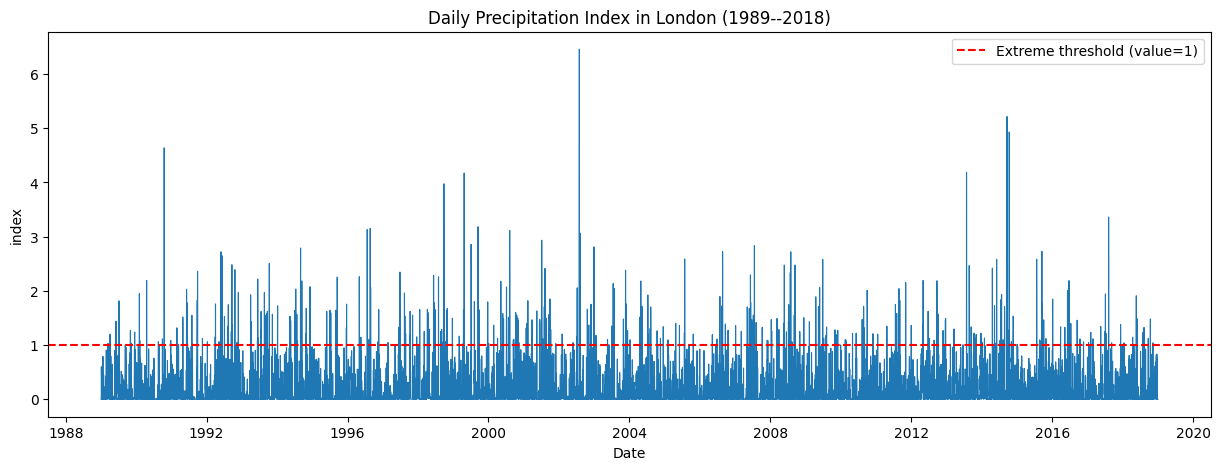

In [ ]:
data["date"] = pd.to_datetime(data["date"])
data = data.sort_values("date").reset_index(drop=True)

# Set date as index
data.set_index("date", inplace=True)

# ============================================
# 1. Raw time series plot
# ============================================
plt.figure(figsize=(15,5))
plt.plot(data.index, data["index_max"], linewidth=0.8)
plt.axhline(1.0, color="red", linestyle="--", label="Extreme threshold (value=1)")
plt.title("Daily Precipitation Index in London (1989--2018)")
#plt.title("Time Series (99th)")
plt.xlabel("Date")
plt.ylabel("index")
plt.legend()
plt.show()

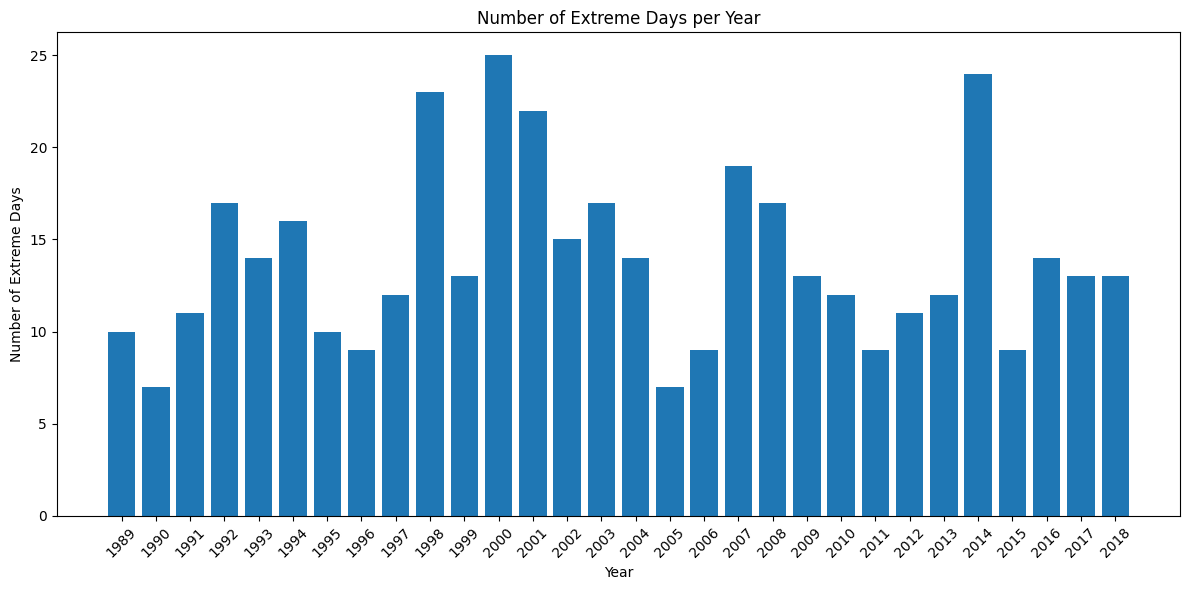

In [ ]:
extremes_per_year = data.groupby('year')['extreme'].sum()

plt.figure(figsize=(12, 6))

plt.bar(
    extremes_per_year.index,
    extremes_per_year.values
)

plt.title('Number of Extreme Days per Year')
plt.xlabel('Year')
plt.ylabel('Number of Extreme Days')

plt.xticks(extremes_per_year.index, rotation=45)

plt.tight_layout()


/tmp/ipykernel_3355/2586057587.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


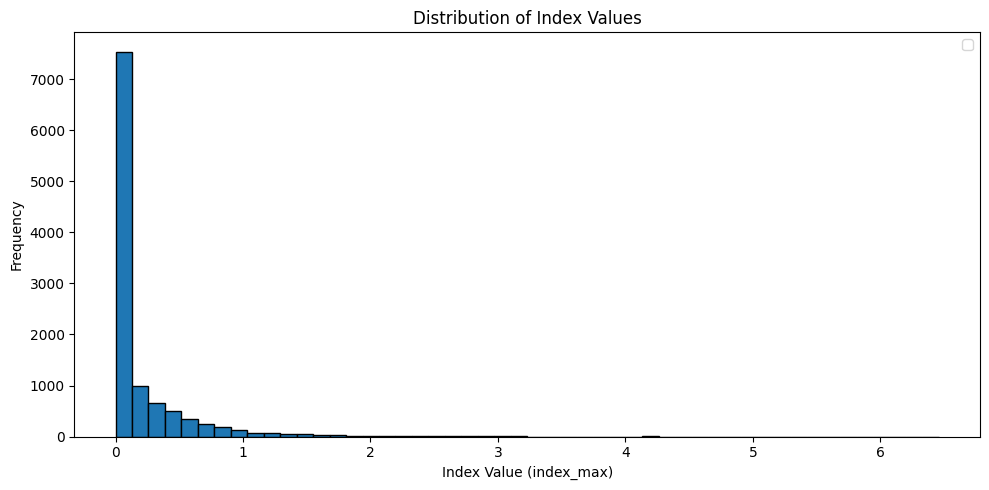

In [ ]:
# Histogram of index_max
plt.figure(figsize=(10, 5))
plt.hist(
    data["index_max"],
    bins=50,
    edgecolor="black"
)
plt.title("Distribution of Index Values")
plt.xlabel("Index Value (index_max)")
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()

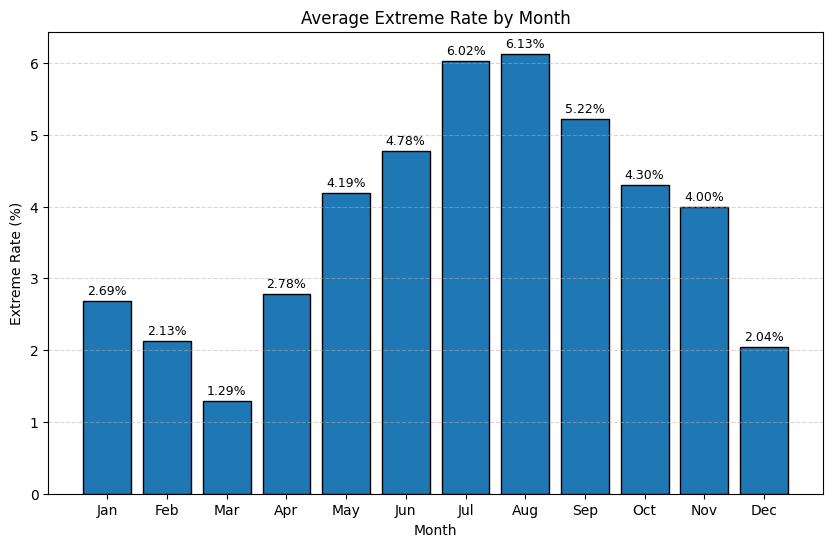

month
1     2.6882
2     2.1251
3     1.2903
4     2.7778
5     4.1935
6     4.7778
7     6.0215
8     6.1290
9     5.2222
10    4.3011
11    4.0000
12    2.0430
Name: extreme, dtype: float64


In [ ]:
# average month (%)
monthly_extreme_rate = data.groupby("month")["extreme"].mean() * 100

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    month_labels,
    monthly_extreme_rate.values,
    edgecolor="black"
)

# add %
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.05,
        f"{height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.title("Average Extreme Rate by Month")
plt.xlabel("Month")
plt.ylabel("Extreme Rate (%)")

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

print(monthly_extreme_rate.round(4))

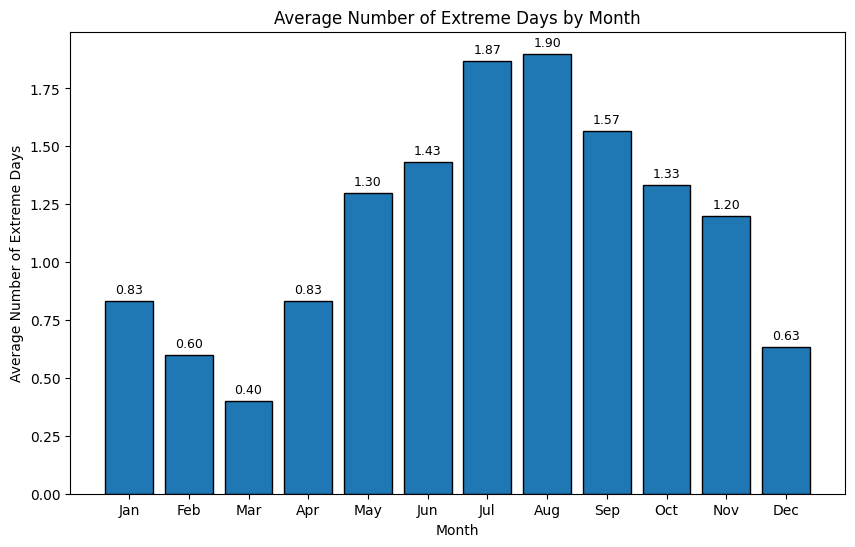

month
1     0.8333
2     0.6000
3     0.4000
4     0.8333
5     1.3000
6     1.4333
7     1.8667
8     1.9000
9     1.5667
10    1.3333
11    1.2000
12    0.6333
Name: extreme, dtype: float64


In [ ]:
yearly_monthly_extreme_count = (
    data.groupby(["year", "month"])["extreme"]
    .sum()
    .reset_index()
)

monthly_avg_extreme_count = (
    yearly_monthly_extreme_count.groupby("month")["extreme"]
    .mean()
)

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# make sure include all months
monthly_avg_extreme_count = monthly_avg_extreme_count.reindex(
    range(1, 13),
    fill_value=0
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    month_labels,
    monthly_avg_extreme_count.values,
    edgecolor="black"
)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.02,
        f"{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.title("Average Number of Extreme Days by Month")
plt.xlabel("Month")
plt.ylabel("Average Number of Extreme Days")

plt.show()

print(monthly_avg_extreme_count.round(4))

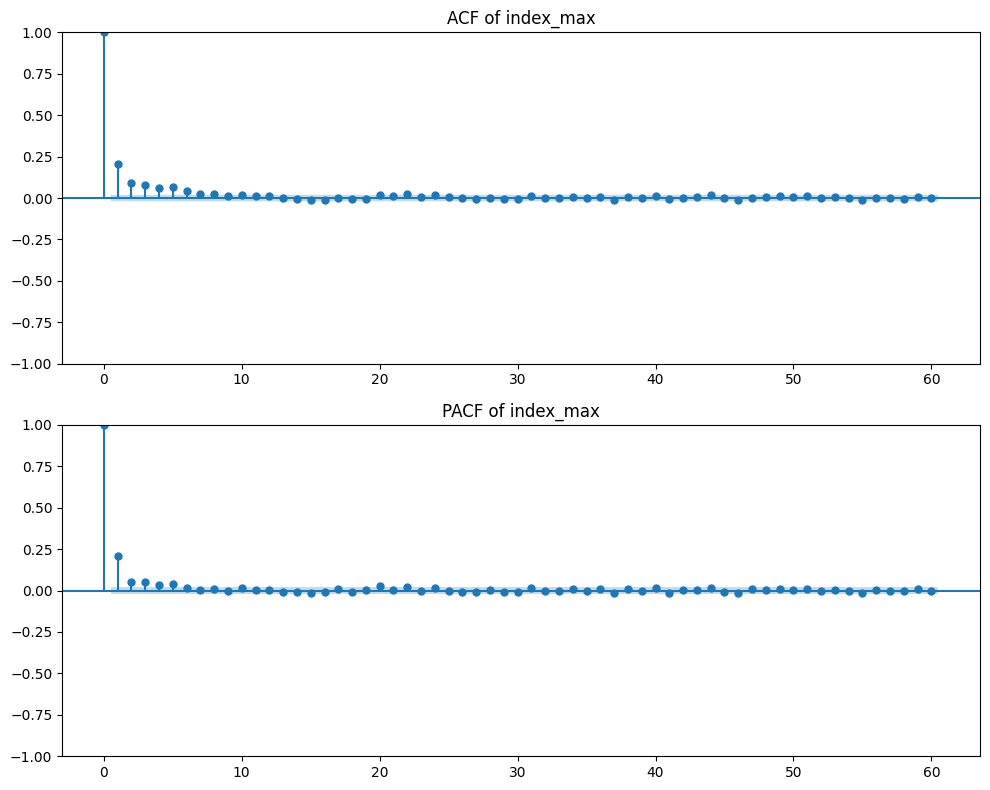

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# ACF
plot_acf(
    data["index_max"],
    lags=60,
    ax=axes[0]
)
axes[0].set_title("ACF of index_max")

# PACF
plot_pacf(
    data["index_max"],
    lags=60,
    ax=axes[1],
    method="ywm"
)
axes[1].set_title("PACF of index_max")

plt.tight_layout()
plt.show()

In [ ]:
for i in range(1, 15):
    data[f"lag{i}"] = data["index_max"].shift(i)
print(
    data[
        ["index_max"] +
        [f"lag{i}" for i in range(1, 15)]
    ].head(5)
)

               index_max          lag1          lag2          lag3      lag4  \
date                                                                           
1989-01-01  1.537327e-03           NaN           NaN           NaN       NaN   
1989-01-02  4.675346e-07  1.537327e-03           NaN           NaN       NaN   
1989-01-03  8.453556e-04  4.675346e-07  1.537327e-03           NaN       NaN   
1989-01-04  1.296219e-02  8.453556e-04  4.675346e-07  1.537327e-03       NaN   
1989-01-05  5.992232e-01  1.296219e-02  8.453556e-04  4.675346e-07  0.001537   

            lag5  lag6  lag7  lag8  lag9  lag10  lag11  lag12  lag13  lag14  
date                                                                         
1989-01-01   NaN   NaN   NaN   NaN   NaN    NaN    NaN    NaN    NaN    NaN  
1989-01-02   NaN   NaN   NaN   NaN   NaN    NaN    NaN    NaN    NaN    NaN  
1989-01-03   NaN   NaN   NaN   NaN   NaN    NaN    NaN    NaN    NaN    NaN  
1989-01-04   NaN   NaN   NaN   NaN   NaN    NaN  

In [ ]:
# Mean over the previous 7 days (excluding today)
data["mean_7d"] = (
    data["index_max"]
    .shift(1)
    .rolling(window=7, min_periods=7)
    .mean()
)

# Mean over the previous 14 days (excluding today)
data["mean_14d"] = (
    data["index_max"]
    .shift(1)
    .rolling(window=14, min_periods=14)
    .mean()
)

# Mean over the previous 30 days (excluding today)
data["mean_30d"] = (
    data["index_max"]
    .shift(1)
    .rolling(window=30, min_periods=30)
    .mean()
)
data.head(35)

,index_max,index_mean,n_cells,extreme,year,month,lag1,lag2,lag3,lag4,...,lag8,lag9,lag10,lag11,lag12,lag13,lag14,mean_7d,mean_14d,mean_30d
date,,,,,,,,,,,,,,,,,,,,,
1989-01-01,1.537327e-03,2.094822e-04,53,0,1989,1,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1989-01-02,4.675346e-07,3.556066e-08,53,0,1989,1,1.537327e-03,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1989-01-03,8.453556e-04,5.548581e-04,53,0,1989,1,4.675346e-07,1.537327e-03,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1989-01-04,1.296219e-02,7.791082e-03,53,0,1989,1,8.453556e-04,4.675346e-07,1.537327e-03,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1989-01-05,5.992232e-01,5.390699e-01,53,0,1989,1,1.296219e-02,8.453556e-04,4.675346e-07,1.537327e-03,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1989-01-06,3.576913e-01,4.354961e-02,53,0,1989,1,5.992232e-01,1.296219e-02,8.453556e-04,4.675346e-07,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1989-01-07,1.577087e-14,2.975636e-16,53,0,1989,1,3.576913e-01,5.992232e-01,1.296219e-02,8.453556e-04,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1989-01-08,1.705130e-28,3.217227e-30,53,0,1989,1,1.577087e-14,3.576913e-01,5.992232e-01,1.296219e-02,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.138894,NaN,NaN
1989-01-09,7.044747e-02,4.905670e-02,53,0,1989,1,1.705130e-28,1.577087e-14,3.576913e-01,5.992232e-01,...,1.537327e-03,NaN,NaN,NaN,NaN,NaN,NaN,0.138675,NaN,NaN


In [ ]:
# Maximum over the previous 7 days (excluding today)
data["max_7d"] = (
    data["index_max"]
    .shift(1)
    .rolling(window=7, min_periods=7)
    .max()
)

# Maximum over the previous 14 days (excluding today)
data["max_14d"] = (
    data["index_max"]
    .shift(1)
    .rolling(window=14, min_periods=14)
    .max()
)

print(
    data[
        [
            "index_max",
            "max_7d",
            "max_14d"
        ]
    ].head(20)
)

               index_max    max_7d   max_14d
date                                        
1989-01-01  1.537327e-03       NaN       NaN
1989-01-02  4.675346e-07       NaN       NaN
1989-01-03  8.453556e-04       NaN       NaN
1989-01-04  1.296219e-02       NaN       NaN
1989-01-05  5.992232e-01       NaN       NaN
1989-01-06  3.576913e-01       NaN       NaN
1989-01-07  1.577087e-14       NaN       NaN
1989-01-08  1.705130e-28  0.599223       NaN
1989-01-09  7.044747e-02  0.599223       NaN
1989-01-10  1.834686e-01  0.599223       NaN
1989-01-11  2.387772e-03  0.599223       NaN
1989-01-12  3.509786e-01  0.599223       NaN
1989-01-13  7.194860e-05  0.357691       NaN
1989-01-14  2.896641e-01  0.350979       NaN
1989-01-15  0.000000e+00  0.350979  0.599223
1989-01-16  3.257472e-02  0.350979  0.599223
1989-01-17  2.005026e-01  0.350979  0.599223
1989-01-18  0.000000e+00  0.350979  0.599223
1989-01-19  0.000000e+00  0.350979  0.599223
1989-01-20  1.422715e-02  0.289664  0.357691


In [ ]:
# Number of extreme days in the previous 7 days (excluding today)
data["extreme_count_7d"] = (
    data["extreme"]
    .shift(1)
    .rolling(window=7, min_periods=7)
    .sum()
)

# Number of extreme days in the previous 30 days (excluding today)
data["extreme_count_30d"] = (
    data["extreme"]
    .shift(1)
    .rolling(window=30, min_periods=30)
    .sum()
)

print(
    data[
        [
            "extreme",
            "extreme_count_7d",
            "extreme_count_30d"
        ]
    ].head(40)
)

            extreme  extreme_count_7d  extreme_count_30d
date                                                    
1989-01-01        0               NaN                NaN
1989-01-02        0               NaN                NaN
1989-01-03        0               NaN                NaN
1989-01-04        0               NaN                NaN
1989-01-05        0               NaN                NaN
1989-01-06        0               NaN                NaN
1989-01-07        0               NaN                NaN
1989-01-08        0               0.0                NaN
1989-01-09        0               0.0                NaN
1989-01-10        0               0.0                NaN
1989-01-11        0               0.0                NaN
1989-01-12        0               0.0                NaN
1989-01-13        0               0.0                NaN
1989-01-14        0               0.0                NaN
1989-01-15        0               0.0                NaN
1989-01-16        0            

In [ ]:
# Make sure the index is in date format
data.index = pd.to_datetime(data.index)

# day-of-year
data["day_of_year"] = data.index.dayofyear

# month
data["month"] = data.index.month

# sin/cos of day-of-year
data["sin_doy"] = np.sin(2 * np.pi * data["day_of_year"] / 365.25)
data["cos_doy"] = np.cos(2 * np.pi * data["day_of_year"] / 365.25)

# sin/cos of month
data["sin_month"] = np.sin(2 * np.pi * data["month"] / 12)
data["cos_month"] = np.cos(2 * np.pi * data["month"] / 12)

print(
    data[
        [
            "day_of_year",
            "month",
            "sin_doy",
            "cos_doy",
            "sin_month",
            "cos_month"
        ]
    ].head()
)

            day_of_year  month   sin_doy   cos_doy  sin_month  cos_month
date                                                                    
1989-01-01            1      1  0.017202  0.999852        0.5   0.866025
1989-01-02            2      1  0.034398  0.999408        0.5   0.866025
1989-01-03            3      1  0.051584  0.998669        0.5   0.866025
1989-01-04            4      1  0.068755  0.997634        0.5   0.866025
1989-01-05            5      1  0.085906  0.996303        0.5   0.866025


In [ ]:
previous_extreme99 = data["extreme"].shift(1).fillna(0).astype(int)

days_since_values = []
days_since = np.nan

for value in previous_extreme99:

    if value == 1:
        # Previous day was an extreme day
        days_since = 1

    elif pd.isna(days_since):
        # No previous extreme has yet been observed
        days_since_values.append(np.nan)
        continue

    else:
        days_since += 1

    days_since_values.append(days_since)

data["days_since_extreme99"] = days_since_values

# Optional:
# Cap very large values to reduce the influence of long gaps
data["days_since_extreme99"] = (
    data["days_since_extreme99"]
    .clip(upper=365)
)

In [ ]:
print(data.columns)
print(data.head())

Index(['index_max', 'index_mean', 'n_cells', 'extreme', 'year', 'month',
       'lag1', 'lag2', 'lag3', 'lag4', 'lag5', 'lag6', 'lag7', 'lag8', 'lag9',
       'lag10', 'lag11', 'lag12', 'lag13', 'lag14', 'mean_7d', 'mean_14d',
       'mean_30d', 'max_7d', 'max_14d', 'extreme_count_7d',
       'extreme_count_30d', 'day_of_year', 'sin_doy', 'cos_doy', 'sin_month',
       'cos_month', 'days_since_extreme99'],
      dtype='object')
               index_max    index_mean  n_cells  extreme  year  month  \
date                                                                    
1989-01-01  1.537327e-03  2.094822e-04       53        0  1989      1   
1989-01-02  4.675346e-07  3.556066e-08       53        0  1989      1   
1989-01-03  8.453556e-04  5.548581e-04       53        0  1989      1   
1989-01-04  1.296219e-02  7.791082e-03       53        0  1989      1   
1989-01-05  5.992232e-01  5.390699e-01       53        0  1989      1   

                    lag1          lag2          lag3    

In [ ]:
train = data[(data["year"] >= 1989) & (data["year"] <= 2012)].copy()
#train = data[(data["year"] >= 1989) & (data["year"] <= 2008)].copy()

#test = data[(data["year"] >= 2009) & (data["year"] <= 2018)].copy()
test = data[(data["year"] >= 2013) & (data["year"] <= 2018)].copy()

print("Training set shape:", train.shape)
print("Test set shape:", test.shape)

print("\nTraining years:")
print(train["year"].min(), "-", train["year"].max())

print("\nTest years:")
print(test["year"].min(), "-", test["year"].max())

Training set shape: (8766, 33)
Test set shape: (2191, 33)

Training years:
1989 - 2012

Test years:
2013 - 2018


# GP Classifier

In [ ]:
features = [
    'year', 'month',
    'lag1', 'lag2', 'lag3', 'lag4', 'lag5', 'lag6', 'lag7',
    'lag8', 'lag9', 'lag10', 'lag11', 'lag12', 'lag13', 'lag14',
    'mean_7d', 'mean_14d', 'mean_30d',
    'max_7d', 'max_14d',
    'extreme_count_7d', 'extreme_count_30d',
    'day_of_year',
    'sin_doy', 'cos_doy',
    'sin_month', 'cos_month',
    'days_since_extreme99'
]
corr_matrix = train[features].corr()
corr_matrix.head()

,year,month,lag1,lag2,lag3,lag4,lag5,lag6,lag7,lag8,...,max_7d,max_14d,extreme_count_7d,extreme_count_30d,day_of_year,sin_doy,cos_doy,sin_month,cos_month,days_since_extreme99
year,1.000000,-0.000195,0.007764,0.007999,0.007951,0.007969,0.007619,0.007591,0.007327,0.007138,...,0.007544,-0.000394,0.005548,0.003386,0.000257,0.000003,0.000210,0.000183,0.000105,-0.010664
month,-0.000195,1.000000,0.037504,0.034580,0.033367,0.033994,0.035501,0.036682,0.036589,0.035432,...,0.096201,0.132590,0.085858,0.186146,0.996501,-0.780616,0.003516,-0.760955,0.209058,-0.217697
lag1,0.007764,0.037504,1.000000,0.217181,0.093145,0.082473,0.072713,0.074992,0.043729,0.034574,...,0.429495,0.300484,0.359838,0.164515,0.036548,-0.035335,-0.029095,-0.044167,-0.018148,-0.164827
lag2,0.007999,0.034580,0.217181,1.000000,0.217209,0.093137,0.082551,0.072716,0.075066,0.043787,...,0.454640,0.319646,0.394143,0.184270,0.032813,-0.035815,-0.028424,-0.043094,-0.017068,-0.167793
lag3,0.007951,0.033367,0.093145,0.217209,1.000000,0.217225,0.093064,0.082548,0.072643,0.075003,...,0.454355,0.325300,0.391799,0.189841,0.031609,-0.036293,-0.027889,-0.043397,-0.018154,-0.168001


In [ ]:
threshold = 0.70

corr_abs = corr_matrix.abs()

upper = corr_abs.where(
    np.triu(np.ones(corr_abs.shape), k=1).astype(bool)
)

high_corr_pairs = []

for col in upper.columns:
    for row in upper.index:

        corr_value = upper.loc[row, col]

        if pd.notna(corr_value) and corr_value > threshold:

            high_corr_pairs.append({
                "Feature_1": row,
                "Feature_2": col,
                "Correlation": round(corr_value, 3)
            })

high_corr_df = pd.DataFrame(high_corr_pairs)

high_corr_df = high_corr_df.sort_values(
    by="Correlation",
    ascending=False
)

print(high_corr_df)

      Feature_1          Feature_2  Correlation
8         month        day_of_year        0.997
14      cos_doy          cos_month        0.954
13      sin_doy          sin_month        0.954
2       mean_7d             max_7d        0.891
3      mean_14d            max_14d        0.820
7      mean_30d  extreme_count_30d        0.784
6        max_7d   extreme_count_7d        0.783
9         month            sin_doy        0.781
10  day_of_year            sin_doy        0.780
5       mean_7d   extreme_count_7d        0.776
0       mean_7d           mean_14d        0.773
11        month          sin_month        0.761
12  day_of_year          sin_month        0.759
4        max_7d            max_14d        0.724
1      mean_14d           mean_30d        0.710


In [ ]:
# -----------------------------
# 1. Candidate input features
# -----------------------------

selected_features_gpc_ard = [
    'year', 'month',
    'lag1', 'lag2', 'lag3', 'lag4', 'lag5', 'lag6', 'lag7',
    'lag8', 'lag9', 'lag10', 'lag11', 'lag12', 'lag13', 'lag14',
    'mean_7d', 'mean_14d', 'mean_30d',
    'max_7d', 'max_14d',
    'extreme_count_7d', 'extreme_count_30d',
    'day_of_year',
    'sin_doy', 'cos_doy',
    'sin_month', 'cos_month',
    'days_since_extreme99'
]

target = "extreme"
n_total = 1000
random_state = 42

In [ ]:
# -----------------------------
# 2. Clean training data
# -----------------------------

train_clean_ard = train[
    selected_features_gpc_ard + [target]
].dropna().copy()

# -----------------------------
# 3. Stratified subsampling
#    Keep all extreme days
# -----------------------------

extreme_train_ard = train_clean_ard[
    train_clean_ard[target] == 1
]

non_extreme_train_ard = train_clean_ard[
    train_clean_ard[target] == 0
]

n_extreme_ard = len(extreme_train_ard)
n_non_extreme_needed_ard = n_total - n_extreme_ard

if n_non_extreme_needed_ard < 0:
    raise ValueError(
        f"There are {n_extreme_ard} extreme days, "
        f"which exceeds n_total={n_total}."
    )

if n_non_extreme_needed_ard > len(non_extreme_train_ard):
    raise ValueError(
        f"Need {n_non_extreme_needed_ard} non-extreme days, "
        f"but only {len(non_extreme_train_ard)} are available."
    )

non_extreme_sample_ard = non_extreme_train_ard.sample(
    n=n_non_extreme_needed_ard,
    random_state=random_state
)

train_subsample_ard = pd.concat(
    [extreme_train_ard, non_extreme_sample_ard],
    axis=0
).sample(
    frac=1,
    random_state=random_state
).reset_index(drop=True)

print("ARD subsample class counts:")
print(train_subsample_ard[target].value_counts())

# -----------------------------
# 4. Create X and y
# -----------------------------

X_train_ard = train_subsample_ard[selected_features_gpc_ard]
y_train_ard = train_subsample_ard[target].astype(int)

# -----------------------------
# 5. Standardize features
# -----------------------------

scaler_gpc_ard = StandardScaler()

X_train_ard_scaled = scaler_gpc_ard.fit_transform(
    X_train_ard
)

# -----------------------------
# 6. ARD Matern kernel
#    One length scale per feature
# -----------------------------

n_features_ard = len(selected_features_gpc_ard)

initial_length_scales = np.ones(n_features_ard)

from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel as C

kernel_ard = (
    C(1.0, (1e-3, 1e3))
    * Matern(
        length_scale=initial_length_scales,
        length_scale_bounds=(1e-2, 1e2),
        nu=2.5
    )
    + WhiteKernel(
        noise_level=1e-5,
        noise_level_bounds=(1e-8, 1e-1)
    )
)


# -----------------------------
# 7. Fit ARD GPC
# -----------------------------

gpc_ard = GaussianProcessClassifier(
    kernel=kernel_ard,
    random_state=random_state,
    n_restarts_optimizer=3,
    max_iter_predict=100
)

gpc_ard.fit(
    X_train_ard_scaled,
    y_train_ard
)

print("\nFitted ARD GPC kernel:")
print(gpc_ard.kernel_)

In [ ]:
# -----------------------------
# 8. Extract ARD length scales
# -----------------------------

# Kernel structure:
# ConstantKernel * Matern + WhiteKernel
fitted_matern = gpc_ard.kernel_.k1.k2

ard_length_scales = np.asarray(
    fitted_matern.length_scale
)

ard_results = pd.DataFrame({
    "Feature": selected_features_gpc_ard,
    "Length_scale": ard_length_scales
})

# A simple relevance score:
# smaller length scale -> larger relevance
ard_results["Relevance_score"] = (
    1.0 / ard_results["Length_scale"]
)

ard_results = ard_results.sort_values(
    by="Length_scale",
    ascending=True
).reset_index(drop=True)

print("\nARD feature ranking:")
print(ard_results)

In [ ]:
selected_features_gpc = [
    'lag1', 'lag2', 'lag4', 'lag5', 'lag6', 'lag13', 'lag14',
    'extreme_count_30d',
    'cos_doy', 'sin_month'
]

target = 'extreme'

In [ ]:
# -----------------------------
# 2. Keep only complete rows in training set
# -----------------------------

train_clean = train[selected_features_gpc + [target]].dropna().copy()

# -----------------------------
# 3. Stratified subsampling
#    Keep all extreme days
#    Randomly sample non-extreme days
# -----------------------------

n_total = 1000
random_state = 42

extreme_train = train_clean[train_clean[target] == 1]
non_extreme_train = train_clean[train_clean[target] == 0]

n_extreme = len(extreme_train)
n_non_extreme_needed = n_total - n_extreme

if n_non_extreme_needed < 0:
    raise ValueError(
        f"There are {n_extreme} extreme days, which is more than n_total={n_total}."
    )

if n_non_extreme_needed > len(non_extreme_train):
    raise ValueError(
        f"Need {n_non_extreme_needed} non-extreme days, "
        f"but only {len(non_extreme_train)} are available."
    )

non_extreme_sample = non_extreme_train.sample(
    n=n_non_extreme_needed,
    random_state=random_state
)

train_subsample = pd.concat(
    [extreme_train, non_extreme_sample],
    axis=0
)

train_subsample = train_subsample.sample(
    frac=1,
    random_state=random_state
).reset_index(drop=True)

print("Subsample class counts:")
print(train_subsample[target].value_counts())

print("\nSubsample class proportions:")
print(train_subsample[target].value_counts(normalize=True))

# -----------------------------
# 4. Create X and y
# -----------------------------

X_train_sub = train_subsample[selected_features_gpc]
y_train_sub = train_subsample[target].astype(int)

# -----------------------------
# 5. Standardize input features
#    Important for Gaussian Process kernels
# -----------------------------

scaler_gpc = StandardScaler()

X_train_sub_scaled = scaler_gpc.fit_transform(X_train_sub)



Subsample class counts:
extreme
0    668
1    332
Name: count, dtype: int64

Subsample class proportions:
extreme
0    0.668
1    0.332
Name: proportion, dtype: float64


In [ ]:
# -----------------------------
# 6. Define GPC with Matern kernel + WhiteKernel
#    nu = 2.5
# -----------------------------

kernel = (
    C(1.0, (1e-3, 1e3))
    * Matern(
        length_scale=1.0,
        length_scale_bounds=(1e-2, 1e2),
        nu=2.5
    )
    + WhiteKernel(
        noise_level=1e-5,
        noise_level_bounds=(1e-8, 1e-1)
    )
)

gpc = GaussianProcessClassifier(
    kernel=kernel,
    random_state=random_state,
    n_restarts_optimizer=3
)

# -----------------------------
# 7. Fit model
# -----------------------------

gpc.fit(X_train_sub_scaled, y_train_sub)

print("\nFitted GPC kernel:")
print(gpc.kernel_)


Fitted GPC kernel:
1.39**2 * Matern(length_scale=6.63, nu=2.5) + WhiteKernel(noise_level=4.06e-07)


In [ ]:
# -----------------------------
# 1. Use the full training set
# -----------------------------

target = "extreme"

train_eval = train[selected_features_gpc + [target]].dropna().copy()

X_train_full = train_eval[selected_features_gpc]
y_train_full = train_eval[target].astype(int)

# Use the scaler fitted on the GPC subsample
X_train_full_scaled = scaler_gpc.transform(X_train_full)

# -----------------------------
# 2. Probability predictions
# -----------------------------

p_gpc = gpc.predict_proba(X_train_full_scaled)[:, 1]

# Default threshold
threshold = 0.6
y_pred_gpc = (p_gpc >= threshold).astype(int)

train_eval["p_gpc"] = p_gpc
train_eval["pred_gpc"] = y_pred_gpc

# -----------------------------
# 3. Compute metrics
# -----------------------------

roc_auc = roc_auc_score(y_train_full, p_gpc)
pr_auc = average_precision_score(y_train_full, p_gpc)
brier = brier_score_loss(y_train_full, p_gpc)


print("Training performance on full training set")
print(f"ROC-AUC : {roc_auc:.4f}")
print(f"PR-AUC  : {pr_auc:.4f}")
print(f"Brier   : {brier:.4f}")

Training performance on full training set
ROC-AUC : 0.7110
PR-AUC  : 0.1015
Brier   : 0.1194


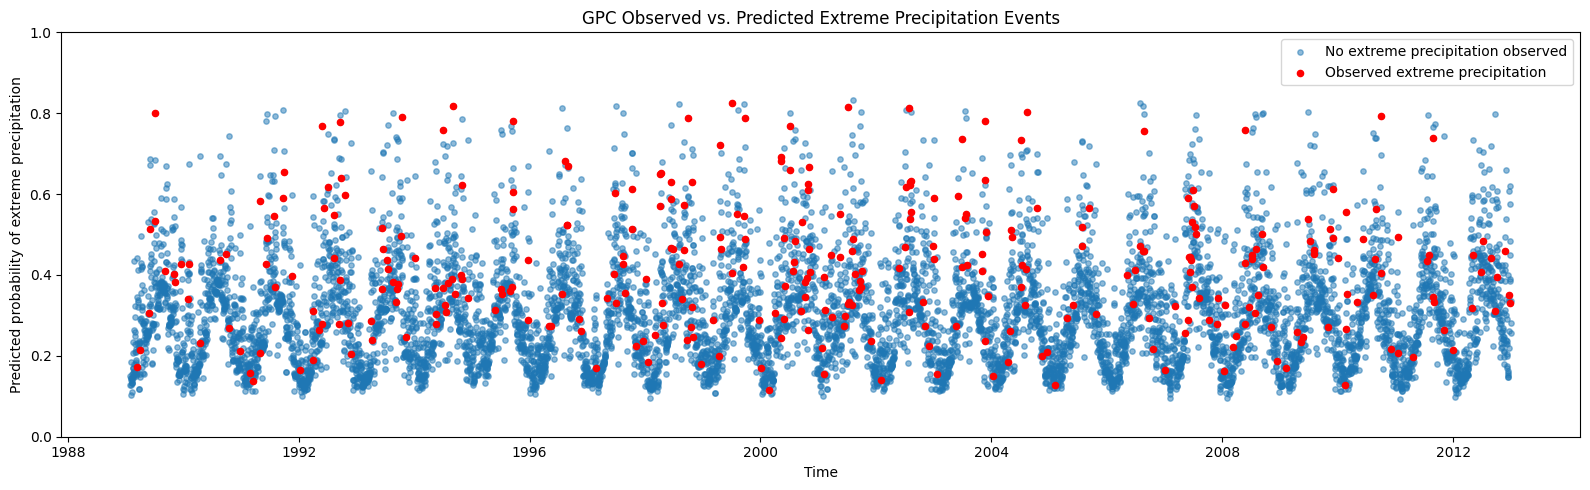

In [ ]:
plt.figure(figsize=(16, 5))

plt.scatter(
    train_eval.index,
    train_eval["p_gpc"],
    label="No extreme precipitation observed",
    s=15,
    alpha=0.5,
    zorder=2
)

extreme_mask = train_eval[target] == 1

plt.scatter(
    train_eval.index[extreme_mask],
    train_eval.loc[extreme_mask, "p_gpc"],
    color="red",
    label="Observed extreme precipitation",
    s=20,
    alpha=1,
    zorder=3
)



plt.xlabel("Time")
plt.ylabel("Predicted probability of extreme precipitation")
plt.title("GPC Observed vs. Predicted Extreme Precipitation Events")
plt.legend(
    loc='center left',
    bbox_to_anchor=(1.02, 0.7)
)

plt.ylim(0, 1)


plt.legend(
    loc='upper right'
)

plt.tight_layout()

plt.show()

In [ ]:
# -----------------------------
# 1. Use the full test set
# -----------------------------

test_eval = test[selected_features_gpc + [target]].dropna().copy()

X_test_full = test_eval[selected_features_gpc]
y_test_full = test_eval[target].astype(int)

# Use scaler fitted on GPC training subsample
X_test_full_scaled = scaler_gpc.transform(X_test_full)

# -----------------------------
# 2. Probability predictions
# -----------------------------

p_gpc_test = gpc.predict_proba(X_test_full_scaled)[:, 1]

#threshold = 0.6
threshold = 0.7
y_pred_gpc_test = (p_gpc_test >= threshold).astype(int)

test_eval["p_gpc"] = p_gpc_test
test_eval["pred_gpc"] = y_pred_gpc_test

# -----------------------------
# 3. Compute test metrics
# -----------------------------

roc_auc_gpc_test = roc_auc_score(y_test_full, p_gpc_test)
pr_auc_gpc_test = average_precision_score(y_test_full, p_gpc_test)
brier_gpc_test = brier_score_loss(y_test_full, p_gpc_test)
f1_gpc_test = f1_score(y_test_full, y_pred_gpc_test)

print("GPC performance on full test set")
print("--------------------------------")
print(f"Threshold: {threshold}")
print(f"ROC-AUC : {roc_auc_gpc_test:.4f}")
print(f"PR-AUC  : {pr_auc_gpc_test:.4f}")
print(f"Brier   : {brier_gpc_test:.4f}")
print(f"F1      : {f1_gpc_test:.4f}")



GPC performance on full test set
--------------------------------
Threshold: 0.7
ROC-AUC : 0.6857
PR-AUC  : 0.0910
Brier   : 0.1192
F1      : 0.1062


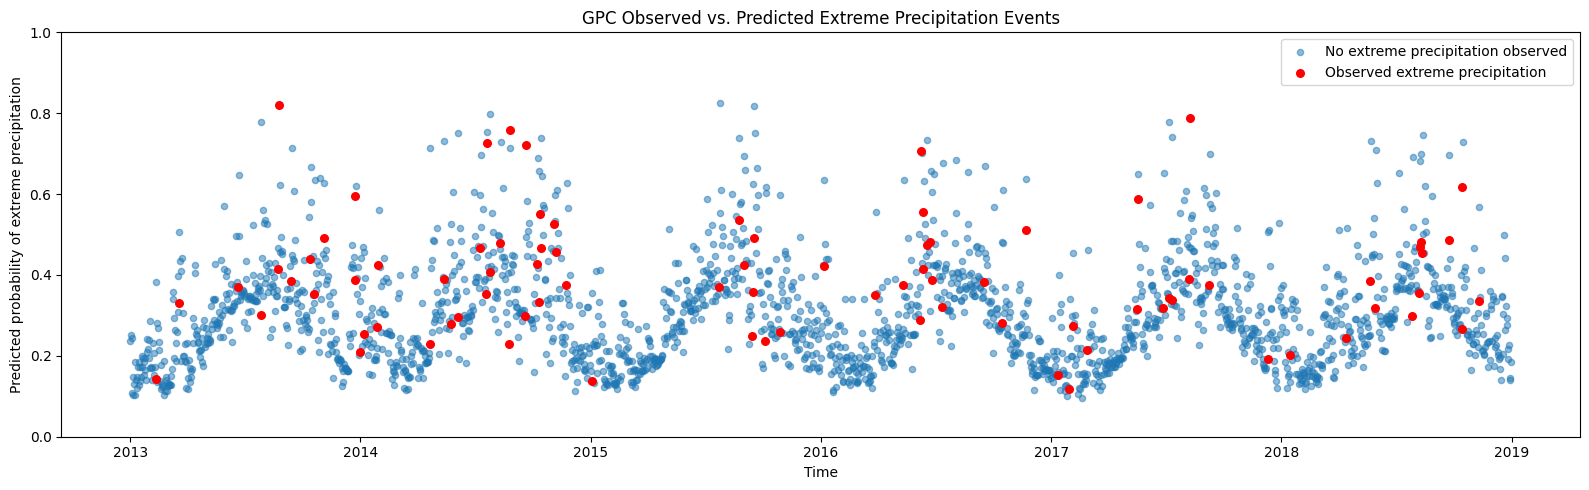

In [ ]:
plt.figure(figsize=(16, 5))

plt.scatter(
    test_eval.index,
    test_eval["p_gpc"],
    label="No extreme precipitation observed",
    s=20,
    alpha=0.5,
    zorder=2
)

extreme_mask = test_eval[target] == 1

plt.scatter(
    test_eval.index[extreme_mask],
    test_eval.loc[extreme_mask, "p_gpc"],
    color="red",
    label="Observed extreme precipitation",
    s=30,
    alpha=1,
    zorder=3
)

plt.xlabel("Time")
plt.ylabel("Predicted probability of extreme precipitation")
plt.title("GPC Observed vs. Predicted Extreme Precipitation Events")

plt.ylim(0, 1)


plt.legend(
    loc='upper right'
)

plt.tight_layout()
plt.show()

Isotonic Calibration

GPC fitting samples: 7275
Calibration samples: 1461
Full training samples: 8736
Test samples: 2191

Extreme event rates:
GPC fitting: 0.03945017182130584
Calibration: 0.030800821355236138
Full training: 0.038003663003663

GPC subsample size: 1000
Extreme samples: 287
Subsample extreme rate: 0.287

Fitted GPC kernel:
1.94**2 * Matern(length_scale=11.1, nu=2.5) + WhiteKernel(noise_level=2e-06)

Isotonic calibration fitted successfully.

FULL TRAINING PERIOD: 1989-2012
               ROC-AUC    PR-AUC  Brier Score
Raw GPC       0.700034  0.101092     0.095550
Isotonic GPC  0.693683  0.080171     0.035713

Original extreme event prevalence: 0.038004


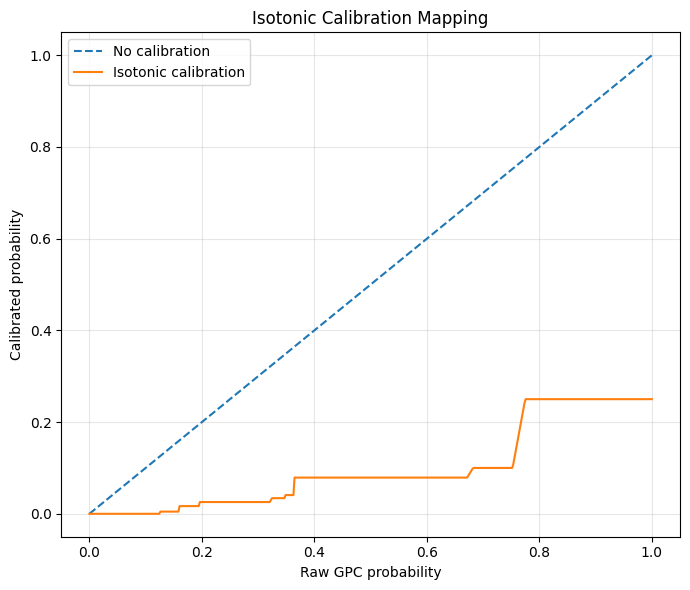


Prediction preview:


,extreme,p_gpc_raw,p_gpc_calibrated
date,,,
1989-01-31,0,0.129267,0.004785
1989-02-01,0,0.138541,0.004785
1989-02-02,0,0.128067,0.004785
1989-02-03,0,0.131826,0.004785
1989-02-04,0,0.111257,0.000000
1989-02-05,0,0.136435,0.004785
1989-02-06,0,0.130339,0.004785
1989-02-07,0,0.119122,0.000000
1989-02-08,0,0.124670,0.000000


In [ ]:
# ============================================================
# 2. Parameters and selected features
# ============================================================

random_state = 42
target_n = 1000

selected_features_gpc = [
    'lag1', 'lag2', 'lag4', 'lag5', 'lag6',
    'lag13', 'lag14',
    'extreme_count_30d',
    'cos_doy', 'sin_month'
]

target = 'extreme'

# ============================================================
# 3. Define training and test periods
# ============================================================

train = data[
    (data["year"] >= 1989) &
    (data["year"] <= 2012)
].copy()

test = data[
    (data["year"] >= 2013) &
    (data["year"] <= 2018)
].copy()

# Split the original training period:
# 1989-2008: fit GPC
# 2009-2012: fit isotonic calibration

gpc_train = train[
    (train["year"] >= 1989) &
    (train["year"] <= 2008)
].copy()

calibration_train = train[
    (train["year"] >= 2009) &
    (train["year"] <= 2012)
].copy()

# Remove missing values in required columns
required_cols = selected_features_gpc + [target]

gpc_train = gpc_train.dropna(
    subset=required_cols
).copy()

calibration_train = calibration_train.dropna(
    subset=required_cols
).copy()

train_clean = train.dropna(
    subset=required_cols
).copy()

test_clean = test.dropna(
    subset=required_cols
).copy()

print("GPC fitting samples:", len(gpc_train))
print("Calibration samples:", len(calibration_train))
print("Full training samples:", len(train_clean))
print("Test samples:", len(test_clean))

print("\nExtreme event rates:")
print("GPC fitting:", gpc_train[target].mean())
print("Calibration:", calibration_train[target].mean())
print("Full training:", train_clean[target].mean())

# ============================================================
# 4. Stratified undersampling for GPC fitting
# ============================================================

extreme_train = gpc_train[
    gpc_train[target] == 1
]

non_extreme_train = gpc_train[
    gpc_train[target] == 0
]

n_extreme = len(extreme_train)
n_non_extreme_needed = target_n - n_extreme

if n_non_extreme_needed < 0:
    raise ValueError(
        "Number of extreme samples exceeds target_n."
    )

if n_non_extreme_needed > len(non_extreme_train):
    raise ValueError(
        "Not enough non-extreme samples for target_n."
    )

non_extreme_sample = non_extreme_train.sample(
    n=n_non_extreme_needed,
    random_state=random_state
)

train_sub = pd.concat([
    extreme_train,
    non_extreme_sample
]).sample(
    frac=1,
    random_state=random_state
)

print("\nGPC subsample size:", len(train_sub))
print("Extreme samples:", train_sub[target].sum())
print("Subsample extreme rate:", train_sub[target].mean())

# ============================================================
# 5. Prepare features and standardise
# ============================================================

X_train_sub = train_sub[selected_features_gpc]
y_train_sub = train_sub[target].astype(int)

X_cal = calibration_train[selected_features_gpc]
y_cal = calibration_train[target].astype(int)

X_train_full = train_clean[selected_features_gpc]
y_train_full = train_clean[target].astype(int)

scaler = StandardScaler()

# Fit scaler ONLY on the GPC fitting subsample
X_train_sub_scaled = scaler.fit_transform(X_train_sub)

X_cal_scaled = scaler.transform(X_cal)
X_train_full_scaled = scaler.transform(X_train_full)

# ============================================================
# 6. Define Gaussian Process Classifier
#    Matern nu=2.5 + WhiteKernel
# ============================================================

kernel = (
    C(1.0, (1e-3, 1e3))
    * Matern(
        length_scale=1.0,
        length_scale_bounds=(1e-2, 1e2),
        nu=2.5
    )
    + WhiteKernel(
        noise_level=1e-5,
        noise_level_bounds=(1e-8, 1e-1)
    )
)

gpc = GaussianProcessClassifier(
    kernel=kernel,
    random_state=random_state,
    n_restarts_optimizer=3,
    max_iter_predict=100
)

# ============================================================
# 7. Fit GPC
# ============================================================

gpc.fit(
    X_train_sub_scaled,
    y_train_sub
)

print("\nFitted GPC kernel:")
print(gpc.kernel_)

# ============================================================
# 8. Predict probabilities on calibration data
# ============================================================

# These predictions are out-of-sample for the GPC
p_cal_raw = gpc.predict_proba(
    X_cal_scaled
)[:, 1]

# ============================================================
# 9. Fit Isotonic Regression
# ============================================================

isotonic_model = IsotonicRegression(
    y_min=0.0,
    y_max=1.0,
    out_of_bounds="clip"
)

isotonic_model.fit(
    p_cal_raw,
    y_cal
)

# Calibration-set probabilities (for illustration only)
p_cal_calibrated = isotonic_model.predict(
    p_cal_raw
)

print("\nIsotonic calibration fitted successfully.")

# ============================================================
# 10. Predict on the FULL training period (1989-2012)
# ============================================================

p_train_raw = gpc.predict_proba(
    X_train_full_scaled
)[:, 1]

p_train_calibrated = isotonic_model.predict(
    p_train_raw
)

# ============================================================
# 11. Evaluate full training-period performance
# ============================================================

def evaluate_probabilities(y_true, probabilities):

    return {
        "ROC-AUC": roc_auc_score(
            y_true,
            probabilities
        ),
        "PR-AUC": average_precision_score(
            y_true,
            probabilities
        ),
        "Brier Score": brier_score_loss(
            y_true,
            probabilities
        )
    }


results = pd.DataFrame({
    "Raw GPC": evaluate_probabilities(
        y_train_full,
        p_train_raw
    ),
    "Isotonic GPC": evaluate_probabilities(
        y_train_full,
        p_train_calibrated
    )
}).T

print("\n===================================")
print("FULL TRAINING PERIOD: 1989-2012")
print("===================================")

print(results.round(6))

print("\nOriginal extreme event prevalence:",
      round(y_train_full.mean(), 6))

# ============================================================
# 12. Plot isotonic calibration mapping
# ============================================================

probability_grid = np.linspace(0, 1, 500)

calibrated_grid = isotonic_model.predict(
    probability_grid
)

plt.figure(figsize=(7, 6))

plt.plot(
    probability_grid,
    probability_grid,
    "--",
    label="No calibration"
)

plt.plot(
    probability_grid,
    calibrated_grid,
    label="Isotonic calibration"
)

plt.xlabel("Raw GPC probability")
plt.ylabel("Calibrated probability")
plt.title("Isotonic Calibration Mapping")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 13. Save full training predictions
# ============================================================

train_predictions = train_clean.copy()

train_predictions["p_gpc_raw"] = p_train_raw
train_predictions["p_gpc_calibrated"] = p_train_calibrated

print("\nPrediction preview:")

display(
    train_predictions[
        [target, "p_gpc_raw", "p_gpc_calibrated"]
    ].head(10)
)

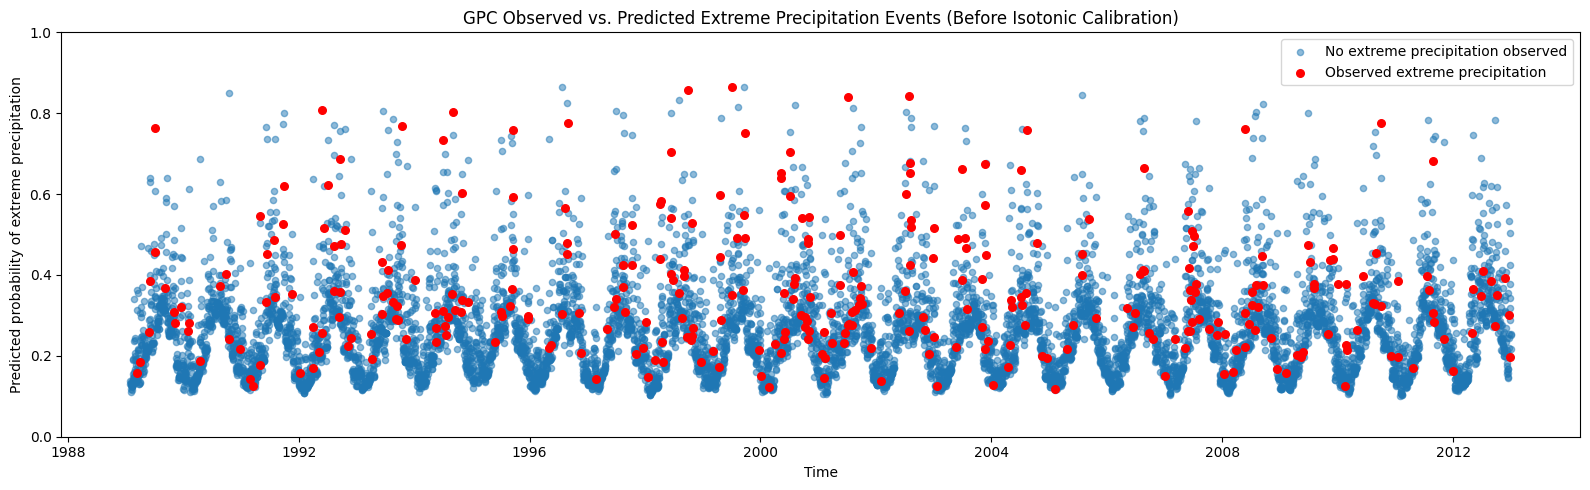

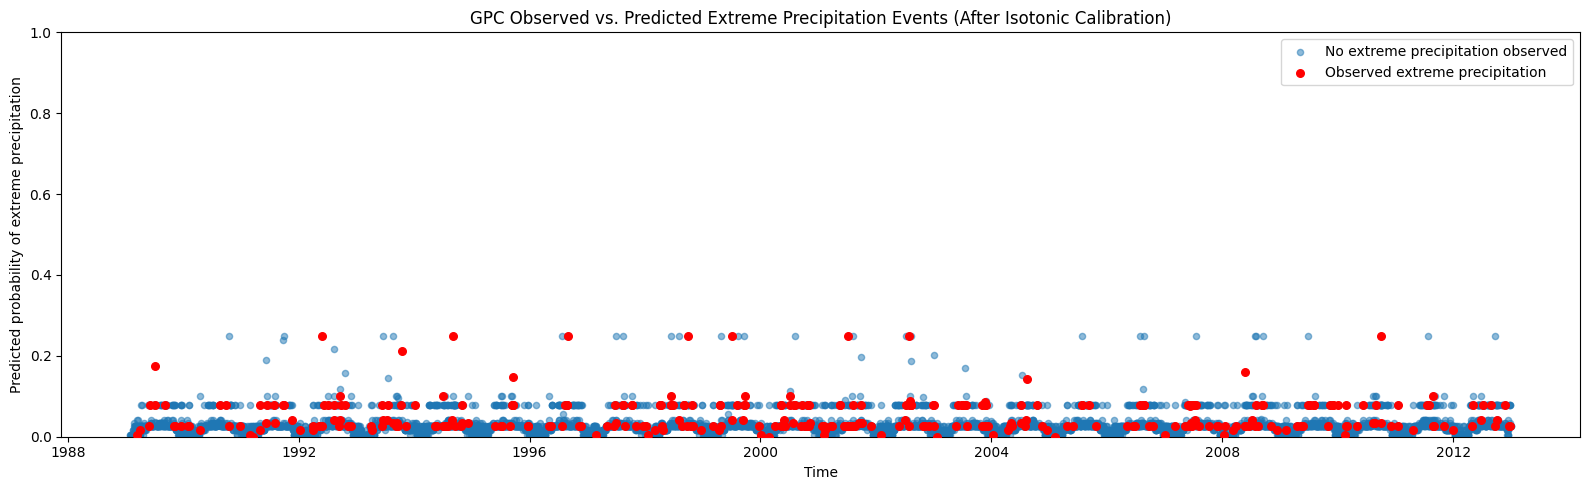

In [ ]:
# ============================================================
# 1. Raw GPC: Before Isotonic Calibration
# ============================================================

extreme_mask = train_predictions[target] == 1

plt.figure(figsize=(16, 5))

plt.scatter(
    train_predictions.index,
    train_predictions["p_gpc_raw"],
    label="No extreme precipitation observed",
    s=20,
    alpha=0.5,
    zorder=2
)

plt.scatter(
    train_predictions.index[extreme_mask],
    train_predictions.loc[extreme_mask, "p_gpc_raw"],
    color="red",
    label="Observed extreme precipitation",
    s=30,
    alpha=1,
    zorder=3
)

plt.xlabel("Time")
plt.ylabel("Predicted probability of extreme precipitation")
plt.title(
    "GPC Observed vs. Predicted Extreme Precipitation Events "
    "(Before Isotonic Calibration)"
)

plt.ylim(0, 1)
plt.legend(loc="upper right")

plt.tight_layout()
plt.show()


# ============================================================
# 2. Calibrated GPC: After Isotonic Calibration
# ============================================================

plt.figure(figsize=(16, 5))

plt.scatter(
    train_predictions.index,
    train_predictions["p_gpc_calibrated"],
    label="No extreme precipitation observed",
    s=20,
    alpha=0.5,
    zorder=2
)

plt.scatter(
    train_predictions.index[extreme_mask],
    train_predictions.loc[extreme_mask, "p_gpc_calibrated"],
    color="red",
    label="Observed extreme precipitation",
    s=30,
    alpha=1,
    zorder=3
)

plt.xlabel("Time")
plt.ylabel("Predicted probability of extreme precipitation")
plt.title(
    "GPC Observed vs. Predicted Extreme Precipitation Events "
    "(After Isotonic Calibration)"
)

plt.ylim(0, 1)
plt.legend(loc="upper right")

plt.tight_layout()
plt.show()

# GP Regressor

In [ ]:
# ============================================================
# 2. Define candidate features and target
# ============================================================

selected_features_gpr_ard = [
    'year', 'month',
    'lag1', 'lag2', 'lag3', 'lag4', 'lag5', 'lag6', 'lag7',
    'lag8', 'lag9', 'lag10', 'lag11', 'lag12', 'lag13', 'lag14',
    'mean_7d', 'mean_14d', 'mean_30d',
    'max_7d', 'max_14d',
    'extreme_count_7d', 'extreme_count_30d',
    'day_of_year',
    'sin_doy', 'cos_doy',
    'sin_month', 'cos_month',
    'days_since_extreme99'
]

target_gpr = "index_max"

random_state = 42

In [ ]:
# ============================================================
# 3. Keep only extreme precipitation days
#    Stage 2: conditional intensity regression
# ============================================================

train_clean_gpr_ard = train[
    selected_features_gpr_ard + [target_gpr, "extreme"]
].dropna().copy()

extreme_train_gpr_ard = train_clean_gpr_ard[
    train_clean_gpr_ard["extreme"] == 1
].copy()

print("Total training samples:", len(train_clean_gpr_ard))
print("Extreme precipitation samples:", len(extreme_train_gpr_ard))

# ============================================================
# 4. Create X and y
# ============================================================

X_train_gpr_ard = extreme_train_gpr_ard[
    selected_features_gpr_ard
]

y_train_gpr_ard = np.log1p(
    extreme_train_gpr_ard[target_gpr]
)

print("\nNumber of features:", X_train_gpr_ard.shape[1])
print("Number of training samples:", X_train_gpr_ard.shape[0])

# ============================================================
# 5. Standardize features
# ============================================================

scaler_gpr_ard = StandardScaler()

X_train_gpr_ard_scaled = scaler_gpr_ard.fit_transform(
    X_train_gpr_ard
)

# ============================================================
# 6. Define ARD Matern kernel
#    One length scale per feature
# ============================================================

n_features_gpr_ard = len(selected_features_gpr_ard)

initial_length_scales_gpr = np.ones(
    n_features_gpr_ard
)

kernel_gpr_ard = (
    C(1.0, (1e-3, 1e3))
    * Matern(
        length_scale=initial_length_scales_gpr,
        length_scale_bounds=(1e-2, 1e2),
        nu=2.5
    )
    + WhiteKernel(
        noise_level=1e-5,
        noise_level_bounds=(1e-8, 1e-1)
    )
)

# ============================================================
# 7. Fit ARD GPR
# ============================================================

gpr_ard = GaussianProcessRegressor(
    kernel=kernel_gpr_ard,
    alpha=1e-10,
    normalize_y=True,
    random_state=random_state,
    n_restarts_optimizer=3
)

gpr_ard.fit(
    X_train_gpr_ard_scaled,
    y_train_gpr_ard
)

print("\nFitted ARD GPR kernel:")
print(gpr_ard.kernel_)

print("\nLog marginal likelihood:")
print(gpr_ard.log_marginal_likelihood_value_)

Total training samples: 8693
Extreme precipitation samples: 331

Number of features: 29
Number of training samples: 331

Fitted ARD GPR kernel:
1.01**2 * Matern(length_scale=[0.262, 100, 3.47, 100, 100, 20.9, 100, 100, 100, 97, 0.365, 0.212, 100, 6.54, 100, 0.687, 100, 100, 100, 100, 100, 2.01, 0.028, 100, 0.307, 100, 100, 100, 100], nu=2.5) + WhiteKernel(noise_level=9.5e-06)

Log marginal likelihood:
-456.29025527951677


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 4 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:452: Conv

In [ ]:
# ============================================================
# 8. Extract ARD length scales
# ============================================================

# Kernel structure:
# ConstantKernel * Matern + WhiteKernel

fitted_matern_gpr = gpr_ard.kernel_.k1.k2

ard_length_scales_gpr = np.asarray(
    fitted_matern_gpr.length_scale
)

ard_results_gpr = pd.DataFrame({
    "Feature": selected_features_gpr_ard,
    "Length_scale": ard_length_scales_gpr
})

# Smaller length scale -> higher ARD relevance
ard_results_gpr["Relevance_score"] = (
    1.0 / ard_results_gpr["Length_scale"]
)

ard_results_gpr = ard_results_gpr.sort_values(
    by="Length_scale",
    ascending=True
).reset_index(drop=True)

print("\nGPR ARD feature ranking:")
print(ard_results_gpr.to_string(index=False))


GPR ARD feature ranking:
             Feature  Length_scale  Relevance_score
   extreme_count_30d      0.028017        35.692050
               lag10      0.211868         4.719914
                year      0.261738         3.820617
             sin_doy      0.306983         3.257511
                lag9      0.364608         2.742671
               lag14      0.686564         1.456528
    extreme_count_7d      2.008128         0.497976
                lag1      3.470343         0.288156
               lag12      6.536906         0.152978
                lag4     20.853658         0.047953
                lag8     97.044975         0.010305
                lag6    100.000000         0.010000
               month    100.000000         0.010000
                lag5    100.000000         0.010000
                lag3    100.000000         0.010000
                lag2    100.000000         0.010000
               lag13    100.000000         0.010000
               lag11    100.000000    

In [ ]:
#selected_features_gpr = [
#    'year', 'month',
#    'lag1', 'lag2', 'lag3', 'lag4', 'lag5', 'lag6', 'lag7',
#    'lag8', 'lag9', 'lag10', 'lag11', 'lag12', 'lag13', 'lag14',
#    'mean_7d', 'mean_14d', 'mean_30d',
#    'max_7d', 'max_14d',
#    'extreme_count_7d', 'extreme_count_30d',
#    'day_of_year',
#    'sin_doy', 'cos_doy',
#    'sin_month', 'cos_month',
#    'days_since_extreme99'
#]

#target_class = "extreme"
#target_gpr = "index_max"

#random_state = 42

In [ ]:
selected_features_gpr = [
    'extreme_count_30d',  'extreme_count_7d',
    'lag1', 'lag4', 'lag9', 'lag10', 'lag12', 'lag14',
    'year', 'cos_doy', 'sin_doy'
]

target_class = "extreme"
target_gpr = "index_max"

random_state = 42

In [ ]:
# ============================================================
# 2. Prepare training data
#    Use only true extreme observations
# ============================================================

train_gpr = train[
    selected_features_gpr
    + [target_class, target_reg]
].dropna().sort_index().copy()

train_gpr_extreme = train_gpr[
    train_gpr[target_class] == 1
].copy()

print("Number of extreme observations used for GPR training:")
print(len(train_gpr_extreme))

if len(train_gpr_extreme) == 0:
    raise ValueError(
        "No extreme observations are available in the training set."
    )

X_train_gpr = train_gpr_extreme[
    selected_features_gpr
]

# Original target values
y_train_gpr = train_gpr_extreme[
    target_reg
].to_numpy()

# Log transformation: log(1 + index_max)
y_train_gpr_log = np.log1p(
    y_train_gpr
)

# ============================================================
# 3. Standardise input variables
# ============================================================

scaler_gpr = StandardScaler()

X_train_gpr_scaled = scaler_gpr.fit_transform(
    X_train_gpr
)

Number of extreme observations used for GPR training:
332


In [ ]:
# ============================================================
# 4. Define Matern 2.5 + WhiteKernel
# ============================================================

from sklearn.gaussian_process.kernels import (
    Matern,
    WhiteKernel,
    ConstantKernel as C
)

kernel_gpr = (
    C(
        constant_value=1.0,
        constant_value_bounds=(1e-3, 1e3)
    )
    * Matern(
        length_scale=1.0,
        length_scale_bounds=(1e-2, 1e2),
        nu=2.5
    )
    + WhiteKernel(
        noise_level=0.5,
        noise_level_bounds=(1e-5, 1e1)
    )
)

# ============================================================
# 5. Fit Gaussian Process Regressor
# ============================================================

gpr_stage2 = GaussianProcessRegressor(
    kernel=kernel_gpr,
    alpha=0.0,
    normalize_y=True,
    random_state=random_state,
    n_restarts_optimizer=3
)

# Fit using log-transformed target
gpr_stage2.fit(
    X_train_gpr_scaled,
    y_train_gpr_log
)

print("\nFitted GPR kernel:")
print(gpr_stage2.kernel_)


Fitted GPR kernel:
0.289**2 * Matern(length_scale=2.63, nu=2.5) + WhiteKernel(noise_level=0.928)


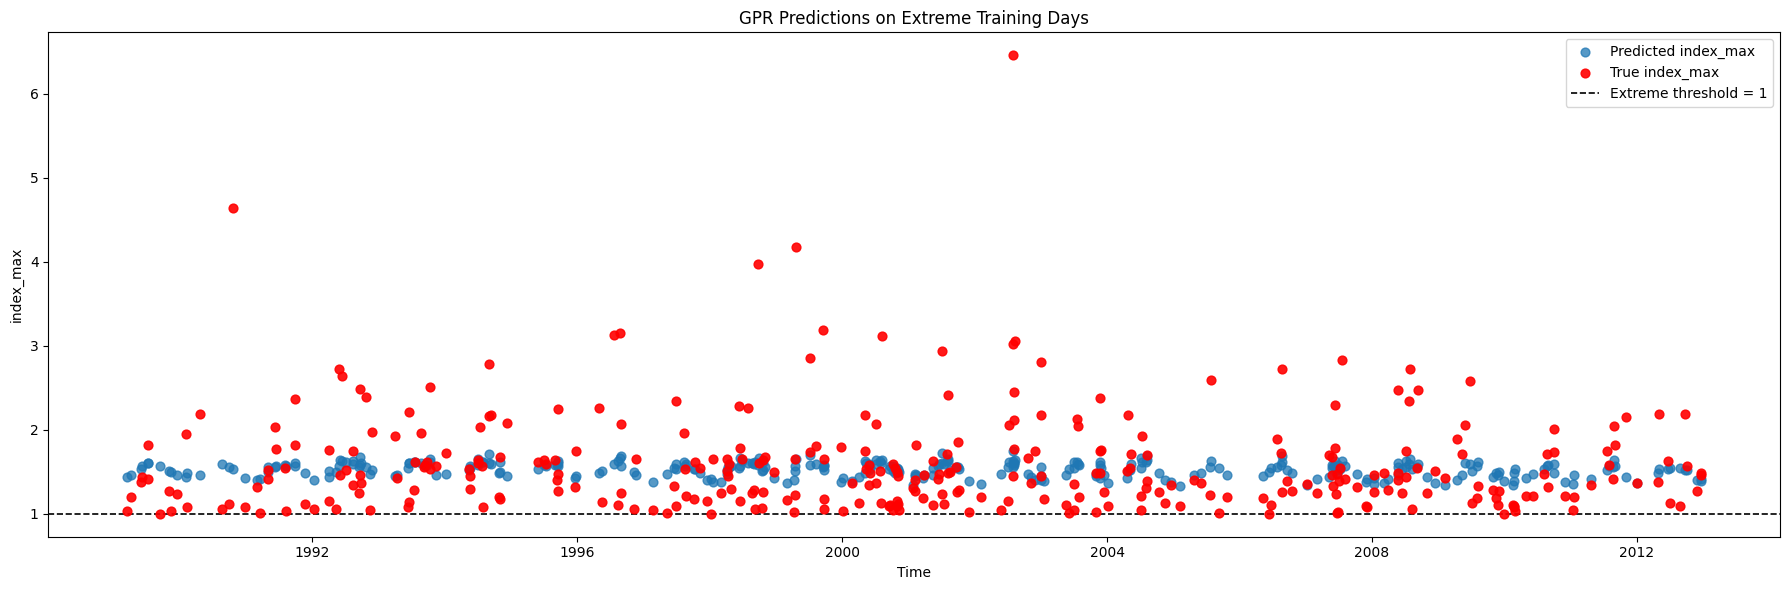


GPR Stage 2 performance on extreme training days
------------------------------------------------
RMSE : 0.5755
MAE  : 0.3697
R²   : 0.0836


In [ ]:
# ============================================================
# 6. Predict on training extreme observations
# ============================================================

# Predictions on log scale
pred_train_gpr_log = gpr_stage2.predict(
    X_train_gpr_scaled
)

# Transform predictions back to original scale
pred_train_gpr = np.expm1(
    pred_train_gpr_log
)

train_gpr_extreme[
    "pred_index_gpr"
] = pred_train_gpr

# ============================================================
# 7. Plot training extreme observations
# ============================================================

plt.figure(figsize=(18, 6))

# Predicted values: default matplotlib colour
plt.scatter(
    train_gpr_extreme.index,
    train_gpr_extreme["pred_index_gpr"],
    s=40,
    alpha=0.75,
    label="Predicted index_max",
    zorder=2
)

# True values: red
plt.scatter(
    train_gpr_extreme.index,
    train_gpr_extreme[target_reg],
    color="red",
    s=40,
    alpha=0.9,
    label="True index_max",
    zorder=3
)

plt.axhline(
    y=1,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Extreme threshold = 1"
)

plt.xlabel("Time")
plt.ylabel("index_max")

plt.title(
    "GPR Predictions on Extreme Training Days"
)

plt.legend(
    loc="upper right"
)

plt.tight_layout()
plt.show()

# ============================================================
# 8. Training metrics on extreme observations only
# ============================================================

rmse_gpr_train = np.sqrt(
    mean_squared_error(
        y_train_gpr,
        pred_train_gpr
    )
)

mae_gpr_train = mean_absolute_error(
    y_train_gpr,
    pred_train_gpr
)

r2_gpr_train = r2_score(
    y_train_gpr,
    pred_train_gpr
)

print("\nGPR Stage 2 performance on extreme training days")
print("------------------------------------------------")
print(f"RMSE : {rmse_gpr_train:.4f}")
print(f"MAE  : {mae_gpr_train:.4f}")
print(f"R²   : {r2_gpr_train:.4f}")


Number of true extreme observations in test set:
85


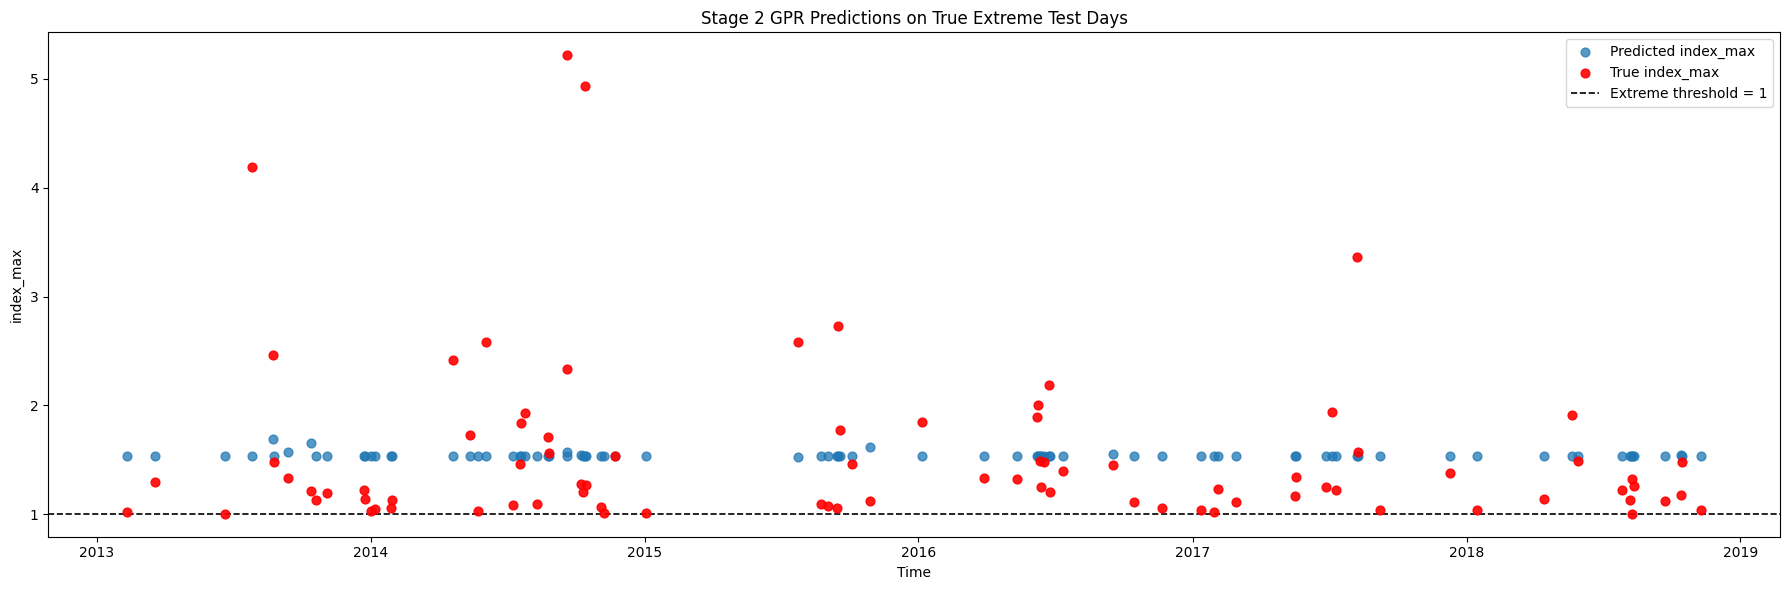


GPR Stage 2 performance on true extreme test days
-------------------------------------------------
RMSE : 0.7749
MAE  : 0.4975
R²   : 0.0055


In [ ]:
# ============================================================
# 9. Prepare test data
#    Evaluate only true extreme observations
# ============================================================

test_gpr = test[
    selected_features_gpr
    + [target_class, target_reg]
].dropna().sort_index().copy()

test_gpr_extreme = test_gpr[
    test_gpr[target_class] == 1
].copy()

print("\nNumber of true extreme observations in test set:")
print(len(test_gpr_extreme))

if len(test_gpr_extreme) == 0:
    raise ValueError(
        "No true extreme observations are available in the test set."
    )

X_test_gpr = test_gpr_extreme[
    selected_features_gpr
]

y_test_gpr = test_gpr_extreme[
    target_reg
].to_numpy()

X_test_gpr_scaled = scaler_gpr.transform(
    X_test_gpr
)

# ============================================================
# 10. Predict test extreme observations
# ============================================================

# Predictions on log scale
pred_test_gpr_log = gpr_stage2.predict(
    X_test_gpr_scaled
)

# Transform predictions back to original scale
pred_test_gpr = np.expm1(
    pred_test_gpr_log
)

test_gpr_extreme[
    "pred_index_gpr"
] = pred_test_gpr

# ============================================================
# 11. Plot test extreme observations
# ============================================================

plt.figure(figsize=(18, 6))

# Predicted values: default matplotlib colour
plt.scatter(
    test_gpr_extreme.index,
    test_gpr_extreme["pred_index_gpr"],
    s=40,
    alpha=0.75,
    label="Predicted index_max",
    zorder=2
)

# True values: red
plt.scatter(
    test_gpr_extreme.index,
    test_gpr_extreme[target_reg],
    color="red",
    s=40,
    alpha=0.9,
    label="True index_max",
    zorder=3
)

plt.axhline(
    y=1,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Extreme threshold = 1"
)

plt.xlabel("Time")
plt.ylabel("index_max")

plt.title(
    "Stage 2 GPR Predictions on True Extreme Test Days"
)

plt.legend(
    loc="upper right"
)

plt.tight_layout()
plt.show()

# ============================================================
# 12. Test metrics on true extreme observations only
# ============================================================

rmse_gpr_test = np.sqrt(
    mean_squared_error(
        y_test_gpr,
        pred_test_gpr
    )
)

mae_gpr_test = mean_absolute_error(
    y_test_gpr,
    pred_test_gpr
)

r2_gpr_test = r2_score(
    y_test_gpr,
    pred_test_gpr
)

print("\nGPR Stage 2 performance on true extreme test days")
print("-------------------------------------------------")
print(f"RMSE : {rmse_gpr_test:.4f}")
print(f"MAE  : {mae_gpr_test:.4f}")
print(f"R²   : {r2_gpr_test:.4f}")

# XGB Classifier

In [ ]:
# ============================================================
# 1. Settings
# ============================================================

selected_features_xgb_cls_all = [
    'year', 'month',
    'lag1', 'lag2', 'lag3', 'lag4', 'lag5', 'lag6', 'lag7',
    'lag8', 'lag9', 'lag10', 'lag11', 'lag12', 'lag13', 'lag14',
    'mean_7d', 'mean_14d', 'mean_30d',
    'max_7d', 'max_14d',
    'extreme_count_7d', 'extreme_count_30d',
    'day_of_year', 'sin_doy', 'cos_doy',
    'sin_month', 'cos_month',
    'days_since_extreme99'
]

target_cls = "extreme"
random_state = 42

candidate_n_features_cls = [5, 10, 15, 20, 25, 29]
n_splits_cls = 4

selected_features_xgb_cls_all = list(
    dict.fromkeys(selected_features_xgb_cls_all)
)

candidate_n_features_cls = [
    k for k in candidate_n_features_cls
    if k <= len(selected_features_xgb_cls_all)
]

# ============================================================
# 2. Prepare training data
# ============================================================

missing_features = [
    feature
    for feature in selected_features_xgb_cls_all + [target_cls]
    if feature not in train.columns
]

if missing_features:
    raise KeyError(
        "Missing columns in train:\n"
        + "\n".join(missing_features)
    )

train_cv_xgb_cls = train[
    selected_features_xgb_cls_all + [target_cls]
].dropna().sort_index().copy()

X_cv_cls = train_cv_xgb_cls[selected_features_xgb_cls_all]
y_cv_cls = train_cv_xgb_cls[target_cls].astype(int)

print("Number of training observations:", len(y_cv_cls))
print("Number of extreme observations:", int(y_cv_cls.sum()))
print("Extreme event rate:", round(y_cv_cls.mean() * 100, 4), "%")

# ============================================================
# 3. Define XGBClassifier
#    Use the same hyperparameters as the final model
# ============================================================

def create_xgb_cls_cv(scale_pos_weight):

    return XGBClassifier(
        objective="binary:logistic",
        eval_metric="aucpr",

        n_estimators=500,
        max_depth=4,
        learning_rate=0.05,

        subsample=0.8,
        colsample_bytree=0.8,

        scale_pos_weight=scale_pos_weight,

        importance_type="gain",

        random_state=random_state,
        n_jobs=-1,
        tree_method="hist",
        verbosity=0
    )

# ============================================================
# 4. Time-series cross-validation
# ============================================================

tscv_cls = TimeSeriesSplit(n_splits=n_splits_cls)

cv_results_cls = []
fold_info_cls = []

for fold, (train_idx, val_idx) in enumerate(
    tscv_cls.split(X_cv_cls), start=1
):

    X_tr_all = X_cv_cls.iloc[train_idx]
    X_val_all = X_cv_cls.iloc[val_idx]

    y_tr = y_cv_cls.iloc[train_idx]
    y_val = y_cv_cls.iloc[val_idx]

    # Calculate class weight using training fold only
    n_positive = int((y_tr == 1).sum())
    n_negative = int((y_tr == 0).sum())

    if n_positive == 0 or n_negative == 0:
        raise ValueError(
            f"Fold {fold}: training fold contains only one class."
        )

    scale_pos_weight = n_negative / n_positive

    fold_info_cls.append({
        "Fold": fold,
        "Train_samples": len(y_tr),
        "Validation_samples": len(y_val),
        "Train_extremes": n_positive,
        "Validation_extremes": int(y_val.sum()),
        "Scale_pos_weight": scale_pos_weight,
        "Train_start": X_tr_all.index[0],
        "Train_end": X_tr_all.index[-1],
        "Validation_start": X_val_all.index[0],
        "Validation_end": X_val_all.index[-1]
    })

    # --------------------------------------------------------
    # Initial model for Gain-based feature ranking
    # --------------------------------------------------------

    ranking_model = create_xgb_cls_cv(scale_pos_weight)

    ranking_model.fit(X_tr_all, y_tr)

    importance = pd.DataFrame({
        "Feature": X_tr_all.columns,
        "Gain": ranking_model.feature_importances_
    }).sort_values(
        ["Gain", "Feature"],
        ascending=[False, True]
    )

    ranked_features = importance["Feature"].tolist()

    # --------------------------------------------------------
    # Evaluate different feature counts
    # --------------------------------------------------------

    for k in candidate_n_features_cls:

        features_k = ranked_features[:k]

        model = create_xgb_cls_cv(scale_pos_weight)

        model.fit(
            X_tr_all[features_k],
            y_tr
        )

        y_prob = model.predict_proba(
            X_val_all[features_k]
        )[:, 1]

        # PR-AUC (Average Precision)
        pr_auc = average_precision_score(y_val, y_prob)

        # ROC-AUC requires both classes in validation
        roc_auc = (
            roc_auc_score(y_val, y_prob)
            if y_val.nunique() == 2
            else np.nan
        )

        brier = brier_score_loss(y_val, y_prob)

        cv_results_cls.append({
            "Fold": fold,
            "N_features": k,
            "ROC_AUC": roc_auc,
            "PR_AUC": pr_auc,
            "Brier": brier
        })

# ============================================================
# 5. Cross-validation summary
# ============================================================

cv_results_cls_df = pd.DataFrame(cv_results_cls)
fold_info_cls_df = pd.DataFrame(fold_info_cls)

cv_summary_cls = (
    cv_results_cls_df
    .groupby("N_features")
    .agg(
        Mean_ROC_AUC=("ROC_AUC", "mean"),
        Std_ROC_AUC=("ROC_AUC", "std"),
        Mean_PR_AUC=("PR_AUC", "mean"),
        Std_PR_AUC=("PR_AUC", "std"),
        Mean_Brier=("Brier", "mean"),
        Std_Brier=("Brier", "std")
    )
    .reset_index()
    .sort_values("N_features")
)

print("\nCross-validation fold information:")
print(fold_info_cls_df.to_string(index=False))

print("\nFeature count cross-validation results:")
print(cv_summary_cls.round(4).to_string(index=False))

# ============================================================
# 6. Determine optimal feature count
#    Maximum mean PR-AUC
# ============================================================

best_row_cls = cv_summary_cls.loc[
    cv_summary_cls["Mean_PR_AUC"].idxmax()
]

best_n_features_cls = int(best_row_cls["N_features"])

print("\n====================================")
print("Optimal number of features:", best_n_features_cls)
print(
    "Best mean CV PR-AUC:",
    round(best_row_cls["Mean_PR_AUC"], 4)
)
print("====================================")



Number of training observations: 8693
Number of extreme observations: 331
Extreme event rate: 3.8077 %

Cross-validation fold information:
 Fold  Train_samples  Validation_samples  Train_extremes  Validation_extremes  Scale_pos_weight Train_start  Train_end Validation_start Validation_end
    1           1741                1738              58                   63         29.017241  1989-03-15 1993-12-19       1993-12-20     1998-09-22
    2           3479                1738             121                   87         27.752066  1989-03-15 1998-09-22       1998-09-23     2003-06-26
    3           5217                1738             208                   64         24.081731  1989-03-15 2003-06-26       2003-06-27     2008-03-29
    4           6955                1738             272                   59         24.569853  1989-03-15 2008-03-29       2008-03-30     2012-12-31

Feature count cross-validation results:
 N_features  Mean_ROC_AUC  Std_ROC_AUC  Mean_PR_AUC  Std_PR_AUC  

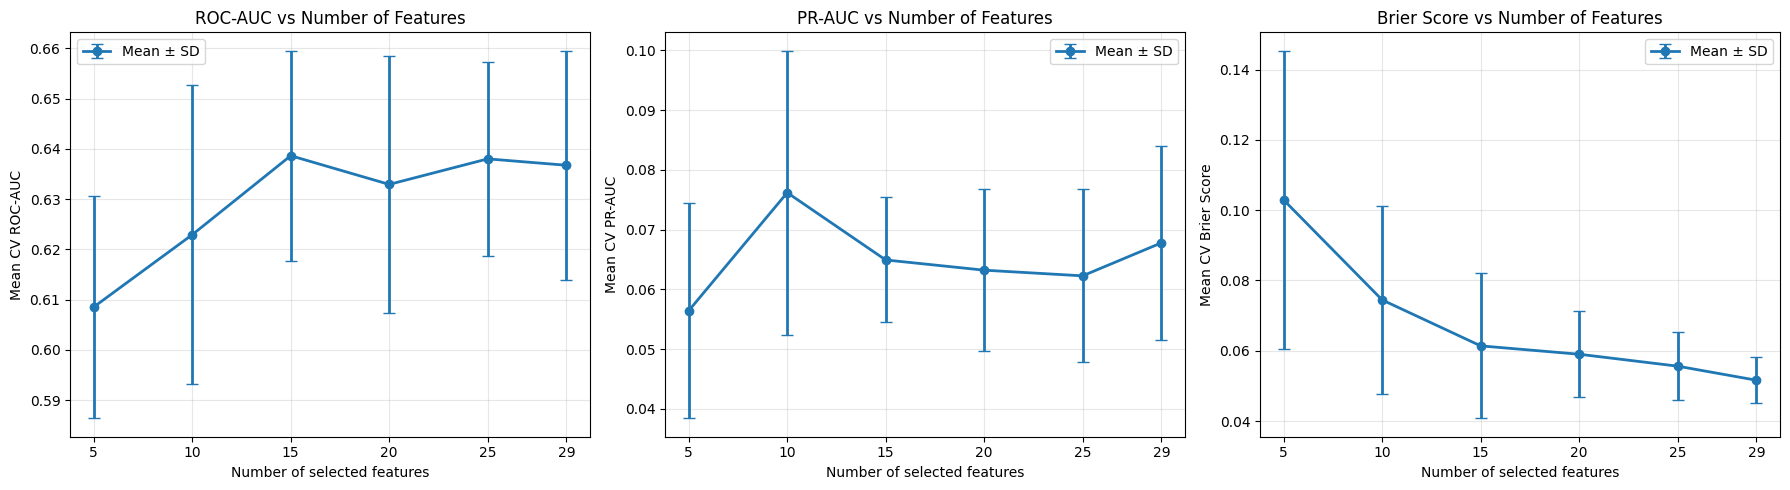

In [ ]:
# ============================================================
# 7. Plot cross-validation metrics
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics_cls = [
    ("Mean_ROC_AUC", "Std_ROC_AUC", "ROC-AUC"),
    ("Mean_PR_AUC", "Std_PR_AUC", "PR-AUC"),
    ("Mean_Brier", "Std_Brier", "Brier Score")
]

for ax, (mean_col, std_col, metric_name) in zip(
    axes, metrics_cls
):

    ax.errorbar(
        cv_summary_cls["N_features"],
        cv_summary_cls[mean_col],
        yerr=cv_summary_cls[std_col],
        marker="o",
        linewidth=2,
        capsize=4,
        label="Mean ± SD"
    )

    ax.set_title(f"{metric_name} vs Number of Features")
    ax.set_xlabel("Number of selected features")
    ax.set_ylabel(f"Mean CV {metric_name}")
    ax.set_xticks(candidate_n_features_cls)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
# -----------------------------
# 1. Define features and target
# -----------------------------

selected_features_xgb = [
    'year', 'month',
    'lag1', 'lag2', 'lag3', 'lag4', 'lag5', 'lag6', 'lag7', 'lag8', 'lag9',
    'lag10', 'lag11', 'lag12', 'lag13', 'lag14',
    'mean_7d', 'mean_14d', 'mean_30d', 'max_7d', 'max_14d',
    'extreme_count_7d', 'extreme_count_30d',
    'day_of_year', 'sin_doy', 'cos_doy', 'sin_month', 'cos_month',
    'days_since_extreme99'
]

target = "extreme"

In [ ]:
# -----------------------------
# 2. Use full training data
# -----------------------------

train_xgb = train[
    selected_features_xgb + [target]
].dropna().copy()

X_train_xgb = train_xgb[selected_features_xgb]
y_train_xgb = train_xgb[target].astype(int)

# -----------------------------
# 3. Compute scale_pos_weight
# -----------------------------

n_positive = np.sum(y_train_xgb == 1)
n_negative = np.sum(y_train_xgb == 0)

scale_pos_weight = n_negative / n_positive

print("Number of positives:", n_positive)
print("Number of negatives:", n_negative)
print("scale_pos_weight:", scale_pos_weight)




Number of positives: 331
Number of negatives: 8362
scale_pos_weight: 25.26283987915408


In [ ]:
#xgb_clf = XGBClassifier(
#    n_estimators=500,
#    max_depth=4,
#    learning_rate=0.05,
    #subsample=0.8,
    #colsample_bytree=0.8,
#    scale_pos_weight=scale_pos_weight,
 #   eval_metric="aucpr",
#    random_state=42
#)

#xgb_clf.fit(X_train_xgb, y_train_xgb)


In [ ]:
# -----------------------------
# 4. Fit XGBClassifier
# -----------------------------

xgb_clf = XGBClassifier(
    n_estimators=200,
    max_depth=2,
    min_child_weight=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    random_state=42
)

xgb_clf.fit(X_train_xgb, y_train_xgb)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='aucpr', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.03, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=2,
              max_leaves=None, min_child_weight=5, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
# -----------------------------
# 5. Feature importances
# -----------------------------

feature_importance_df = pd.DataFrame({
    "feature": selected_features_xgb,
    "importance": xgb_clf.feature_importances_
})

feature_importance_df = feature_importance_df.sort_values(
    by="importance",
    ascending=False
)

print(feature_importance_df)


       feature  importance
0         lag1    0.222502
4      mean_7d    0.117647
2      cos_doy    0.102890
3    sin_month    0.101860
1  day_of_year    0.101122
9         lag2    0.092308
6        lag12    0.069754
5        lag10    0.068169
8        lag13    0.065799
7         year    0.057949


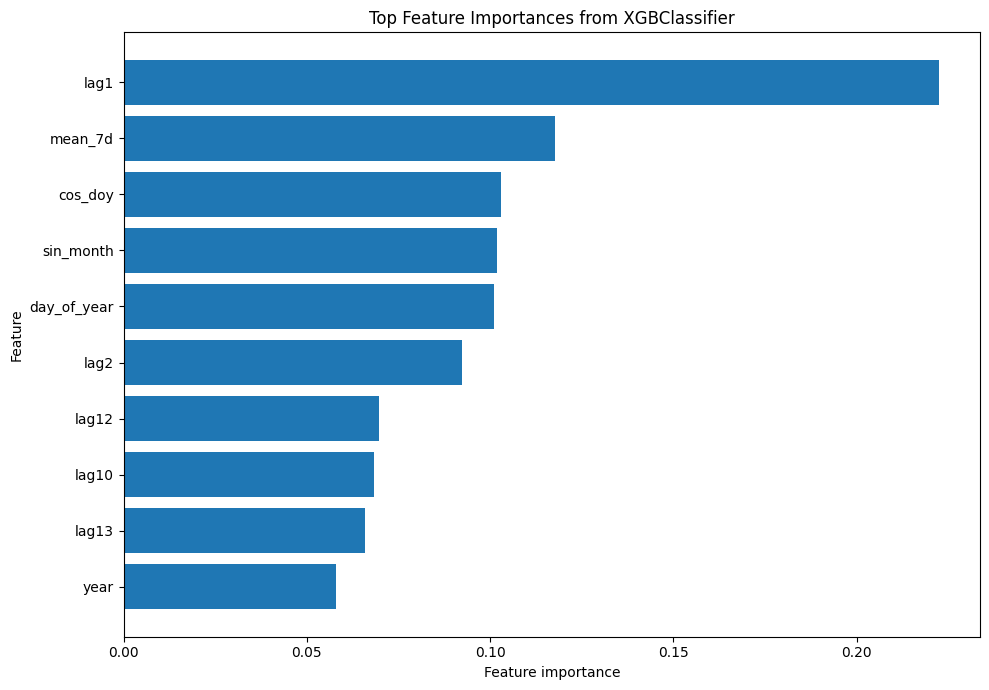

In [ ]:
# -----------------------------
# 6. Plot top feature importances
# -----------------------------

top_importance = feature_importance_df.head(10).sort_values(
    by="importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_importance["feature"],
    top_importance["importance"]
)

plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.title("Top Feature Importances from XGBClassifier")

plt.tight_layout()
plt.show()

In [ ]:
selected_features_xgb = [
    'lag1', 'day_of_year', 'cos_doy', 'sin_month', 'mean_7d', 'lag10',
    'lag12', 'year', 'lag13',
    'lag2'
]
target = "extreme"

In [ ]:
# -----------------------------
# 2. Prepare training data
# -----------------------------

train_xgb = train[
    selected_features_xgb + [target]
].dropna().copy()

X_train_xgb = train_xgb[selected_features_xgb]
y_train_xgb = train_xgb[target].astype(int)

# -----------------------------
# 3. Compute scale_pos_weight
# -----------------------------

n_positive = np.sum(y_train_xgb == 1)
n_negative = np.sum(y_train_xgb == 0)

scale_pos_weight = n_negative / n_positive

print("Number of positives:", n_positive)
print("Number of negatives:", n_negative)
print("scale_pos_weight:", scale_pos_weight)

Number of positives: 332
Number of negatives: 8421
scale_pos_weight: 25.3644578313253


In [ ]:
#xgb_clf = XGBClassifier(
#    n_estimators=500,
#    max_depth=4,
#    learning_rate=0.05,
    #subsample=0.8,
    #colsample_bytree=0.8,
#    scale_pos_weight=scale_pos_weight,
#    eval_metric="aucpr",
#    random_state=42
#)

#xgb_clf.fit(X_train_xgb, y_train_xgb)

In [ ]:
xgb_clf = XGBClassifier(
    n_estimators=200,
    max_depth=2,
    min_child_weight=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    random_state=42
)

xgb_clf.fit(X_train_xgb, y_train_xgb)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='aucpr', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.03, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=2,
              max_leaves=None, min_child_weight=5, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
# -----------------------------
# 5. Predict probabilities on training set
# -----------------------------

y_prob_xgb_train = xgb_clf.predict_proba(X_train_xgb)[:, 1]

# -----------------------------
# 6. Evaluation metrics (Training Set)
# -----------------------------

roc_auc_xgb_train = roc_auc_score(
    y_train_xgb, y_prob_xgb_train
)

pr_auc_xgb_train = average_precision_score(
    y_train_xgb, y_prob_xgb_train
)

brier_xgb_train = brier_score_loss(
    y_train_xgb, y_prob_xgb_train
)

# -----------------------------
# 7. Print results
# -----------------------------

print("XGBoost - Training Set")
print(f"ROC-AUC: {roc_auc_xgb_train:.4f}")
print(f"PR-AUC: {pr_auc_xgb_train:.4f}")
print(f"Brier Score: {brier_xgb_train:.4f}")

XGBoost - Training Set
ROC-AUC: 0.7833
PR-AUC: 0.1319
Brier Score: 0.1974


       feature  importance
0         lag1    0.222502
4      mean_7d    0.117647
2      cos_doy    0.102890
3    sin_month    0.101860
1  day_of_year    0.101122
9         lag2    0.092308
6        lag12    0.069754
5        lag10    0.068169
8        lag13    0.065799
7         year    0.057949


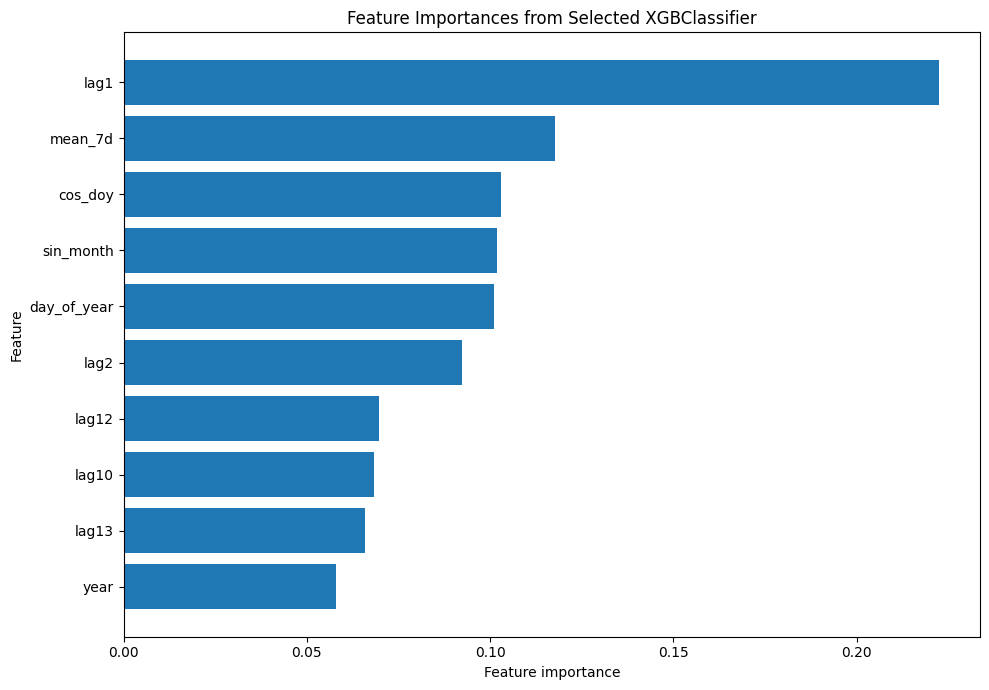

In [ ]:
# -----------------------------
# 5. Feature importances
# -----------------------------

feature_importance_df = pd.DataFrame({
    "feature": selected_features_xgb,
    "importance": xgb_clf.feature_importances_
})

feature_importance_df = feature_importance_df.sort_values(
    by="importance",
    ascending=False
)

print(feature_importance_df)

# -----------------------------
# 6. Plot feature importances
# -----------------------------

feature_importance_plot = feature_importance_df.sort_values(
    by="importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance_plot["feature"],
    feature_importance_plot["importance"]
)

plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.title("Feature Importances from Selected XGBClassifier")

plt.tight_layout()
plt.show()

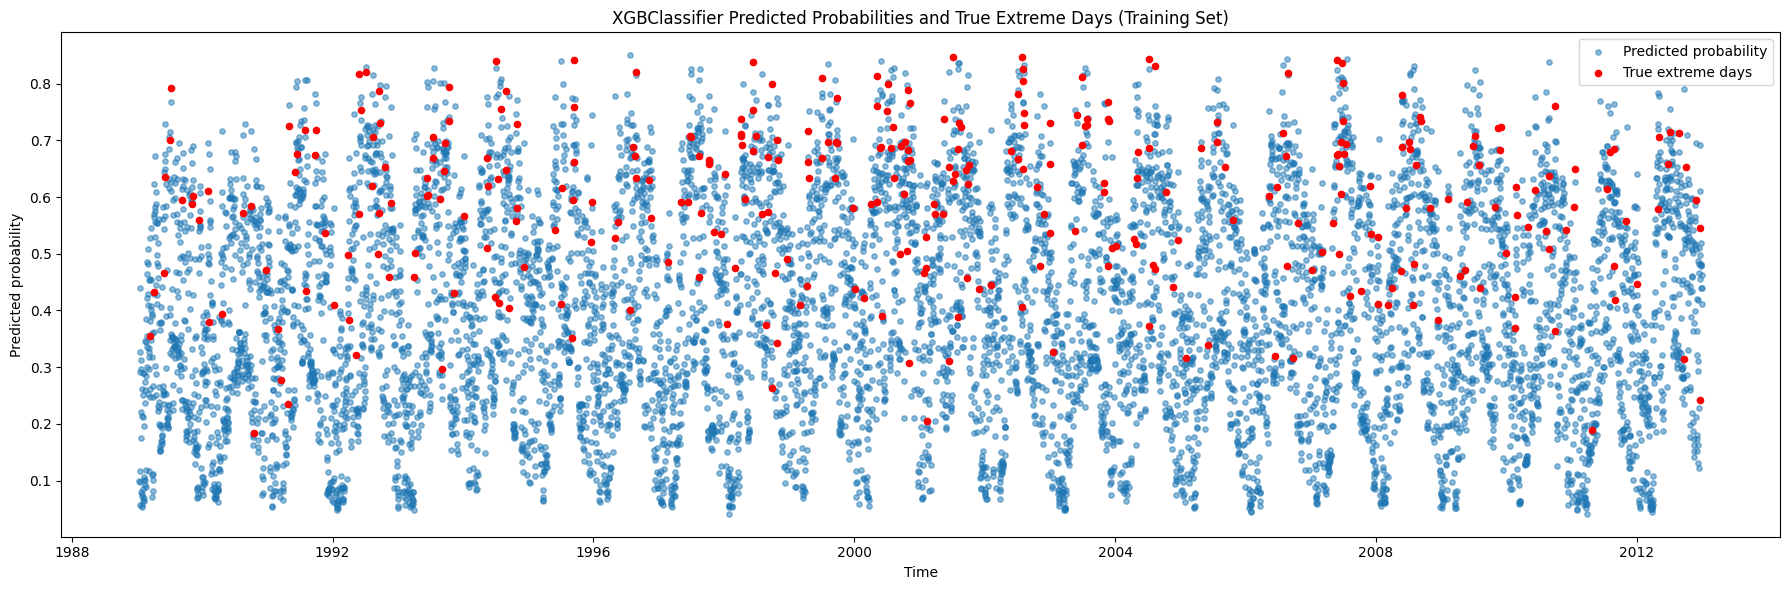

In [ ]:
train_eval_xgb = train_xgb.copy()

train_eval_xgb["p_xgb"] = xgb_clf.predict_proba(
    X_train_xgb
)[:, 1]

plt.figure(figsize=(18, 6))

# Predicted probabilities for all days
plt.scatter(
    train_eval_xgb.index,
    train_eval_xgb["p_xgb"],
    s=15,
    alpha=0.5,
    label="Predicted probability"
)

# True extreme days
extreme_mask = train_eval_xgb["extreme"] == 1

plt.scatter(
    train_eval_xgb.index[extreme_mask],
    train_eval_xgb.loc[extreme_mask, "p_xgb"],
    color="red",
    s=20,
    alpha=1,
    label="True extreme days",
    zorder=3
)

plt.xlabel("Time")
plt.ylabel("Predicted probability")

plt.title(
    "XGBClassifier Predicted Probabilities and True Extreme Days "
    "(Training Set)"
)

# Legend inside the upper-right corner
plt.legend(loc="upper right")

plt.tight_layout()
plt.show()

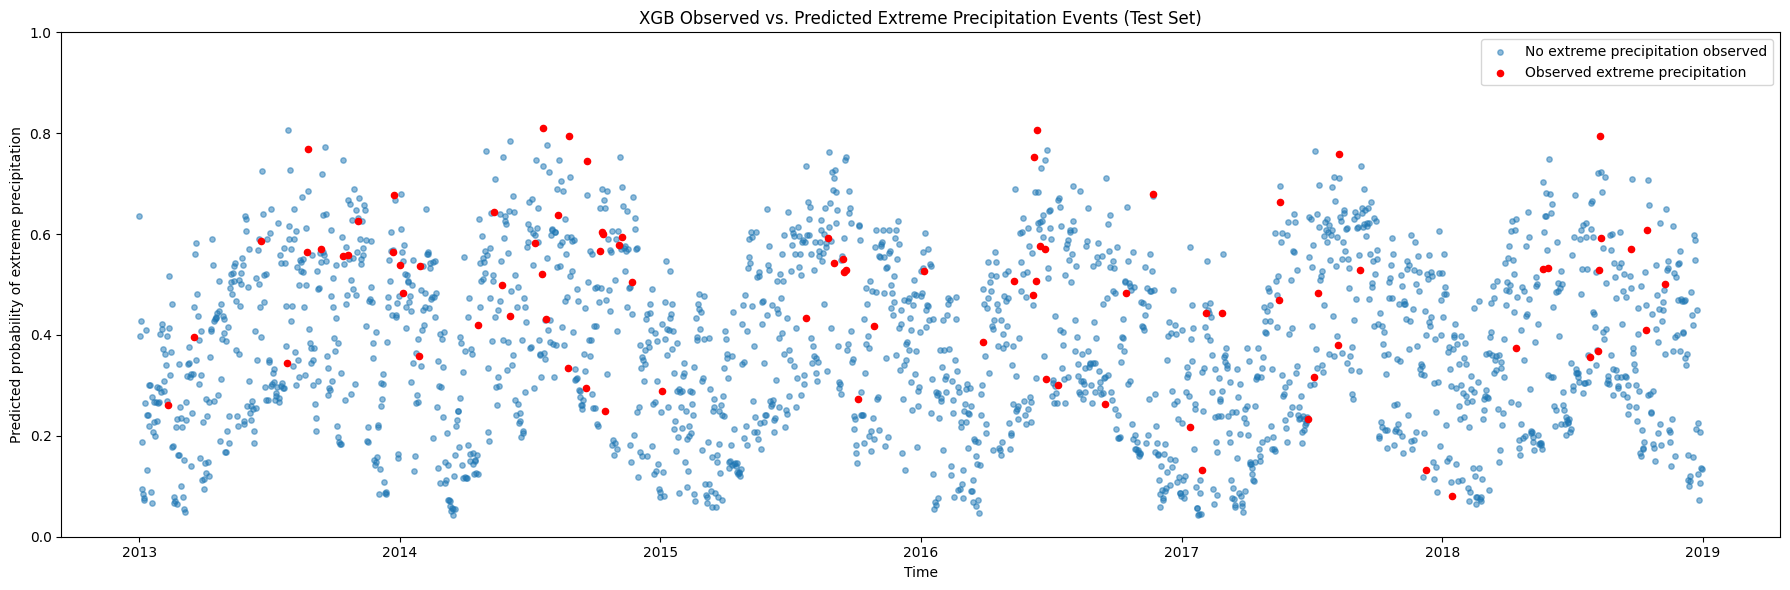

In [ ]:
# -----------------------------
# 1. Prepare test evaluation data
# -----------------------------

test_eval_xgb = test[
    selected_features_xgb + ["extreme"]
].dropna().copy()

X_test_xgb = test_eval_xgb[selected_features_xgb]
y_test_xgb_true = test_eval_xgb["extreme"].astype(int)

# -----------------------------
# 2. Predict probabilities
# -----------------------------

test_eval_xgb["p_xgb"] = xgb_clf.predict_proba(
    X_test_xgb
)[:, 1]

# -----------------------------
# 3. Plot predicted probabilities
#    and true extreme days
# -----------------------------

plt.figure(figsize=(18, 6))

# Non-extreme days
non_extreme_mask = y_test_xgb_true == 0

plt.scatter(
    test_eval_xgb.index[non_extreme_mask],
    test_eval_xgb.loc[non_extreme_mask, "p_xgb"],
    s=15,
    alpha=0.5,
    label="No extreme precipitation observed"
)

# True extreme days
extreme_mask = y_test_xgb_true == 1

plt.scatter(
    test_eval_xgb.index[extreme_mask],
    test_eval_xgb.loc[extreme_mask, "p_xgb"],
    color="red",
    s=20,
    alpha=1,
    label="Observed extreme precipitation",
    zorder=3
)

# -----------------------------
# 4. Figure settings
# -----------------------------

plt.xlabel("Time")
plt.ylabel("Predicted probability of extreme precipitation")

plt.title(
    "XGB Observed vs. Predicted Extreme Precipitation Events "
    "(Test Set)"
)

plt.ylim(0, 1)

# Legend inside the upper-right corner
plt.legend(loc="upper right")

plt.tight_layout()

In [ ]:
# -----------------------------
# 5. Predict probabilities on test set
# -----------------------------

y_prob_xgb_test = xgb_clf.predict_proba(X_test_xgb)[:, 1]

# -----------------------------
# 6. Evaluation metrics (Test Set)
# -----------------------------

roc_auc_xgb_test = roc_auc_score(
    y_test_xgb_true, y_prob_xgb_test
)

pr_auc_xgb_test = average_precision_score(
    y_test_xgb_true, y_prob_xgb_test
)

brier_xgb_test = brier_score_loss(
    y_test_xgb_true, y_prob_xgb_test
)

# -----------------------------
# 7. Print results
# -----------------------------

print("XGBoost - Test Set")
print(f"ROC-AUC: {roc_auc_xgb_test:.4f}")
print(f"PR-AUC: {pr_auc_xgb_test:.4f}")
print(f"Brier Score: {brier_xgb_test:.4f}")

XGBoost - Test Set
ROC-AUC: 0.6833
PR-AUC: 0.1234
Brier Score: 0.1773


# XGB Regressor

In [ ]:
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

Number of extreme training observations: 331

Cross-validation fold information:
 Fold  Train_extremes  Validation_extremes Train_start  Train_end Validation_start Validation_end
    1              67                   66  1989-04-05 1994-07-31       1994-08-31     1999-04-24
    2             133                   66  1989-04-05 1999-04-24       1999-07-05     2002-08-10
    3             199                   66  1989-04-05 2002-08-10       2002-10-22     2007-07-20
    4             265                   66  1989-04-05 2007-07-20       2007-08-07     2012-12-22

Feature count cross-validation results:
 N_features  Mean_RMSE  Std_RMSE  Mean_MAE  Std_MAE  Mean_R2  Std_R2
          5     0.6018    0.2051    0.4135   0.0793  -0.0553  0.1449
         10     0.6017    0.1914    0.4123   0.0787  -0.0653  0.1176
         15     0.6145    0.1815    0.4222   0.0752  -0.1309  0.2174
         20     0.6095    0.1777    0.4214   0.0724  -0.1134  0.2023
         25     0.6050    0.1837    0.4184 

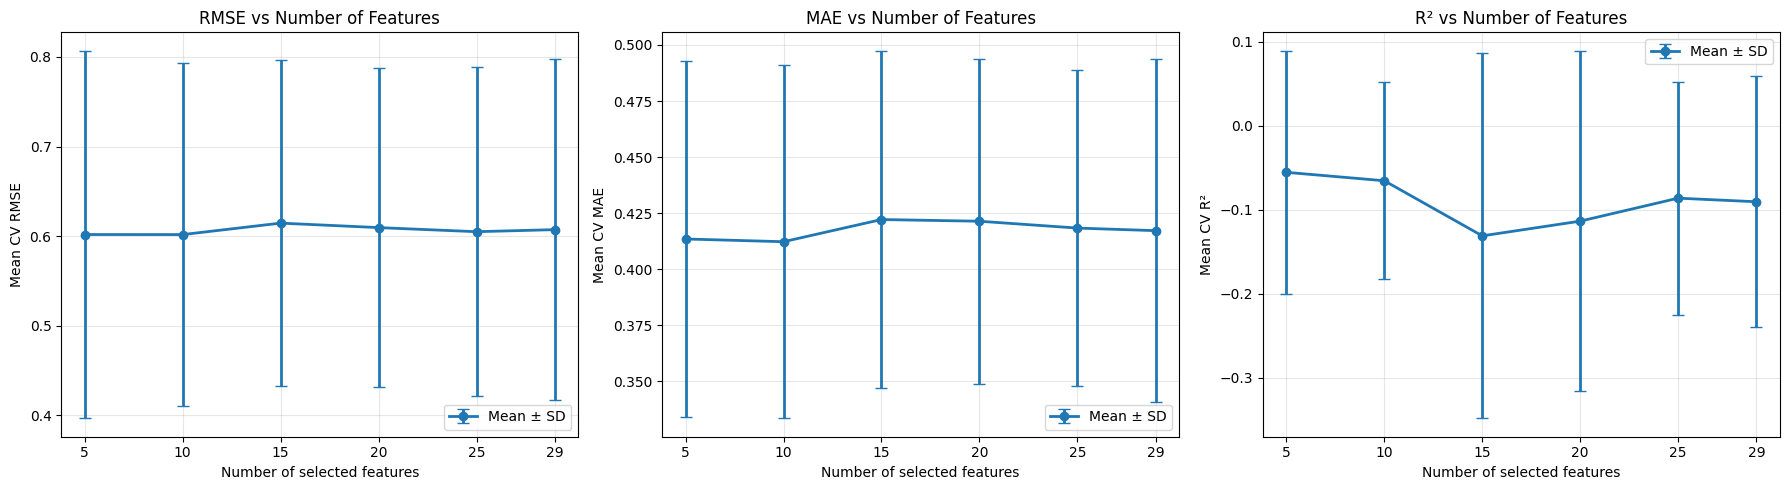

In [ ]:
# ============================================================
# 1. Settings
# ============================================================

selected_features_xgb_reg_all = [
    'year', 'month',
    'lag1', 'lag2', 'lag3', 'lag4', 'lag5', 'lag6', 'lag7',
    'lag8', 'lag9', 'lag10', 'lag11', 'lag12', 'lag13', 'lag14',
    'mean_7d', 'mean_14d', 'mean_30d',
    'max_7d', 'max_14d',
    'extreme_count_7d', 'extreme_count_30d',
    'day_of_year', 'sin_doy', 'cos_doy',
    'sin_month', 'cos_month',
    'days_since_extreme99'
]

target_reg = "index_max"
random_state = 42

candidate_n_features_reg = [5, 10, 15, 20, 25, 29]
n_splits_reg = 4

selected_features_xgb_reg_all = list(
    dict.fromkeys(selected_features_xgb_reg_all)
)

candidate_n_features_reg = [
    k for k in candidate_n_features_reg
    if k <= len(selected_features_xgb_reg_all)
]

# ============================================================
# 2. Prepare training data
#    Only true extreme observations
# ============================================================

missing_features = [
    feature
    for feature in selected_features_xgb_reg_all + [target_reg]
    if feature not in train.columns
]

if missing_features:
    raise KeyError(
        "Missing columns in train:\n"
        + "\n".join(missing_features)
    )

train_cv_xgb_reg = train[
    selected_features_xgb_reg_all + [target_reg]
].dropna().sort_index().copy()

train_cv_xgb_reg = train_cv_xgb_reg[
    train_cv_xgb_reg[target_reg] > 1
].copy()

X_cv_reg = train_cv_xgb_reg[selected_features_xgb_reg_all]
y_cv_reg = train_cv_xgb_reg[target_reg]

print("Number of extreme training observations:", len(y_cv_reg))

if len(y_cv_reg) < n_splits_reg + 2:
    raise ValueError(
        "Insufficient extreme observations for cross-validation."
    )

# ============================================================
# 3. Define XGBRegressor
#    Use the same hyperparameters as the final model
# ============================================================

def create_xgb_reg_cv():

    return XGBRegressor(
        objective="reg:squarederror",

        #n_estimators=500,
        #max_depth=4,
        #learning_rate=0.05,

        n_estimators=150,
        max_depth=2,
        learning_rate=0.03,

        subsample=0.8,
        colsample_bytree=0.8,

        importance_type="gain",

        random_state=random_state,
        n_jobs=-1,
        tree_method="hist",
        verbosity=0
    )

# ============================================================
# 4. Time-series cross-validation
# ============================================================

tscv_reg = TimeSeriesSplit(n_splits=n_splits_reg)

cv_results_reg = []
fold_info_reg = []

for fold, (train_idx, val_idx) in enumerate(
    tscv_reg.split(X_cv_reg), start=1
):

    X_tr_all = X_cv_reg.iloc[train_idx]
    X_val_all = X_cv_reg.iloc[val_idx]

    y_tr = y_cv_reg.iloc[train_idx]
    y_val = y_cv_reg.iloc[val_idx]

    # Log-transform training target only
    y_tr_log = np.log1p(y_tr)

    fold_info_reg.append({
        "Fold": fold,
        "Train_extremes": len(y_tr),
        "Validation_extremes": len(y_val),
        "Train_start": X_tr_all.index[0],
        "Train_end": X_tr_all.index[-1],
        "Validation_start": X_val_all.index[0],
        "Validation_end": X_val_all.index[-1]
    })

    # --------------------------------------------------------
    # Initial model for Gain-based feature ranking
    # --------------------------------------------------------

    ranking_model = create_xgb_reg_cv()

    ranking_model.fit(
        X_tr_all,
        y_tr_log
    )

    importance = pd.DataFrame({
        "Feature": X_tr_all.columns,
        "Gain": ranking_model.feature_importances_
    }).sort_values(
        ["Gain", "Feature"],
        ascending=[False, True]
    )

    ranked_features = importance["Feature"].tolist()

    # --------------------------------------------------------
    # Evaluate different feature counts
    # --------------------------------------------------------

    for k in candidate_n_features_reg:

        features_k = ranked_features[:k]

        model = create_xgb_reg_cv()

        model.fit(
            X_tr_all[features_k],
            y_tr_log
        )

        # Predict on log scale
        pred_log = model.predict(
            X_val_all[features_k]
        )

        # Convert predictions back to original scale
        y_pred = np.expm1(pred_log)

        y_pred = np.maximum(y_pred, 0)

        # Evaluate on original scale
        rmse = np.sqrt(
            mean_squared_error(y_val, y_pred)
        )

        mae = mean_absolute_error(
            y_val, y_pred
        )

        r2 = (
            r2_score(y_val, y_pred)
            if len(y_val) >= 2
            else np.nan
        )

        cv_results_reg.append({
            "Fold": fold,
            "N_features": k,
            "RMSE": rmse,
            "MAE": mae,
            "R2": r2
        })

# ============================================================
# 5. Cross-validation summary
# ============================================================

cv_results_reg_df = pd.DataFrame(cv_results_reg)
fold_info_reg_df = pd.DataFrame(fold_info_reg)

cv_summary_reg = (
    cv_results_reg_df
    .groupby("N_features")
    .agg(
        Mean_RMSE=("RMSE", "mean"),
        Std_RMSE=("RMSE", "std"),
        Mean_MAE=("MAE", "mean"),
        Std_MAE=("MAE", "std"),
        Mean_R2=("R2", "mean"),
        Std_R2=("R2", "std")
    )
    .reset_index()
    .sort_values("N_features")
)

print("\nCross-validation fold information:")
print(fold_info_reg_df.to_string(index=False))

print("\nFeature count cross-validation results:")
print(cv_summary_reg.round(4).to_string(index=False))

# ============================================================
# 6. Determine optimal feature count
#    Minimum mean RMSE
# ============================================================

best_row_reg = cv_summary_reg.loc[
    cv_summary_reg["Mean_RMSE"].idxmin()
]

best_n_features_reg = int(best_row_reg["N_features"])

print("\n====================================")
print("Optimal number of features:", best_n_features_reg)
print(
    "Best mean CV RMSE:",
    round(best_row_reg["Mean_RMSE"], 4)
)
print("====================================")

# ============================================================
# 7. Plot cross-validation metrics
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics_reg = [
    ("Mean_RMSE", "Std_RMSE", "RMSE"),
    ("Mean_MAE", "Std_MAE", "MAE"),
    ("Mean_R2", "Std_R2", "R²")
]

for ax, (mean_col, std_col, metric_name) in zip(
    axes, metrics_reg
):

    ax.errorbar(
        cv_summary_reg["N_features"],
        cv_summary_reg[mean_col],
        yerr=cv_summary_reg[std_col],
        marker="o",
        linewidth=2,
        capsize=4,
        label="Mean ± SD"
    )

    ax.set_title(f"{metric_name} vs Number of Features")
    ax.set_xlabel("Number of selected features")
    ax.set_ylabel(f"Mean CV {metric_name}")
    ax.set_xticks(candidate_n_features_reg)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
# -----------------------------
# 1. Full feature set
# -----------------------------

selected_features_xgb_reg_full = [
    'year', 'month',
    'lag1', 'lag2', 'lag3', 'lag4', 'lag5', 'lag6', 'lag7',
    'lag8', 'lag9', 'lag10', 'lag11', 'lag12', 'lag13', 'lag14',
    'mean_7d', 'mean_14d', 'mean_30d',
    'max_7d', 'max_14d',
    'extreme_count_7d', 'extreme_count_30d',
    'day_of_year', 'sin_doy', 'cos_doy',
    'sin_month', 'cos_month',
    'days_since_extreme99'
]

target_reg = "index_max"

In [ ]:
# -----------------------------
# 2. Prepare extreme training data
# -----------------------------

train_xgb_reg_extreme = train.loc[
    train["index_max"] > 1,
    selected_features_xgb_reg_full + [target_reg]
].dropna().copy()

X_train_xgb_reg_full = train_xgb_reg_extreme[
    selected_features_xgb_reg_full
]

# Log-transform target variable
y_train_xgb_reg_full = np.log1p(
    train_xgb_reg_extreme[target_reg]
)

print("Number of extreme training samples:",
      len(train_xgb_reg_extreme))

Number of extreme training samples: 331


In [ ]:
# -----------------------------
# 3. Fit XGBRegressor (Full Features)
# -----------------------------

xgb_reg_full = XGBRegressor(
    n_estimators=150,
    max_depth=2,
    learning_rate=0.03,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=10,
    gamma=0.1,
    objective="reg:squarederror",
    random_state=42
)

xgb_reg_full.fit(
    X_train_xgb_reg_full,
    y_train_xgb_reg_full
)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=0.1, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.03, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=2,
             max_leaves=None, min_child_weight=5, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=150,
             n_jobs=None, num_parallel_tree=None, ...)

                 feature  importance
25               cos_doy    0.054695
28  days_since_extreme99    0.053642
19                max_7d    0.049487
3                   lag2    0.049272
6                   lag5    0.048011
23           day_of_year    0.045251
24               sin_doy    0.044386
27             cos_month    0.040639
22     extreme_count_30d    0.037009
2                   lag1    0.036734
8                   lag7    0.036683
7                   lag6    0.036563
20               max_14d    0.036504
18              mean_30d    0.035732
5                   lag4    0.035360
12                 lag11    0.035070
14                 lag13    0.034631
10                  lag9    0.034406
4                   lag3    0.033680
9                   lag8    0.033618
13                 lag12    0.033570
11                 lag10    0.031963
17              mean_14d    0.031444
0                   year    0.031138
16               mean_7d    0.031124
15                 lag14    0.029386
1

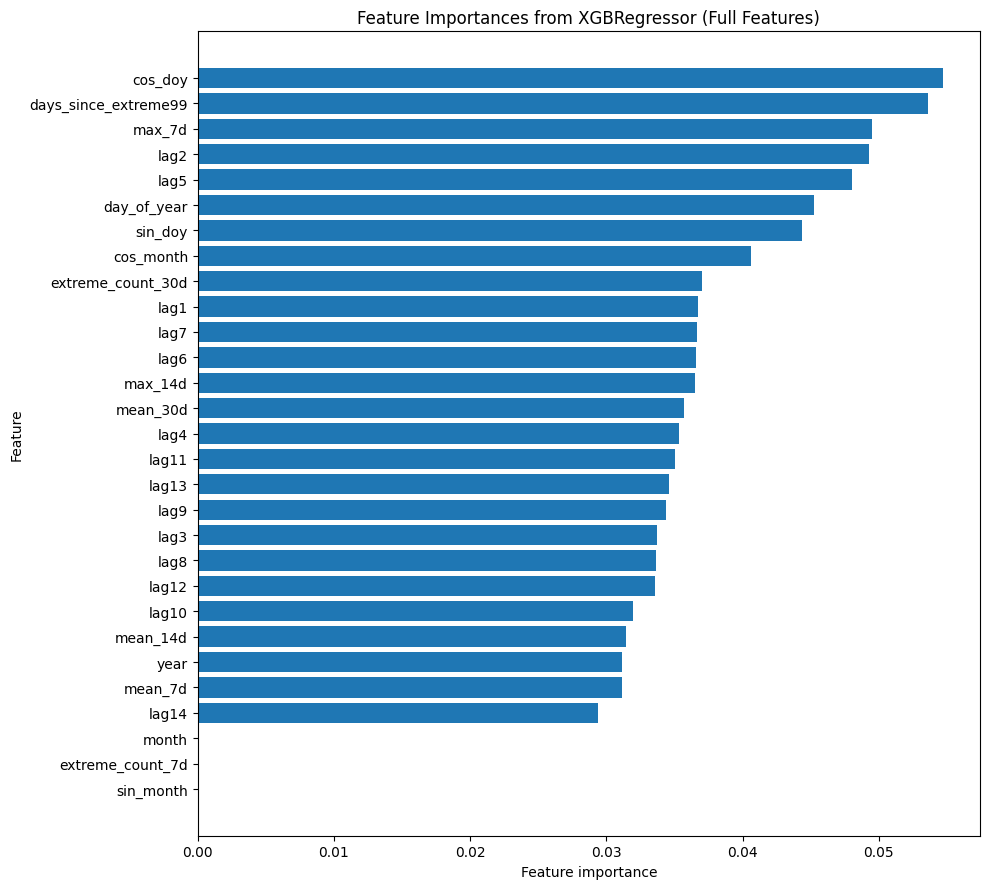

In [ ]:
# -----------------------------
# 4. Feature importances
# -----------------------------

feature_importance_xgb_reg = pd.DataFrame({
    "feature": selected_features_xgb_reg_full,
    "importance": xgb_reg_full.feature_importances_
})

feature_importance_xgb_reg = (
    feature_importance_xgb_reg
    .sort_values(by="importance", ascending=False)
)

print(feature_importance_xgb_reg)

# -----------------------------
# 5. Plot feature importances
# -----------------------------

importance_plot = feature_importance_xgb_reg.sort_values(
    by="importance",
    ascending=True
)

plt.figure(figsize=(10, 9))

plt.barh(
    importance_plot["feature"],
    importance_plot["importance"]
)

plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.title("Feature Importances from XGBRegressor (Full Features)")

plt.tight_layout()
plt.show()

In [ ]:
top_features_xgb_reg = (
    feature_importance_xgb_reg
    .head(10)["feature"]
    .tolist()
)

print("Top important features:")
print(top_features_xgb_reg)

Top important features:
['cos_doy', 'days_since_extreme99', 'max_7d', 'lag2', 'lag5', 'day_of_year', 'sin_doy', 'cos_month', 'extreme_count_30d', 'lag1']


In [ ]:
selected_features_xgb_reg = [
    'cos_doy', 'days_since_extreme99', 'max_7d', 'lag2',
    'lag5', 'day_of_year', 'sin_doy', 'cos_month', 'extreme_count_30d', 'lag1'

]
target_reg = "index_max"

In [ ]:
# -----------------------------
# 7. Prepare selected training data
# -----------------------------

train_xgb_reg_selected = train_xgb_reg_extreme[
    selected_features_xgb_reg + [target_reg]
].copy()

X_train_xgb_reg = train_xgb_reg_selected[
    selected_features_xgb_reg
]

# Log-transform target variable
y_train_xgb_reg = np.log1p(
    train_xgb_reg_selected[target_reg]
)

In [ ]:
# -----------------------------
# 8. Fit XGBRegressor (Selected Features)
# -----------------------------

xgb_reg = XGBRegressor(
    n_estimators=150,
    max_depth=2,
    learning_rate=0.03,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=10,
    gamma=0.1,
    objective="reg:squarederror",
    random_state=42
)

xgb_reg.fit(
    X_train_xgb_reg,
    y_train_xgb_reg
)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=0.1, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.03, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=2,
             max_leaves=None, min_child_weight=5, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=150,
             n_jobs=None, num_parallel_tree=None, ...)

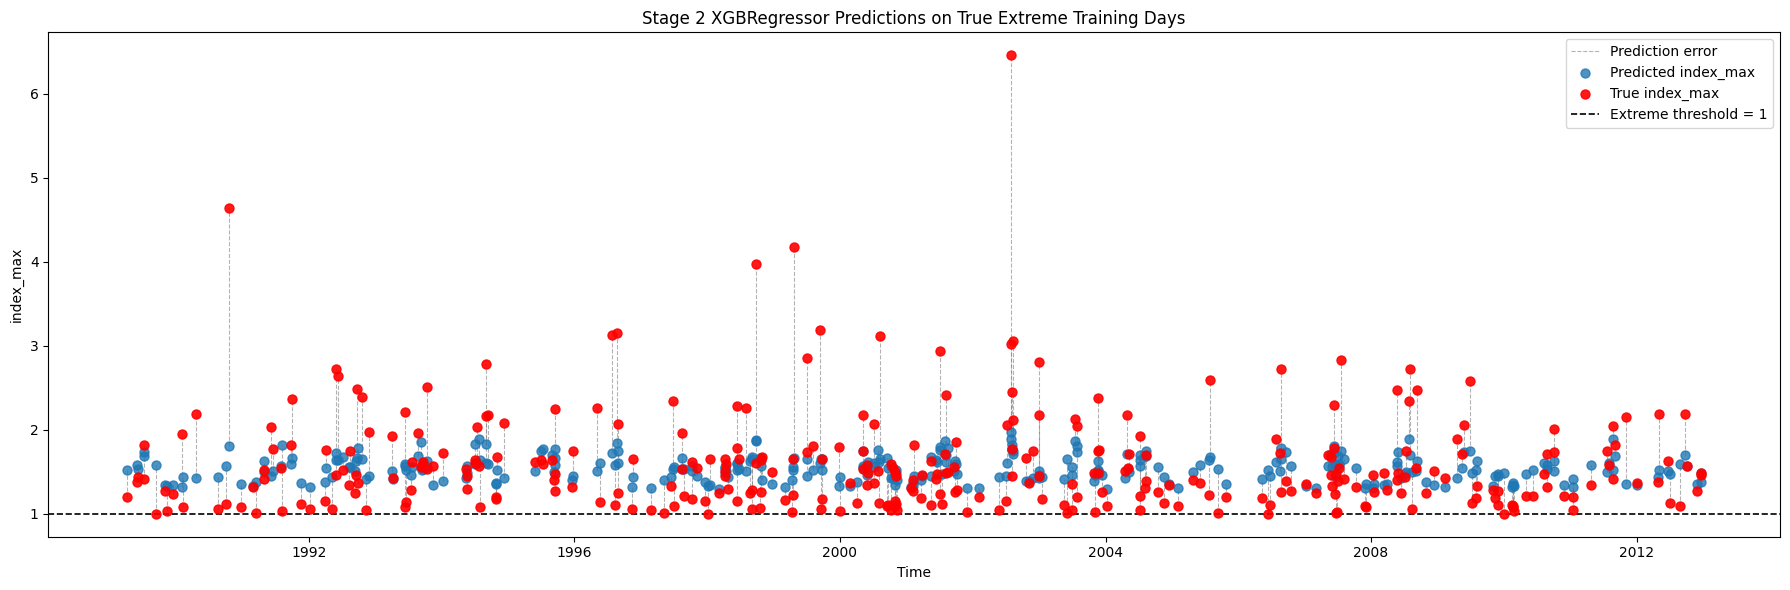

In [ ]:
# -----------------------------
# 9. Predict on extreme training samples
# -----------------------------

# Predict in log scale
y_pred_log_xgb_reg_train = xgb_reg.predict(
    X_train_xgb_reg
)

# Inverse log transformation
y_pred_xgb_reg_train = np.expm1(
    y_pred_log_xgb_reg_train
)

# True values in original scale
y_true_xgb_reg_train = train_xgb_reg_selected[
    target_reg
].to_numpy()

# -----------------------------
# 10. Plot predictions vs true values
# -----------------------------

plt.figure(figsize=(18, 6))

# Grey vertical lines showing prediction errors
plt.vlines(
    x=train_xgb_reg_selected.index,
    ymin=np.minimum(
        y_true_xgb_reg_train,
        y_pred_xgb_reg_train
    ),
    ymax=np.maximum(
        y_true_xgb_reg_train,
        y_pred_xgb_reg_train
    ),
    colors="grey",
    linestyles="--",
    linewidth=0.8,
    alpha=0.6,
    label="Prediction error",
    zorder=1
)

# Predicted values
plt.scatter(
    train_xgb_reg_selected.index,
    y_pred_xgb_reg_train,
    s=42,
    alpha=0.8,
    label="Predicted index_max",
    zorder=2
)

# True values
plt.scatter(
    train_xgb_reg_selected.index,
    y_true_xgb_reg_train,
    color="red",
    s=42,
    alpha=0.9,
    label="True index_max",
    zorder=3
)

# Extreme threshold
plt.axhline(
    y=1,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Extreme threshold = 1"
)

plt.xlabel("Time")
plt.ylabel("index_max")

plt.title(
    "Stage 2 XGBRegressor Predictions "
    "on True Extreme Training Days"
)

plt.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [ ]:
# -----------------------------
# 11. Evaluation metrics (Training Set)
# -----------------------------

rmse_xgb_reg_train = np.sqrt(
    mean_squared_error(
        y_true_xgb_reg_train,
        y_pred_xgb_reg_train
    )
)

mae_xgb_reg_train = mean_absolute_error(
    y_true_xgb_reg_train,
    y_pred_xgb_reg_train
)

r2_xgb_reg_train = r2_score(
    y_true_xgb_reg_train,
    y_pred_xgb_reg_train
)

print(
    "\nXGBRegressor Stage 2 performance "
    "on true extreme training days"
)
print("-----------------------------------------------------------")
print(f"RMSE : {rmse_xgb_reg_train:.4f}")
print(f"MAE  : {mae_xgb_reg_train:.4f}")
print(f"R²   : {r2_xgb_reg_train:.4f}")


XGBRegressor Stage 2 performance on true extreme training days
-----------------------------------------------------------
RMSE : 0.5493
MAE  : 0.3606
R²   : 0.1654


In [ ]:
# -----------------------------
# 12. Prepare extreme test data
# -----------------------------

test_xgb_reg_extreme = test.loc[
    test["index_max"] > 1,
    selected_features_xgb_reg + [target_reg]
].dropna().copy()

X_test_xgb_reg = test_xgb_reg_extreme[
    selected_features_xgb_reg
]

y_test_xgb_reg = test_xgb_reg_extreme[target_reg]

print("Number of extreme test samples:",
      len(test_xgb_reg_extreme))

# -----------------------------
# 13. Predict on extreme test samples
# -----------------------------

# Predict in log scale
y_pred_log_xgb_reg_test = xgb_reg.predict(
    X_test_xgb_reg
)

# Inverse log transformation
y_pred_xgb_reg_test = np.expm1(
    y_pred_log_xgb_reg_test
)

# True values in original scale
y_true_xgb_reg_test = y_test_xgb_reg.to_numpy()

Number of extreme test samples: 85


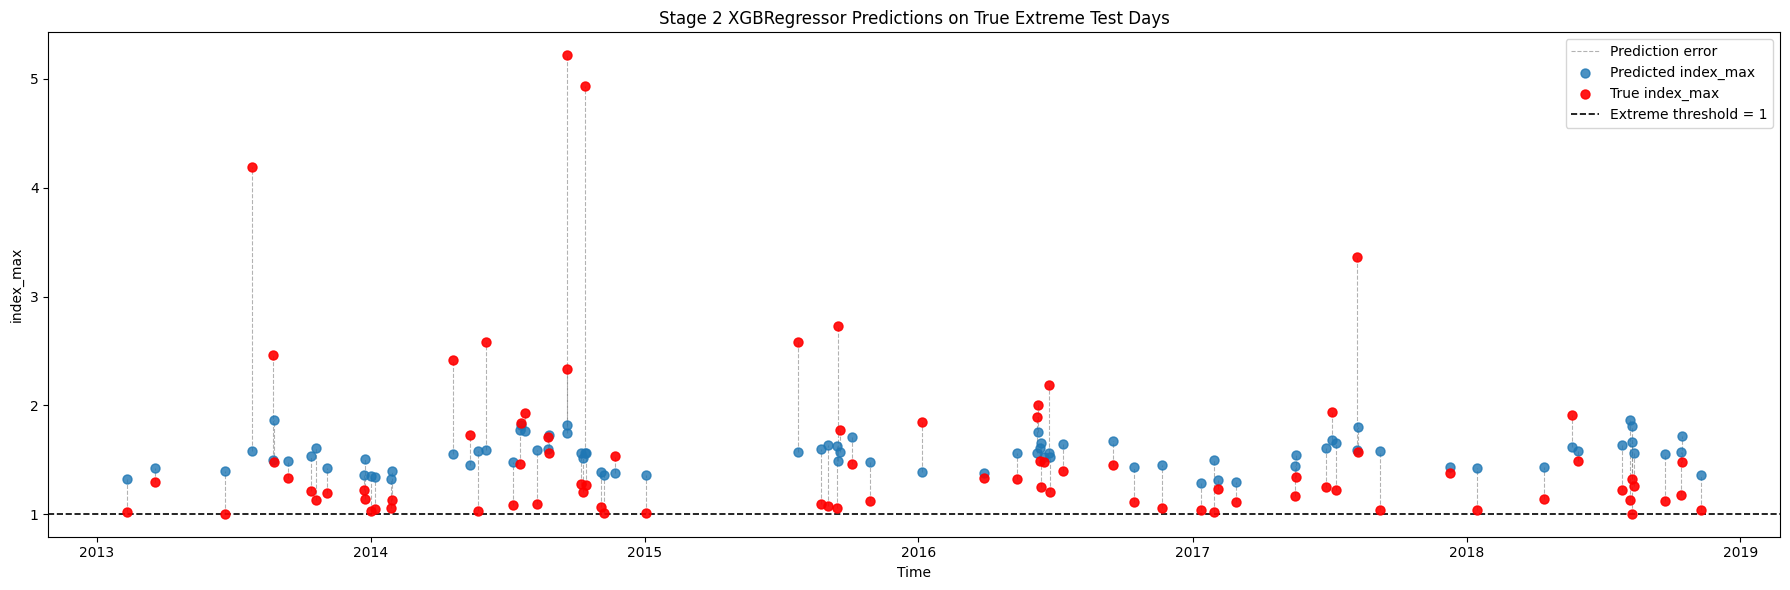

In [ ]:
# -----------------------------
# 14. Plot predictions vs true values
# -----------------------------

plt.figure(figsize=(18, 6))

# Grey vertical lines showing prediction errors
plt.vlines(
    x=test_xgb_reg_extreme.index,
    ymin=np.minimum(
        y_true_xgb_reg_test,
        y_pred_xgb_reg_test
    ),
    ymax=np.maximum(
        y_true_xgb_reg_test,
        y_pred_xgb_reg_test
    ),
    colors="grey",
    linestyles="--",
    linewidth=0.8,
    alpha=0.6,
    label="Prediction error",
    zorder=1
)

# Predicted values
plt.scatter(
    test_xgb_reg_extreme.index,
    y_pred_xgb_reg_test,
    s=42,
    alpha=0.8,
    label="Predicted index_max",
    zorder=2
)

# True values
plt.scatter(
    test_xgb_reg_extreme.index,
    y_true_xgb_reg_test,
    color="red",
    s=42,
    alpha=0.9,
    label="True index_max",
    zorder=3
)

# Extreme threshold
plt.axhline(
    y=1,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Extreme threshold = 1"
)

plt.xlabel("Time")
plt.ylabel("index_max")

plt.title(
    "Stage 2 XGBRegressor Predictions "
    "on True Extreme Test Days"
)

plt.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [ ]:
# -----------------------------
# 15. Evaluation metrics (Test Set)
# -----------------------------

rmse_xgb_reg_test = np.sqrt(
    mean_squared_error(
        y_true_xgb_reg_test,
        y_pred_xgb_reg_test
    )
)

mae_xgb_reg_test = mean_absolute_error(
    y_true_xgb_reg_test,
    y_pred_xgb_reg_test
)

r2_xgb_reg_test = r2_score(
    y_true_xgb_reg_test,
    y_pred_xgb_reg_test
)

print(
    "\nXGBRegressor Stage 2 performance "
    "on true extreme test days"
)
print("-----------------------------------------------------------")
print(f"RMSE : {rmse_xgb_reg_test:.4f}")
print(f"MAE  : {mae_xgb_reg_test:.4f}")
print(f"R²   : {r2_xgb_reg_test:.4f}")


XGBRegressor Stage 2 performance on true extreme test days
-----------------------------------------------------------
RMSE : 0.7468
MAE  : 0.4740
R²   : 0.0762


In [ ]:
# -----------------------------
# 16. Summary of evaluation metrics
# -----------------------------

results_xgb_reg = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "RMSE": [
        rmse_xgb_reg_train,
        rmse_xgb_reg_test
    ],
    "MAE": [
        mae_xgb_reg_train,
        mae_xgb_reg_test
    ],
    "R²": [
        r2_xgb_reg_train,
        r2_xgb_reg_test
    ]
})

print(results_xgb_reg.round(4))

    Dataset    RMSE     MAE      R²
0  Training  0.5493  0.3606  0.1654
1      Test  0.7468  0.4740  0.0762


# LightGBM Classifier

In [ ]:
# ============================================================
# 1. Settings
# ============================================================

selected_features_lgbm_all = [
    'year', 'month',
    'lag1', 'lag2', 'lag3', 'lag4', 'lag5', 'lag6', 'lag7',
    'lag8', 'lag9', 'lag10', 'lag11', 'lag12', 'lag13', 'lag14',
    'mean_7d', 'mean_14d', 'mean_30d',
    'max_7d', 'max_14d',
    'extreme_count_7d', 'extreme_count_30d',
    'day_of_year', 'sin_doy', 'cos_doy',
    'sin_month', 'cos_month',
    'days_since_extreme99'
]

target = "extreme"
random_state = 42

candidate_n_features = [5, 10, 15, 20, 25, 29]
n_splits = 4

# ============================================================
# 2. Prepare training data
# ============================================================

train_cv_lgbm = train[
    selected_features_lgbm_all + [target]
].dropna().sort_index().copy()

X_cv = train_cv_lgbm[selected_features_lgbm_all]
y_cv = train_cv_lgbm[target].astype(int)

# ============================================================
# 3. Define LightGBM model
# ============================================================

def create_lgbm_cv(y):

    n_positive = (y == 1).sum()
    n_negative = (y == 0).sum()

    if n_positive == 0 or n_negative == 0:
        raise ValueError("Both classes are required.")

    return LGBMClassifier(
        objective="binary",
        n_estimators=200,
        learning_rate=0.03,
        num_leaves=7,
        max_depth=3,
        min_child_samples=30,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_alpha=0.5,
        reg_lambda=5.0,
        scale_pos_weight=n_negative / n_positive,
        importance_type="gain",
        random_state=random_state,
        n_jobs=-1,
        verbosity=-1
    )

# ============================================================
# 4. Time-series cross-validation
# ============================================================

tscv = TimeSeriesSplit(n_splits=n_splits)

cv_results = []
fold_info = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_cv), start=1
):

    X_tr_all = X_cv.iloc[train_idx]
    y_tr = y_cv.iloc[train_idx]

    X_val_all = X_cv.iloc[val_idx]
    y_val = y_cv.iloc[val_idx]

    if y_tr.nunique() < 2 or y_val.nunique() < 2:
        raise ValueError(
            f"Fold {fold} does not contain both classes."
        )

    fold_info.append({
        "Fold": fold,
        "Train_size": len(y_tr),
        "Validation_size": len(y_val),
        "Train_extremes": int(y_tr.sum()),
        "Validation_extremes": int(y_val.sum()),
        "Validation_prevalence": y_val.mean()
    })

    # Feature ranking within the training fold
    ranking_model = create_lgbm_cv(y_tr)
    ranking_model.fit(X_tr_all, y_tr)

    importance = pd.DataFrame({
        "Feature": X_tr_all.columns,
        "Gain": ranking_model.feature_importances_
    }).sort_values(
        ["Gain", "Feature"],
        ascending=[False, True]
    )

    ranked_features = importance["Feature"].tolist()

    # Evaluate different numbers of features
    for k in candidate_n_features:

        features_k = ranked_features[:k]

        model = create_lgbm_cv(y_tr)

        model.fit(
            X_tr_all[features_k],
            y_tr
        )

        p_val = model.predict_proba(
            X_val_all[features_k]
        )[:, 1]

        cv_results.append({
            "Fold": fold,
            "N_features": k,
            "PR-AUC": average_precision_score(
                y_val, p_val
            ),
            "ROC-AUC": roc_auc_score(
                y_val, p_val
            ),
            "Brier": brier_score_loss(
                y_val, p_val
            )
        })

# ============================================================
# 5. Cross-validation summary
# ============================================================

cv_results_df = pd.DataFrame(cv_results)
fold_info_df = pd.DataFrame(fold_info)

cv_summary = (
    cv_results_df
    .groupby("N_features")
    .agg(
        Mean_PR_AUC=("PR-AUC", "mean"),
        Std_PR_AUC=("PR-AUC", "std"),
        Mean_ROC_AUC=("ROC-AUC", "mean"),
        Std_ROC_AUC=("ROC-AUC", "std"),
        Mean_Brier=("Brier", "mean"),
        Std_Brier=("Brier", "std")
    )
    .reset_index()
    .sort_values("N_features")
)

print("\nCross-validation fold information:")
print(fold_info_df.round(4).to_string(index=False))

print("\nFeature count cross-validation results:")
print(cv_summary.round(4).to_string(index=False))


Cross-validation fold information:
 Fold  Train_size  Validation_size  Train_extremes  Validation_extremes  Validation_prevalence
    1        1741             1738              58                   63                 0.0362
    2        3479             1738             121                   87                 0.0501
    3        5217             1738             208                   64                 0.0368
    4        6955             1738             272                   59                 0.0339

Feature count cross-validation results:
 N_features  Mean_PR_AUC  Std_PR_AUC  Mean_ROC_AUC  Std_ROC_AUC  Mean_Brier  Std_Brier
          5       0.0748      0.0191        0.6785       0.0192      0.1622     0.0389
         10       0.0752      0.0153        0.6738       0.0211      0.1484     0.0373
         15       0.0751      0.0166        0.6791       0.0191      0.1465     0.0365
         20       0.0742      0.0114        0.6795       0.0208      0.1446     0.0375
         25  

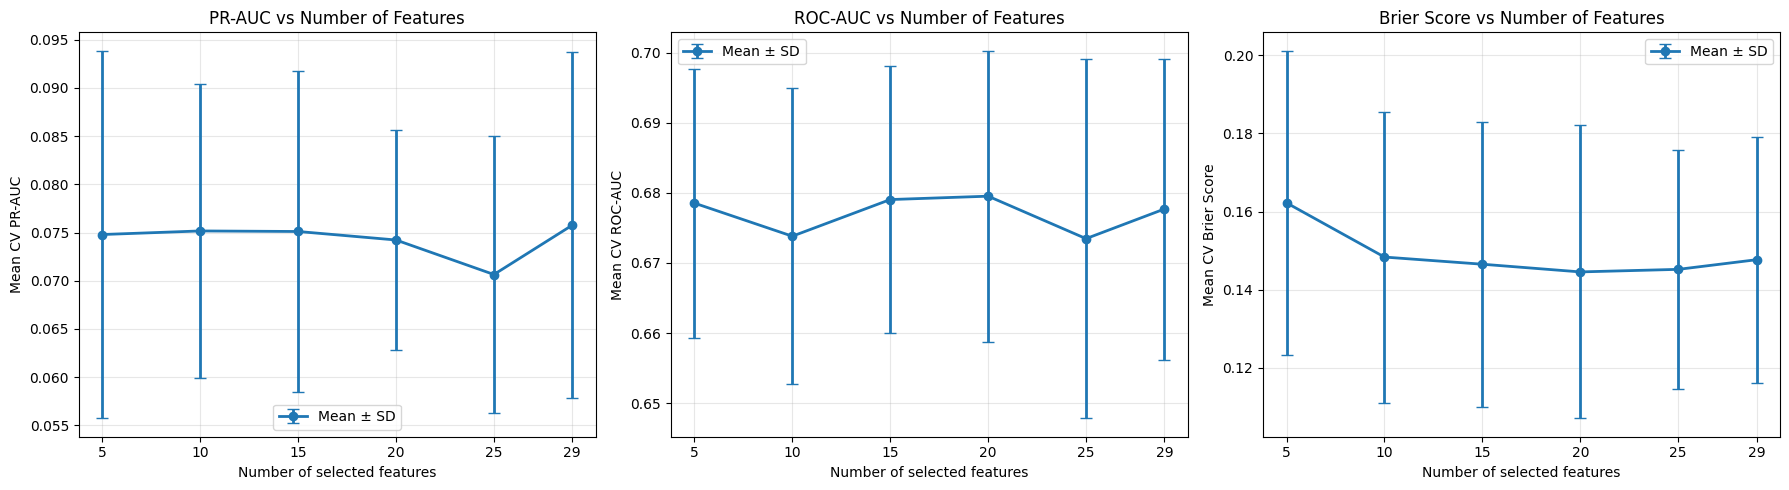

In [ ]:
# ============================================================
# 7. Plot cross-validation metrics
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = [
    ("Mean_PR_AUC", "Std_PR_AUC", "PR-AUC"),
    ("Mean_ROC_AUC", "Std_ROC_AUC", "ROC-AUC"),
    ("Mean_Brier", "Std_Brier", "Brier Score")
]

for ax, (mean_col, std_col, metric_name) in zip(axes, metrics):

    ax.errorbar(
        cv_summary["N_features"],
        cv_summary[mean_col],
        yerr=cv_summary[std_col],
        marker="o",
        linewidth=2,
        capsize=4,
        label="Mean ± SD"
    )

    ax.set_title(f"{metric_name} vs Number of Features")
    ax.set_xlabel("Number of selected features")
    ax.set_ylabel(f"Mean CV {metric_name}")
    ax.set_xticks(candidate_n_features)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
#95th
# ============================================================
# 1. Define all candidate features
# ============================================================

selected_features_lgbm_all = [
    'year', 'month',
    'lag1', 'lag2', 'lag3', 'lag4', 'lag5', 'lag6', 'lag7', 'lag8', 'lag9',
    'lag10', 'lag11', 'lag12', 'lag13', 'lag14',
    'mean_7d', 'mean_14d', 'mean_30d', 'max_7d', 'max_14d', 'extreme_count_7d', 'extreme_count_30d',
    'day_of_year', 'sin_doy', 'cos_doy', 'sin_month','cos_month',
    'days_since_extreme99'
]

target = "extreme"
random_state = 42

Full training-set class counts
--------------------------------
Non-extreme observations: 8362
Extreme observations: 331
scale_pos_weight: 25.2628

Initial LightGBM model fitted using all features.

LightGBM feature-importance ranking
-----------------------------------
                 Feature    Importance  Relative_importance
0                   lag1  22765.383301             0.204846
1            day_of_year   7443.313976             0.066976
2                cos_doy   6962.866148             0.062653
3               mean_30d   5502.663441             0.049514
4               mean_14d   4953.227507             0.044570
5                max_14d   4270.922386             0.038430
6                  lag10   4251.138596             0.038252
7                mean_7d   4063.460976             0.036564
8   days_since_extreme99   3792.321193             0.034124
9                   year   3584.339378             0.032252
10                 lag12   3262.394508             0.029355
11       

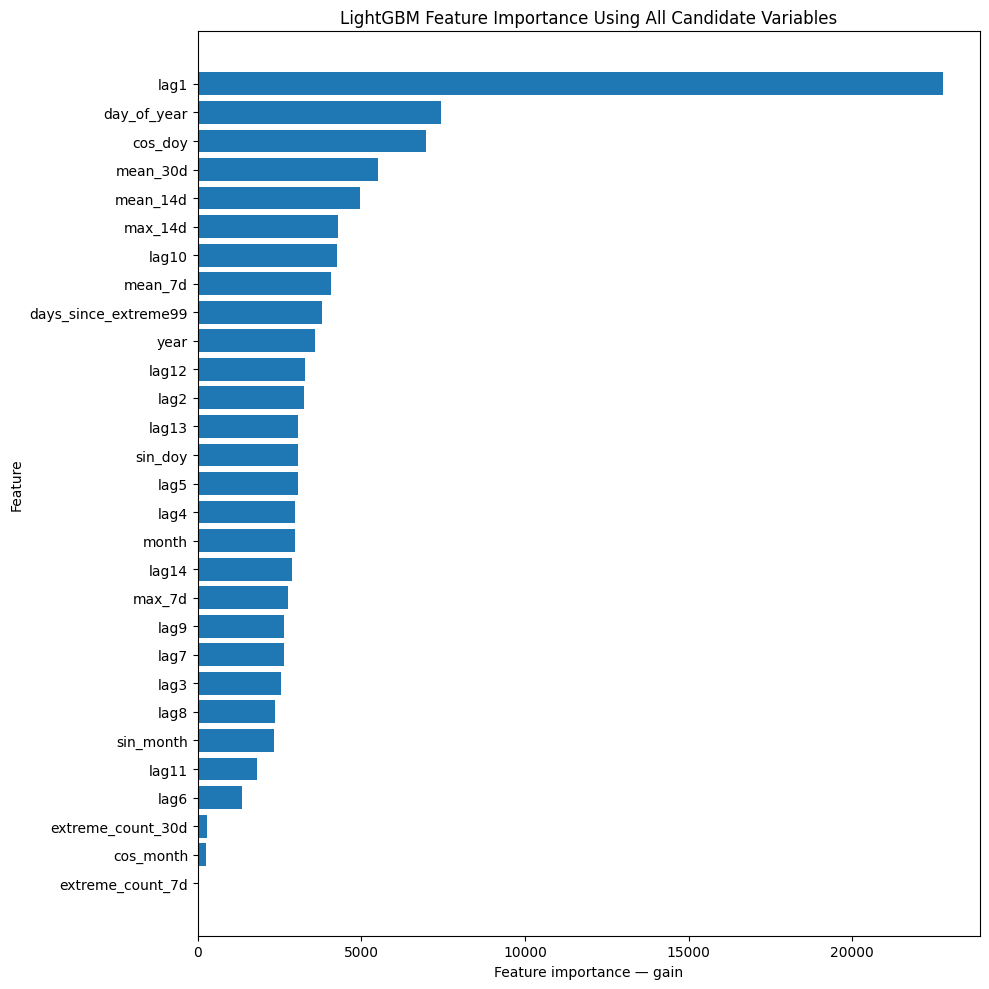


Selected top 15 features:
lag1
day_of_year
cos_doy
mean_30d
mean_14d
max_14d
lag10
mean_7d
days_since_extreme99
year
lag12
lag2
lag13
sin_doy
lag5

Excluded features:
lag4
month
lag14
max_7d
lag9
lag7
lag3
lag8
sin_month
lag11
lag6
extreme_count_30d
cos_month
extreme_count_7d

Final LightGBM model fitted using selected features.

Final LGBMClassifier performance on training set
------------------------------------------------
ROC-AUC            : 0.8734
PR-AUC             : 0.2294
Brier              : 0.1666
Baseline prevalence: 0.0381


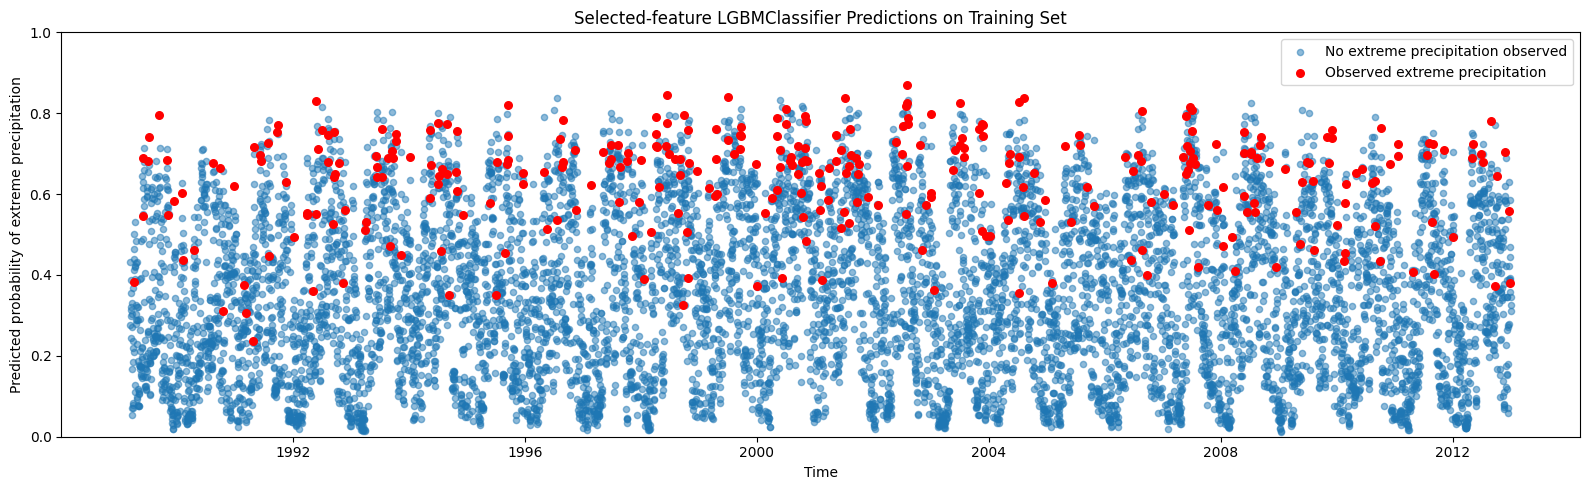


Final LGBMClassifier performance on test set
--------------------------------------------
ROC-AUC            : 0.6648
PR-AUC             : 0.0863
Brier              : 0.1538
Baseline prevalence: 0.0388


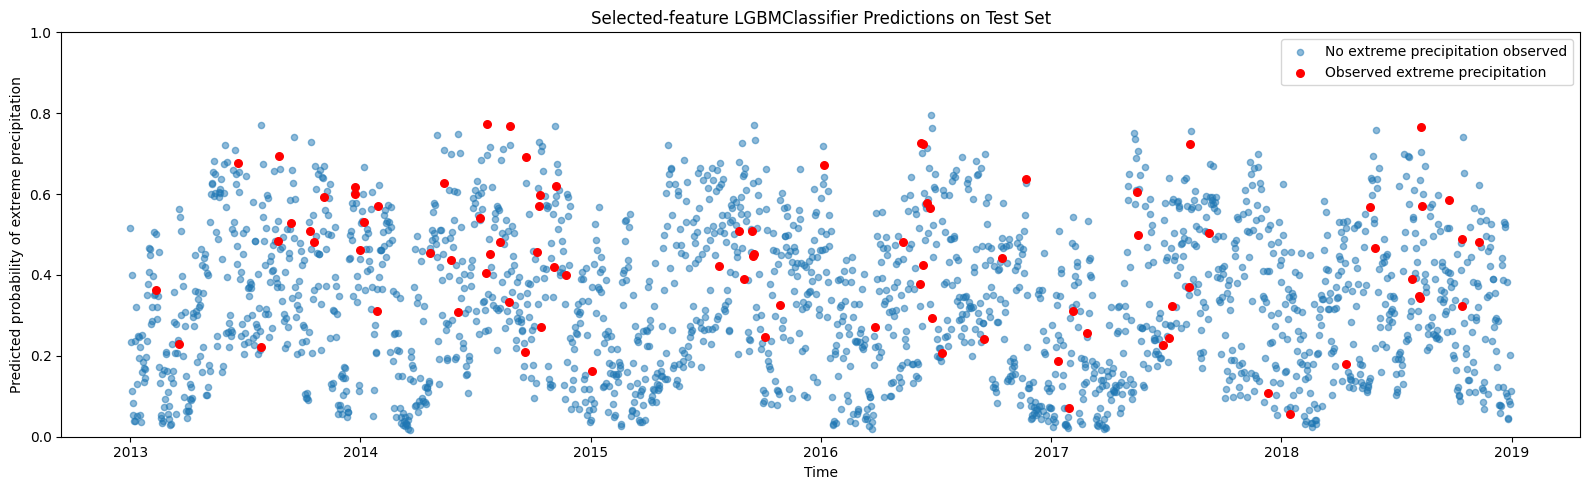


LightGBM performance summary
----------------------------
        Dataset  ROC-AUC  PR-AUC   Brier  Extreme prevalence
0  Training set   0.8734  0.2294  0.1666              0.0381
1      Test set   0.6648  0.0863  0.1538              0.0388


In [ ]:
# Number of variables retained after importance screening
n_selected_features = 15

# Remove accidental duplicate feature names
selected_features_lgbm_all = list(
    dict.fromkeys(selected_features_lgbm_all)
)

# Check whether all variables exist
missing_features = [
    feature
    for feature in selected_features_lgbm_all
    if feature not in train.columns
]

if missing_features:
    raise KeyError(
        "The following variables are missing from train:\n"
        + "\n".join(missing_features)
    )

# ============================================================
# 2. Prepare complete training data
# ============================================================

train_lgbm_all = train[
    selected_features_lgbm_all + [target]
].dropna().sort_index().copy()

X_train_lgbm_all = train_lgbm_all[
    selected_features_lgbm_all
]

y_train_lgbm_all = train_lgbm_all[
    target
].astype(int)

if y_train_lgbm_all.nunique() < 2:
    raise ValueError(
        "The training set must contain both extreme=0 and extreme=1."
    )

n_positive = int((y_train_lgbm_all == 1).sum())
n_negative = int((y_train_lgbm_all == 0).sum())

scale_pos_weight_lgbm = (
    n_negative / n_positive
)

print("Full training-set class counts")
print("--------------------------------")
print("Non-extreme observations:", n_negative)
print("Extreme observations:", n_positive)
print(
    "scale_pos_weight:",
    round(scale_pos_weight_lgbm, 4)
)

# ============================================================
# 3. First LightGBM model using all candidate variables
# ============================================================

lgbm_clf_all = LGBMClassifier(
    objective="binary",

    n_estimators=200,
    learning_rate=0.03,

    # Conservative tree structure
    num_leaves=7,
    max_depth=3,
    min_child_samples=30,

    # Row and feature subsampling
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,

    # Regularisation
    reg_alpha=0.5,
    reg_lambda=5.0,

    scale_pos_weight=scale_pos_weight_lgbm,

    # Use gain-based importance
    importance_type="gain",

    random_state=random_state,
    n_jobs=-1,
    verbosity=-1
)

lgbm_clf_all.fit(
    X_train_lgbm_all,
    y_train_lgbm_all
)

print("\nInitial LightGBM model fitted using all features.")

# ============================================================
# 4. Generate feature-importance ranking
# ============================================================

feature_importance_lgbm = pd.DataFrame({
    "Feature": selected_features_lgbm_all,
    "Importance": lgbm_clf_all.feature_importances_
})

feature_importance_lgbm = (
    feature_importance_lgbm
    .sort_values(
        by="Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

# Relative importance as percentage
total_importance = feature_importance_lgbm[
    "Importance"
].sum()

if total_importance > 0:
    feature_importance_lgbm[
        "Relative_importance"
    ] = (
        feature_importance_lgbm["Importance"]
        / total_importance
    )
else:
    feature_importance_lgbm[
        "Relative_importance"
    ] = 0.0

print("\nLightGBM feature-importance ranking")
print("-----------------------------------")
print(feature_importance_lgbm)

# ============================================================
# 5. Plot all feature importances
# ============================================================

importance_plot = feature_importance_lgbm.sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 10))

plt.barh(
    importance_plot["Feature"],
    importance_plot["Importance"]
)

plt.xlabel("Feature importance — gain")
plt.ylabel("Feature")
plt.title(
    "LightGBM Feature Importance Using All Candidate Variables"
)

plt.tight_layout()
plt.show()

# ============================================================
# 6. Select top variables
# ============================================================

n_selected_features = min(
    n_selected_features,
    len(feature_importance_lgbm)
)

selected_features_lgbm_final = (
    feature_importance_lgbm
    .head(n_selected_features)["Feature"]
    .tolist()
)

excluded_features_lgbm = (
    feature_importance_lgbm
    .iloc[n_selected_features:]["Feature"]
    .tolist()
)

print(
    f"\nSelected top {len(selected_features_lgbm_final)} features:"
)

for feature in selected_features_lgbm_final:
    print(feature)

print("\nExcluded features:")

for feature in excluded_features_lgbm:
    print(feature)

# ============================================================
# 7. Prepare training data using selected features
# ============================================================

train_eval_lgbm = train[
    selected_features_lgbm_final + [target]
].dropna().sort_index().copy()

X_train_lgbm_final = train_eval_lgbm[
    selected_features_lgbm_final
]

y_train_lgbm_final = train_eval_lgbm[
    target
].astype(int)

n_positive_final = int(
    (y_train_lgbm_final == 1).sum()
)

n_negative_final = int(
    (y_train_lgbm_final == 0).sum()
)

scale_pos_weight_final = (
    n_negative_final / n_positive_final
)

# ============================================================
# 8. Refit LightGBM using selected variables
# ============================================================

lgbm_clf_final = LGBMClassifier(
    objective="binary",

    n_estimators=200,
    learning_rate=0.03,

    num_leaves=7,
    max_depth=3,
    min_child_samples=30,

    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,

    reg_alpha=0.5,
    reg_lambda=5.0,

    scale_pos_weight=scale_pos_weight_final,

    importance_type="gain",

    random_state=random_state,
    n_jobs=-1,
    verbosity=-1
)

lgbm_clf_final.fit(
    X_train_lgbm_final,
    y_train_lgbm_final
)

print("\nFinal LightGBM model fitted using selected features.")

# ============================================================
# 9. Predict probabilities on the complete training set
# ============================================================

p_lgbm_train = lgbm_clf_final.predict_proba(
    X_train_lgbm_final
)[:, 1]

train_eval_lgbm["p_lgbm"] = p_lgbm_train

# ============================================================
# 10. Training-set metrics
# ============================================================

roc_auc_lgbm_train = roc_auc_score(
    y_train_lgbm_final,
    p_lgbm_train
)

pr_auc_lgbm_train = average_precision_score(
    y_train_lgbm_final,
    p_lgbm_train
)

brier_lgbm_train = brier_score_loss(
    y_train_lgbm_final,
    p_lgbm_train
)

train_prevalence_lgbm = (
    y_train_lgbm_final.mean()
)

print("\nFinal LGBMClassifier performance on training set")
print("------------------------------------------------")
print(f"ROC-AUC            : {roc_auc_lgbm_train:.4f}")
print(f"PR-AUC             : {pr_auc_lgbm_train:.4f}")
print(f"Brier              : {brier_lgbm_train:.4f}")
print(f"Baseline prevalence: {train_prevalence_lgbm:.4f}")

# ============================================================
# 11. Plot training-set predicted probabilities
# ============================================================

train_non_extreme_mask = (
    train_eval_lgbm[target] == 0
)

train_extreme_mask = (
    train_eval_lgbm[target] == 1
)

plt.figure(figsize=(16, 5))

# Actual non-extreme days
plt.scatter(
    train_eval_lgbm.index[train_non_extreme_mask],
    train_eval_lgbm.loc[
        train_non_extreme_mask,
        "p_lgbm"
    ],
    s=20,
    alpha=0.5,
    label="No extreme precipitation observed",
    zorder=2
)

# Actual extreme days
plt.scatter(
    train_eval_lgbm.index[train_extreme_mask],
    train_eval_lgbm.loc[
        train_extreme_mask,
        "p_lgbm"
    ],
    color="red",
    s=30,
    alpha=1.0,
    label="Observed extreme precipitation",
    zorder=3
)

plt.xlabel("Time")
plt.ylabel(
    "Predicted probability of extreme precipitation"
)

plt.title(
    "Selected-feature LGBMClassifier Predictions "
    "on Training Set"
)

plt.ylim(0, 1)

plt.legend(
    loc="upper right"
)

plt.tight_layout()
plt.show()

# ============================================================
# 12. Prepare test set using exactly the same variables
# ============================================================

test_eval_lgbm = test[
    selected_features_lgbm_final + [target]
].dropna().sort_index().copy()

X_test_lgbm_final = test_eval_lgbm[
    selected_features_lgbm_final
]

y_test_lgbm_final = test_eval_lgbm[
    target
].astype(int)

if y_test_lgbm_final.nunique() < 2:
    raise ValueError(
        "The test set must contain both extreme=0 and extreme=1 "
        "to calculate ROC-AUC."
    )

# ============================================================
# 13. Predict test-set probabilities
# ============================================================

p_lgbm_test = lgbm_clf_final.predict_proba(
    X_test_lgbm_final
)[:, 1]

test_eval_lgbm["p_lgbm"] = p_lgbm_test

# ============================================================
# 14. Test-set metrics
# ============================================================

roc_auc_lgbm_test = roc_auc_score(
    y_test_lgbm_final,
    p_lgbm_test
)

pr_auc_lgbm_test = average_precision_score(
    y_test_lgbm_final,
    p_lgbm_test
)

brier_lgbm_test = brier_score_loss(
    y_test_lgbm_final,
    p_lgbm_test
)

test_prevalence_lgbm = (
    y_test_lgbm_final.mean()
)

print("\nFinal LGBMClassifier performance on test set")
print("--------------------------------------------")
print(f"ROC-AUC            : {roc_auc_lgbm_test:.4f}")
print(f"PR-AUC             : {pr_auc_lgbm_test:.4f}")
print(f"Brier              : {brier_lgbm_test:.4f}")
print(f"Baseline prevalence: {test_prevalence_lgbm:.4f}")

# ============================================================
# 15. Plot test-set predicted probabilities
# ============================================================

test_non_extreme_mask = (
    test_eval_lgbm[target] == 0
)

test_extreme_mask = (
    test_eval_lgbm[target] == 1
)

plt.figure(figsize=(16, 5))

# Actual non-extreme days
plt.scatter(
    test_eval_lgbm.index[test_non_extreme_mask],
    test_eval_lgbm.loc[
        test_non_extreme_mask,
        "p_lgbm"
    ],
    s=20,
    alpha=0.5,
    label="No extreme precipitation observed",
    zorder=2
)

# Actual extreme days
plt.scatter(
    test_eval_lgbm.index[test_extreme_mask],
    test_eval_lgbm.loc[
        test_extreme_mask,
        "p_lgbm"
    ],
    color="red",
    s=30,
    alpha=1.0,
    label="Observed extreme precipitation",
    zorder=3
)

plt.xlabel("Time")
plt.ylabel(
    "Predicted probability of extreme precipitation"
)

plt.title(
    "Selected-feature LGBMClassifier Predictions "
    "on Test Set"
)

plt.ylim(0, 1)

plt.legend(
    loc="upper right"
)

plt.tight_layout()
plt.show()

# ============================================================
# 16. Training/test comparison table
# ============================================================

lgbm_metrics_summary = pd.DataFrame({
    "Dataset": [
        "Training set",
        "Test set"
    ],
    "ROC-AUC": [
        roc_auc_lgbm_train,
        roc_auc_lgbm_test
    ],
    "PR-AUC": [
        pr_auc_lgbm_train,
        pr_auc_lgbm_test
    ],
    "Brier": [
        brier_lgbm_train,
        brier_lgbm_test
    ],
    "Extreme prevalence": [
        train_prevalence_lgbm,
        test_prevalence_lgbm
    ]
})

print("\nLightGBM performance summary")
print("----------------------------")
print(lgbm_metrics_summary.round(4))

# LightGBM Regressor

Number of extreme training observations: 331

Cross-validation fold information:
 Fold  Train_extremes  Validation_extremes Train_start  Train_end Validation_start Validation_end
    1              67                   66  1989-04-05 1994-07-31       1994-08-31     1999-04-24
    2             133                   66  1989-04-05 1999-04-24       1999-07-05     2002-08-10
    3             199                   66  1989-04-05 2002-08-10       2002-10-22     2007-07-20
    4             265                   66  1989-04-05 2007-07-20       2007-08-07     2012-12-22

Feature count cross-validation results:
 N_features  Mean_RMSE  Std_RMSE  Mean_MAE  Std_MAE  Mean_R2  Std_R2
          5     0.5964    0.1702    0.4137   0.0568  -0.0635  0.1124
         10     0.5954    0.1846    0.4100   0.0654  -0.0461  0.0588
         15     0.5927    0.1764    0.4064   0.0652  -0.0422  0.0575
         20     0.5928    0.1756    0.4065   0.0672  -0.0443  0.0924
         25     0.5932    0.1767    0.4041 

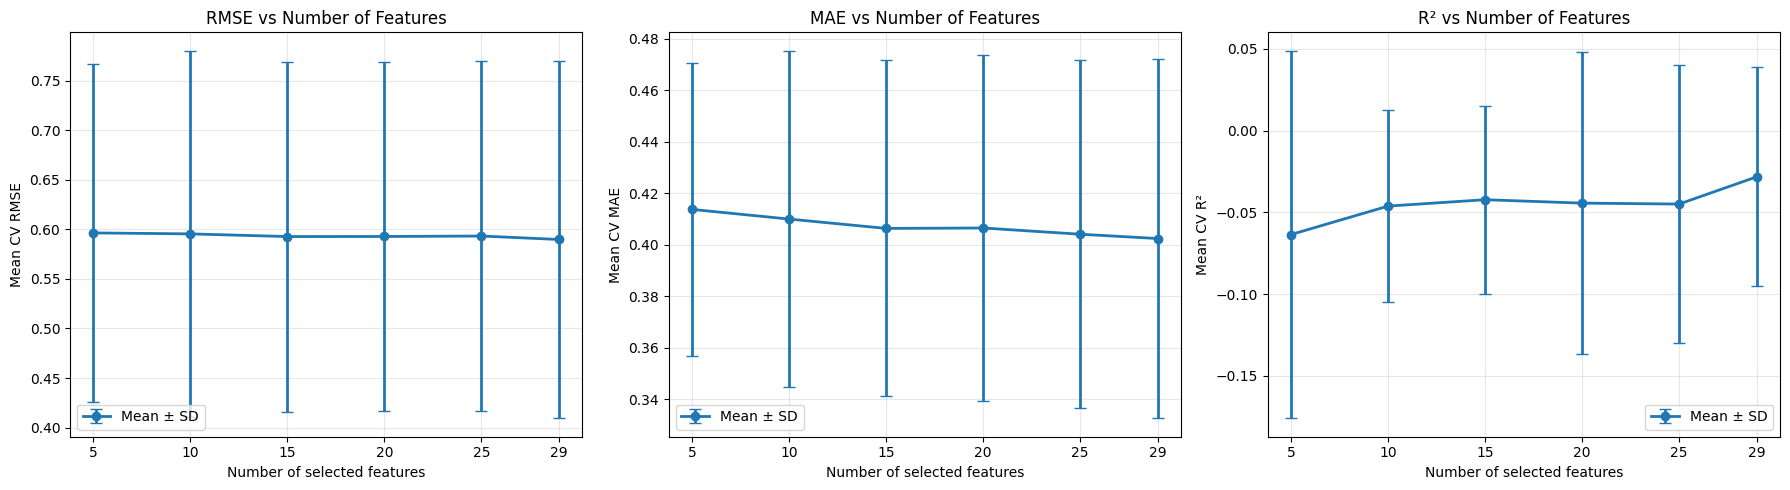

In [ ]:
# ============================================================
# 1. Settings
# ============================================================

selected_features_lgbm_reg_all = [
    'year', 'month',
    'lag1', 'lag2', 'lag3', 'lag4', 'lag5', 'lag6', 'lag7',
    'lag8', 'lag9', 'lag10', 'lag11', 'lag12', 'lag13', 'lag14',
    'mean_7d', 'mean_14d', 'mean_30d',
    'max_7d', 'max_14d',
    'extreme_count_7d', 'extreme_count_30d',
    'day_of_year', 'sin_doy', 'cos_doy',
    'sin_month', 'cos_month',
    'days_since_extreme99'
]

target_reg = "index_max"
random_state = 42

candidate_n_features = [5, 10, 15, 20, 25, 29]
n_splits = 4

# Remove duplicate feature names
selected_features_lgbm_reg_all = list(
    dict.fromkeys(selected_features_lgbm_reg_all)
)

candidate_n_features = [
    k for k in candidate_n_features
    if k <= len(selected_features_lgbm_reg_all)
]

# ============================================================
# 2. Prepare training data
#    Only true extreme observations
# ============================================================

missing_features = [
    feature
    for feature in selected_features_lgbm_reg_all + [target_reg]
    if feature not in train.columns
]

if missing_features:
    raise KeyError(
        "Missing columns in train:\n"
        + "\n".join(missing_features)
    )

train_cv_lgbm_reg = train[
    selected_features_lgbm_reg_all + [target_reg]
].dropna().sort_index().copy()

train_cv_lgbm_reg = train_cv_lgbm_reg[
    train_cv_lgbm_reg[target_reg] > 1
].copy()

X_cv = train_cv_lgbm_reg[
    selected_features_lgbm_reg_all
]

y_cv = train_cv_lgbm_reg[target_reg]

print("Number of extreme training observations:", len(y_cv))

if len(y_cv) < n_splits + 2:
    raise ValueError(
        "Insufficient extreme observations for cross-validation."
    )

# ============================================================
# 3. Define LGBMRegressor
#    Same hyperparameters as the final model
# ============================================================

def create_lgbm_reg_cv():

    return LGBMRegressor(
        objective="regression",

        n_estimators=150,
        learning_rate=0.03,

        num_leaves=7,
        max_depth=3,
        min_child_samples=5,

        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,

        reg_alpha=0.5,
        reg_lambda=5.0,

        importance_type="gain",

        random_state=random_state,
        n_jobs=-1,
        verbosity=-1
    )

# ============================================================
# 4. Time-series cross-validation
# ============================================================

tscv = TimeSeriesSplit(n_splits=n_splits)

cv_results = []
fold_info = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_cv), start=1
):

    X_tr_all = X_cv.iloc[train_idx]
    X_val_all = X_cv.iloc[val_idx]

    y_tr = y_cv.iloc[train_idx]
    y_val = y_cv.iloc[val_idx]

    # Log-transform training target only
    y_tr_log = np.log1p(y_tr)

    fold_info.append({
        "Fold": fold,
        "Train_extremes": len(y_tr),
        "Validation_extremes": len(y_val),
        "Train_start": X_tr_all.index[0],
        "Train_end": X_tr_all.index[-1],
        "Validation_start": X_val_all.index[0],
        "Validation_end": X_val_all.index[-1]
    })

    # --------------------------------------------------------
    # Initial model for Gain-based feature ranking
    # --------------------------------------------------------

    ranking_model = create_lgbm_reg_cv()

    ranking_model.fit(
        X_tr_all,
        y_tr_log
    )

    importance = pd.DataFrame({
        "Feature": X_tr_all.columns,
        "Gain": ranking_model.feature_importances_
    }).sort_values(
        ["Gain", "Feature"],
        ascending=[False, True]
    )

    ranked_features = importance["Feature"].tolist()

    # --------------------------------------------------------
    # Evaluate different feature counts
    # --------------------------------------------------------

    for k in candidate_n_features:

        features_k = ranked_features[:k]

        model = create_lgbm_reg_cv()

        model.fit(
            X_tr_all[features_k],
            y_tr_log
        )

        # Predict on log scale
        pred_log = model.predict(
            X_val_all[features_k]
        )

        # Convert predictions back to original scale
        y_pred = np.expm1(pred_log)

        y_pred = np.maximum(y_pred, 0)

        # Evaluate on original scale
        rmse = np.sqrt(
            mean_squared_error(y_val, y_pred)
        )

        mae = mean_absolute_error(
            y_val, y_pred
        )

        r2 = (
            r2_score(y_val, y_pred)
            if len(y_val) >= 2
            else np.nan
        )

        cv_results.append({
            "Fold": fold,
            "N_features": k,
            "RMSE": rmse,
            "MAE": mae,
            "R2": r2
        })

# ============================================================
# 5. Cross-validation summary
# ============================================================

cv_results_df = pd.DataFrame(cv_results)
fold_info_df = pd.DataFrame(fold_info)

cv_summary = (
    cv_results_df
    .groupby("N_features")
    .agg(
        Mean_RMSE=("RMSE", "mean"),
        Std_RMSE=("RMSE", "std"),
        Mean_MAE=("MAE", "mean"),
        Std_MAE=("MAE", "std"),
        Mean_R2=("R2", "mean"),
        Std_R2=("R2", "std")
    )
    .reset_index()
    .sort_values("N_features")
)

print("\nCross-validation fold information:")
print(fold_info_df.to_string(index=False))

print("\nFeature count cross-validation results:")
print(cv_summary.round(4).to_string(index=False))

# ============================================================
# 6. Determine optimal feature count
#    Minimum mean RMSE
# ============================================================

best_row = cv_summary.loc[
    cv_summary["Mean_RMSE"].idxmin()
]

best_n_features_reg = int(best_row["N_features"])

print("\n====================================")
print("Optimal number of features:", best_n_features_reg)
print(
    "Best mean CV RMSE:",
    round(best_row["Mean_RMSE"], 4)
)
print("====================================")

# ============================================================
# 7. Plot cross-validation metrics
#    Three equally sized plots in one row
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = [
    ("Mean_RMSE", "Std_RMSE", "RMSE"),
    ("Mean_MAE", "Std_MAE", "MAE"),
    ("Mean_R2", "Std_R2", "R²")
]

for ax, (mean_col, std_col, metric_name) in zip(axes, metrics):

    ax.errorbar(
        cv_summary["N_features"],
        cv_summary[mean_col],
        yerr=cv_summary[std_col],
        marker="o",
        linewidth=2,
        capsize=4,
        label="Mean ± SD"
    )

    ax.set_title(
        f"{metric_name} vs Number of Features"
    )

    ax.set_xlabel("Number of selected features")
    ax.set_ylabel(f"Mean CV {metric_name}")
    ax.set_xticks(candidate_n_features)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# 1. Define candidate features and settings
# ============================================================

selected_features_lgbm_reg_all = [
    'year', 'month',
    'lag1', 'lag2', 'lag3', 'lag4', 'lag5', 'lag6', 'lag7',
    'lag8', 'lag9', 'lag10', 'lag11', 'lag12', 'lag13', 'lag14',
    'mean_7d', 'mean_14d', 'mean_30d',
    'max_7d', 'max_14d',
    'extreme_count_7d', 'extreme_count_30d',
    'day_of_year', 'sin_doy', 'cos_doy',
    'sin_month', 'cos_month',
    'days_since_extreme99'
]

target_reg = "index_max"
random_state = 42
n_selected_features_reg = 15

# Remove duplicate feature names
selected_features_lgbm_reg_all = list(
    dict.fromkeys(selected_features_lgbm_reg_all)
)

Number of extreme training observations: 331

Original training target summary:
count    331.000000
mean       1.593683
std        0.602161
min        1.000864
25%        1.202903
50%        1.456920
75%        1.751167
max        6.458780
Name: index_max, dtype: float64

Log-transformed training target summary:
count    331.000000
mean       0.932257
std        0.193974
min        0.693579
25%        0.789776
50%        0.898909
75%        1.012025
max        2.009392
Name: index_max, dtype: float64

Initial LGBMRegressor fitted using all features.

LGBMRegressor feature importance ranking:
                 Feature  Importance  Relative_importance
0                cos_doy    8.724911             0.101227
1                   lag5    6.034343             0.070011
2                   lag2    5.775707             0.067010
3                   lag1    5.683833             0.065944
4                  lag12    4.698134             0.054508
5   days_since_extreme99    4.117053             0.04

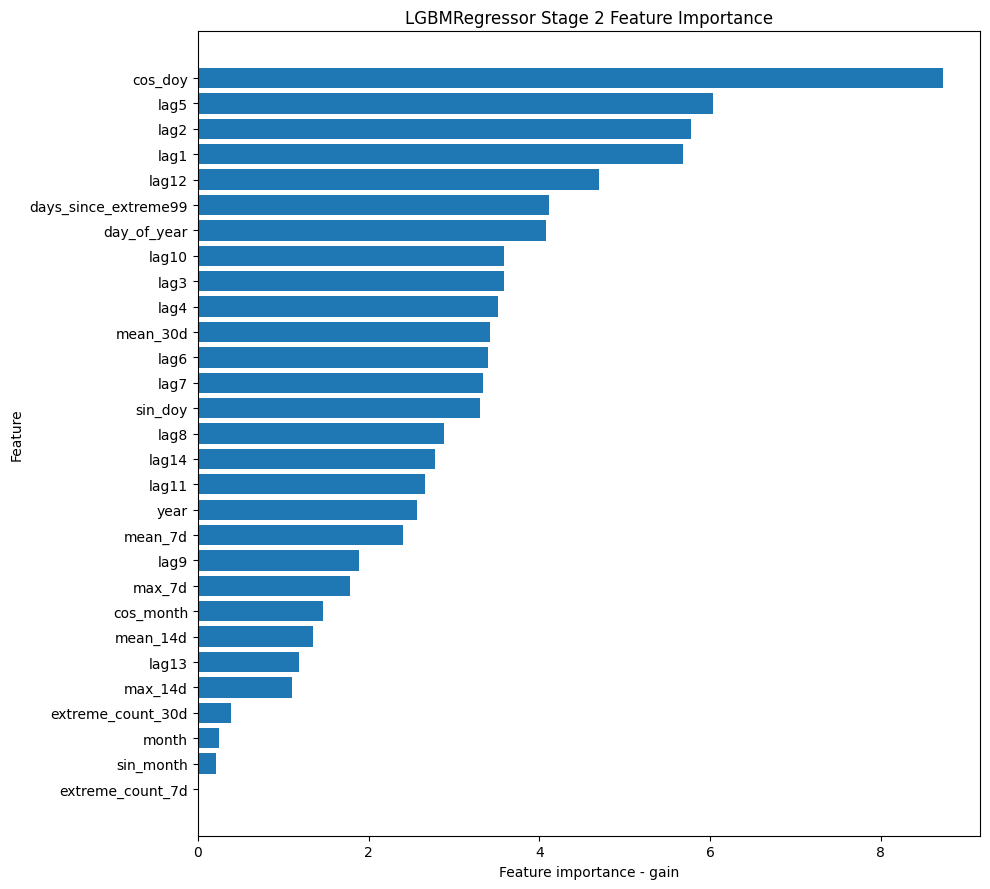


Selected top 15 features:
cos_doy
lag5
lag2
lag1
lag12
days_since_extreme99
day_of_year
lag10
lag3
lag4
mean_30d
lag6
lag7
sin_doy
lag8

Excluded features:
lag14
lag11
year
mean_7d
lag9
max_7d
cos_month
mean_14d
lag13
max_14d
extreme_count_30d
month
sin_month
extreme_count_7d

Final LGBMRegressor fitted using selected features.

Number of extreme test observations: 85


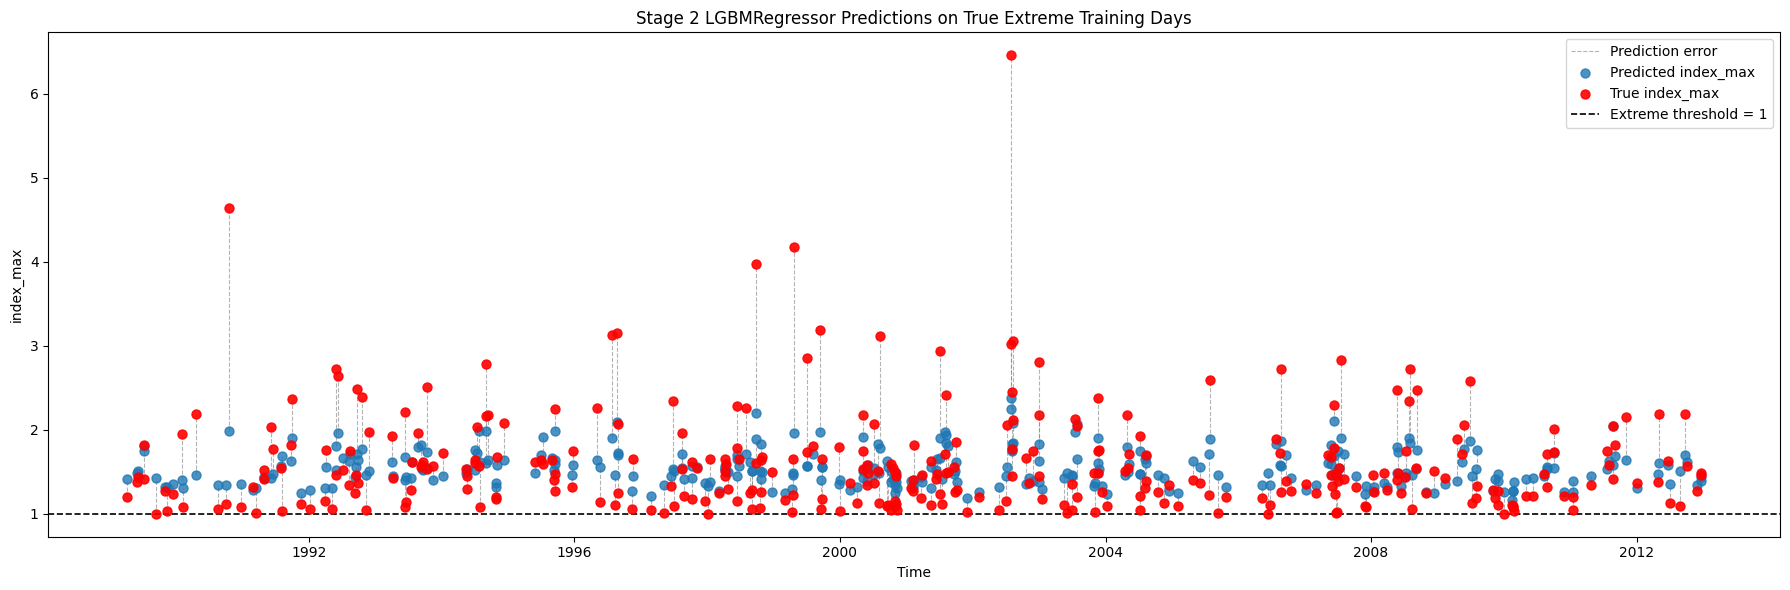

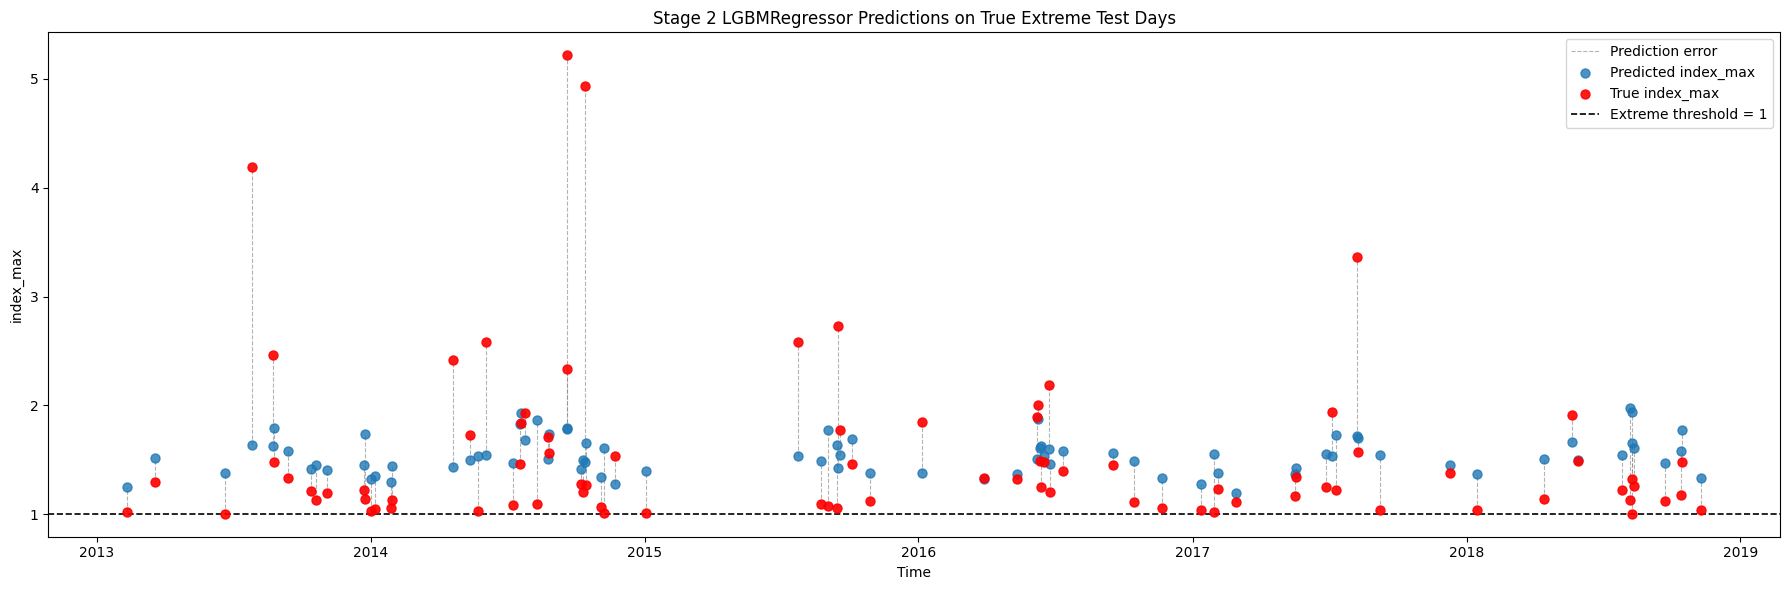


LGBMRegressor Stage 2 performance summary
------------------------------------------------
     Dataset  N_extreme   RMSE    MAE     R2
Training set        331 0.4736 0.3016 0.3795
    Test set         85 0.7545 0.4744 0.0570


In [ ]:
# ============================================================
# 2. Check whether all features exist
# ============================================================

for dataset_name, dataset in [
    ("train", train),
    ("test", test)
]:
    missing_features = [
        feature
        for feature in selected_features_lgbm_reg_all + [target_reg]
        if feature not in dataset.columns
    ]

    if missing_features:
        raise KeyError(
            f"Missing columns in {dataset_name}:\n"
            + "\n".join(missing_features)
        )

# ============================================================
# 3. Prepare training data
#    Use only true extreme observations: index_max > 1
# ============================================================

train_lgbm_reg = train[
    selected_features_lgbm_reg_all + [target_reg]
].dropna().sort_index().copy()

train_lgbm_reg_extreme = train_lgbm_reg[
    train_lgbm_reg[target_reg] > 1
].copy()

if len(train_lgbm_reg_extreme) < 2:
    raise ValueError(
        "Insufficient extreme observations in training set."
    )

X_train_lgbm_reg_all = train_lgbm_reg_extreme[
    selected_features_lgbm_reg_all
]

# Log-transform target
y_train_lgbm_reg_log = np.log1p(
    train_lgbm_reg_extreme[target_reg]
)

print(
    "Number of extreme training observations:",
    len(train_lgbm_reg_extreme)
)

print("\nOriginal training target summary:")
print(train_lgbm_reg_extreme[target_reg].describe())

print("\nLog-transformed training target summary:")
print(y_train_lgbm_reg_log.describe())

# ============================================================
# 4. Define LGBMRegressor
# ============================================================

def create_lgbm_reg():

    return LGBMRegressor(
        objective="regression",

        n_estimators=150,
        learning_rate=0.03,

        num_leaves=7,
        max_depth=3,
        min_child_samples=5,

        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,

        reg_alpha=0.5,
        reg_lambda=5.0,

        importance_type="gain",

        random_state=random_state,
        n_jobs=-1,
        verbosity=-1
    )

# ============================================================
# 5. Fit initial model using all candidate features
# ============================================================

lgbm_reg_all = create_lgbm_reg()

lgbm_reg_all.fit(
    X_train_lgbm_reg_all,
    y_train_lgbm_reg_log
)

print("\nInitial LGBMRegressor fitted using all features.")

# ============================================================
# 6. Calculate Gain-based feature importance
# ============================================================

feature_importance_lgbm_reg = pd.DataFrame({
    "Feature": selected_features_lgbm_reg_all,
    "Importance": lgbm_reg_all.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Relative importance
total_importance = feature_importance_lgbm_reg[
    "Importance"
].sum()

if total_importance > 0:
    feature_importance_lgbm_reg[
        "Relative_importance"
    ] = (
        feature_importance_lgbm_reg["Importance"]
        / total_importance
    )
else:
    feature_importance_lgbm_reg[
        "Relative_importance"
    ] = 0.0

print("\nLGBMRegressor feature importance ranking:")
print(feature_importance_lgbm_reg)

# ============================================================
# 7. Plot feature importance using all candidate features
# ============================================================

importance_plot = feature_importance_lgbm_reg.sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 9))

plt.barh(
    importance_plot["Feature"],
    importance_plot["Importance"]
)

plt.xlabel("Feature importance - gain")
plt.ylabel("Feature")
plt.title(
    "LGBMRegressor Stage 2 Feature Importance"
)

plt.tight_layout()
plt.show()

# ============================================================
# 8. Select top 15 features
# ============================================================

n_selected_features_reg = min(
    n_selected_features_reg,
    len(feature_importance_lgbm_reg)
)

selected_features_lgbm_reg_final = (
    feature_importance_lgbm_reg
    .head(n_selected_features_reg)["Feature"]
    .tolist()
)

excluded_features_lgbm_reg = (
    feature_importance_lgbm_reg
    .iloc[n_selected_features_reg:]["Feature"]
    .tolist()
)

print(
    f"\nSelected top {len(selected_features_lgbm_reg_final)} features:"
)

for feature in selected_features_lgbm_reg_final:
    print(feature)

print("\nExcluded features:")

for feature in excluded_features_lgbm_reg:
    print(feature)

# ============================================================
# 9. Refit final LGBMRegressor using selected features
# ============================================================

X_train_lgbm_reg_final = train_lgbm_reg_extreme[
    selected_features_lgbm_reg_final
]

lgbm_reg_stage2 = create_lgbm_reg()

lgbm_reg_stage2.fit(
    X_train_lgbm_reg_final,
    y_train_lgbm_reg_log
)

print("\nFinal LGBMRegressor fitted using selected features.")

# ============================================================
# 10. Predict on extreme training observations
# ============================================================

y_true_lgbm_reg_train = (
    train_lgbm_reg_extreme[target_reg].to_numpy()
)

pred_log_lgbm_reg_train = lgbm_reg_stage2.predict(
    X_train_lgbm_reg_final
)

# Convert predictions back to original scale
y_pred_lgbm_reg_train = np.expm1(
    pred_log_lgbm_reg_train
)

y_pred_lgbm_reg_train = np.maximum(
    y_pred_lgbm_reg_train,
    0
)

train_lgbm_reg_extreme[
    "pred_index_lgbm"
] = y_pred_lgbm_reg_train

# ============================================================
# 11. Prepare test data
#     Only true extreme observations
# ============================================================

test_lgbm_reg = test[
    selected_features_lgbm_reg_final + [target_reg]
].dropna().sort_index().copy()

test_lgbm_reg_extreme = test_lgbm_reg[
    test_lgbm_reg[target_reg] > 1
].copy()

if len(test_lgbm_reg_extreme) < 2:
    raise ValueError(
        "Insufficient extreme observations in test set."
    )

X_test_lgbm_reg_final = test_lgbm_reg_extreme[
    selected_features_lgbm_reg_final
]

y_true_lgbm_reg_test = (
    test_lgbm_reg_extreme[target_reg].to_numpy()
)

print(
    "\nNumber of extreme test observations:",
    len(test_lgbm_reg_extreme)
)

# ============================================================
# 12. Predict on extreme test observations
# ============================================================

pred_log_lgbm_reg_test = lgbm_reg_stage2.predict(
    X_test_lgbm_reg_final
)

# Convert predictions back to original scale
y_pred_lgbm_reg_test = np.expm1(
    pred_log_lgbm_reg_test
)

y_pred_lgbm_reg_test = np.maximum(
    y_pred_lgbm_reg_test,
    0
)

test_lgbm_reg_extreme[
    "pred_index_lgbm"
] = y_pred_lgbm_reg_test

# ============================================================
# 13. Plot true vs predicted values
#     Training and test sets separately
# ============================================================

def plot_lgbm_reg_predictions(
    df,
    y_true,
    y_pred,
    dataset_name
):

    plt.figure(figsize=(18, 6))

    # Prediction errors
    plt.vlines(
        x=df.index,
        ymin=np.minimum(y_true, y_pred),
        ymax=np.maximum(y_true, y_pred),
        colors="grey",
        linestyles="--",
        linewidth=0.8,
        alpha=0.6,
        label="Prediction error",
        zorder=1
    )

    # Predicted values
    plt.scatter(
        df.index,
        y_pred,
        s=42,
        alpha=0.8,
        label="Predicted index_max",
        zorder=2
    )

    # True values
    plt.scatter(
        df.index,
        y_true,
        color="red",
        s=42,
        alpha=0.9,
        label="True index_max",
        zorder=3
    )

    # Extreme threshold
    plt.axhline(
        y=1,
        color="black",
        linestyle="--",
        linewidth=1.2,
        label="Extreme threshold = 1"
    )

    plt.xlabel("Time")
    plt.ylabel("index_max")

    plt.title(
        f"Stage 2 LGBMRegressor Predictions "
        f"on True Extreme {dataset_name} Days"
    )

    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()


# Training set plot
plot_lgbm_reg_predictions(
    train_lgbm_reg_extreme,
    y_true_lgbm_reg_train,
    y_pred_lgbm_reg_train,
    "Training"
)

# Test set plot
plot_lgbm_reg_predictions(
    test_lgbm_reg_extreme,
    y_true_lgbm_reg_test,
    y_pred_lgbm_reg_test,
    "Test"
)

# ============================================================
# 14. Calculate evaluation metrics
#     Original scale, true extreme observations only
# ============================================================

rmse_lgbm_reg_train = np.sqrt(
    mean_squared_error(
        y_true_lgbm_reg_train,
        y_pred_lgbm_reg_train
    )
)

mae_lgbm_reg_train = mean_absolute_error(
    y_true_lgbm_reg_train,
    y_pred_lgbm_reg_train
)

r2_lgbm_reg_train = r2_score(
    y_true_lgbm_reg_train,
    y_pred_lgbm_reg_train
)

rmse_lgbm_reg_test = np.sqrt(
    mean_squared_error(
        y_true_lgbm_reg_test,
        y_pred_lgbm_reg_test
    )
)

mae_lgbm_reg_test = mean_absolute_error(
    y_true_lgbm_reg_test,
    y_pred_lgbm_reg_test
)

r2_lgbm_reg_test = r2_score(
    y_true_lgbm_reg_test,
    y_pred_lgbm_reg_test
)

# ============================================================
# 15. Training/test performance comparison
# ============================================================

lgbm_reg_metrics_summary = pd.DataFrame({
    "Dataset": [
        "Training set",
        "Test set"
    ],
    "N_extreme": [
        len(y_true_lgbm_reg_train),
        len(y_true_lgbm_reg_test)
    ],
    "RMSE": [
        rmse_lgbm_reg_train,
        rmse_lgbm_reg_test
    ],
    "MAE": [
        mae_lgbm_reg_train,
        mae_lgbm_reg_test
    ],
    "R2": [
        r2_lgbm_reg_train,
        r2_lgbm_reg_test
    ]
})

print("\nLGBMRegressor Stage 2 performance summary")
print("------------------------------------------------")

print(
    lgbm_reg_metrics_summary.round(4).to_string(
        index=False
    )
)

# LSTM Classifier

In [ ]:
warnings.filterwarnings("ignore")

random_state = 42

os.environ["PYTHONHASHSEED"] = str(random_state)
random.seed(random_state)
np.random.seed(random_state)
tf.random.set_seed(random_state)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
# ============================================================
# 1. Combine train and test while retaining split information
# ============================================================

target = "extreme"

train_lstm_source = train.copy()
test_lstm_source = test.copy()

train_lstm_source["dataset_split"] = "train"
test_lstm_source["dataset_split"] = "test"

full_lstm_data = pd.concat(
    [train_lstm_source, test_lstm_source],
    axis=0
)

# If date is stored as a column, move it to the index
if "date" in full_lstm_data.columns:
    full_lstm_data["date"] = pd.to_datetime(
        full_lstm_data["date"]
    )

    full_lstm_data = (
        full_lstm_data
        .sort_values("date")
        .set_index("date")
    )
else:
    full_lstm_data.index = pd.to_datetime(
        full_lstm_data.index
    )

    full_lstm_data = full_lstm_data.sort_index()

# Remove duplicated dates if present
if full_lstm_data.index.duplicated().any():
    raise ValueError(
        "Duplicated dates were found in the combined dataset."
    )

print("Full data period:")
print(
    full_lstm_data.index.min(),
    "to",
    full_lstm_data.index.max()
)

print("\nSplit counts:")
print(full_lstm_data["dataset_split"].value_counts())

print("\nTarget counts:")
print(
    full_lstm_data.groupby(
        "dataset_split"
    )[target].value_counts()
)

Full data period:
1989-01-01 00:00:00 to 2018-12-31 00:00:00

Split counts:
dataset_split
train    8766
test     2191
Name: count, dtype: int64

Target counts:
dataset_split  extreme
test           0          2106
               1            85
train          0          8434
               1           332
Name: count, dtype: int64


In [ ]:
#95th
# ============================================================
# 2. Define feature groups for ablation experiments
# ============================================================

feature_sets = {
    "A_short_lags": [
        "lag1", "lag2", "lag3", "lag4",
        "lag5", "lag6", "lag7"
    ],

    "B_extended_lags": [
        f"lag{i}" for i in range(1, 15)
    ],

    "C_rainfall_extremes": [
        *[f"lag{i}" for i in range(1, 15)],
        "mean_7d", "mean_14d", "mean_30d",
        "max_7d", "max_14d",
        "extreme_count_7d",
        "extreme_count_30d"
    ],

    "D_rainfall_seasonality": [
        *[f"lag{i}" for i in range(1, 15)],
        "mean_7d", "mean_14d", "mean_30d",
        "max_7d", "max_14d",
        "extreme_count_7d",
        "extreme_count_30d",
        "sin_doy", "cos_doy"
    ]
}

# Remove accidental duplicates
feature_sets = {
    name: list(dict.fromkeys(features))
    for name, features in feature_sets.items()
}

# Check missing variables
for set_name, features in feature_sets.items():

    missing = [
        feature
        for feature in features
        if feature not in full_lstm_data.columns
    ]

    print(f"\n{set_name}")
    print("Number of requested features:", len(features))

    if missing:
        print("Missing variables:", missing)
    else:
        print("All variables are available.")


A_short_lags
Number of requested features: 7
All variables are available.

B_extended_lags
Number of requested features: 14
All variables are available.

C_rainfall_extremes
Number of requested features: 21
All variables are available.

D_rainfall_seasonality
Number of requested features: 23
All variables are available.


In [ ]:
# Keep only available features in each group
feature_sets_available = {}

for set_name, features in feature_sets.items():

    available_features = [
        feature
        for feature in features
        if feature in full_lstm_data.columns
    ]

    if len(available_features) < 2:
        print(
            f"Skipping {set_name}: "
            "fewer than two variables are available."
        )
        continue

    feature_sets_available[set_name] = available_features

print("\nFeature sets used in the experiment:")

for name, features in feature_sets_available.items():
    print(f"\n{name}: {len(features)} features")
    print(features)


Feature sets used in the experiment:

A_short_lags: 7 features
['lag1', 'lag2', 'lag3', 'lag4', 'lag5', 'lag6', 'lag7']

B_extended_lags: 14 features
['lag1', 'lag2', 'lag3', 'lag4', 'lag5', 'lag6', 'lag7', 'lag8', 'lag9', 'lag10', 'lag11', 'lag12', 'lag13', 'lag14']

C_rainfall_extremes: 21 features
['lag1', 'lag2', 'lag3', 'lag4', 'lag5', 'lag6', 'lag7', 'lag8', 'lag9', 'lag10', 'lag11', 'lag12', 'lag13', 'lag14', 'mean_7d', 'mean_14d', 'mean_30d', 'max_7d', 'max_14d', 'extreme_count_7d', 'extreme_count_30d']

D_rainfall_seasonality: 23 features
['lag1', 'lag2', 'lag3', 'lag4', 'lag5', 'lag6', 'lag7', 'lag8', 'lag9', 'lag10', 'lag11', 'lag12', 'lag13', 'lag14', 'mean_7d', 'mean_14d', 'mean_30d', 'max_7d', 'max_14d', 'extreme_count_7d', 'extreme_count_30d', 'sin_doy', 'cos_doy']


In [ ]:
# ============================================================
# 3. Function for constructing sequence samples
# ============================================================

def create_lstm_sequences(
    data,
    feature_names,
    target_name,
    lookback
):
    """
    Construct sequences using observations from:
        t-lookback, ..., t-1

    to predict the target at time t.

    Returns
    -------
    X : ndarray
        Shape: (samples, lookback, features)

    y : ndarray
        Binary targets.

    target_dates : DatetimeIndex
        Date corresponding to each target y_t.

    split_labels : ndarray
        Whether each target belongs to train or test.
    """

    required_columns = (
        feature_names
        + [target_name, "dataset_split"]
    )

    sequence_data = data[
        required_columns
    ].copy()

    X_sequences = []
    y_sequences = []
    target_dates = []
    split_labels = []

    for target_position in range(
        lookback,
        len(sequence_data)
    ):

        start_position = (
            target_position - lookback
        )

        # Past observations only
        X_window = sequence_data.iloc[
            start_position:target_position
        ][feature_names]

        target_row = sequence_data.iloc[
            target_position
        ]

        # Do not use sequences containing missing inputs
        if X_window.isna().any().any():
            continue

        if pd.isna(target_row[target_name]):
            continue

        X_sequences.append(
            X_window.to_numpy(dtype=np.float32)
        )

        y_sequences.append(
            int(target_row[target_name])
        )

        target_dates.append(
            sequence_data.index[target_position]
        )

        split_labels.append(
            target_row["dataset_split"]
        )

    X_sequences = np.asarray(
        X_sequences,
        dtype=np.float32
    )

    y_sequences = np.asarray(
        y_sequences,
        dtype=np.int32
    )

    target_dates = pd.DatetimeIndex(
        target_dates
    )

    split_labels = np.asarray(
        split_labels
    )

    return (
        X_sequences,
        y_sequences,
        target_dates,
        split_labels
    )

In [ ]:
# ============================================================
# 4. Scale three-dimensional sequence arrays
# ============================================================

def scale_sequence_data(
    X_fit,
    X_validation,
    X_test
):
    """
    Fit StandardScaler using only the model-fitting sequences.

    Scaling is performed feature by feature across all
    fitting samples and all timesteps.
    """

    n_features = X_fit.shape[2]

    scaler = StandardScaler()

    X_fit_2d = X_fit.reshape(
        -1,
        n_features
    )

    scaler.fit(X_fit_2d)

    def transform(X):
        original_shape = X.shape

        X_2d = X.reshape(
            -1,
            n_features
        )

        X_scaled = scaler.transform(
            X_2d
        )

        return X_scaled.reshape(
            original_shape
        ).astype(np.float32)

    return (
        transform(X_fit),
        transform(X_validation),
        transform(X_test),
        scaler
    )

In [ ]:
# ============================================================
# 5. Define the LSTM classifier
# ============================================================

def build_lstm_classifier(
    lookback,
    n_features,
    learning_rate=1e-3,
    lstm_units=16,
    dropout_rate=0.30,
    l2_strength=1e-3
):
    tf.keras.backend.clear_session()

    inputs = tf.keras.Input(
        shape=(lookback, n_features),
        name="sequence_input"
    )

    x = tf.keras.layers.LSTM(
        units=lstm_units,
        activation="tanh",
        recurrent_activation="sigmoid",
        return_sequences=False,
        kernel_regularizer=tf.keras.regularizers.l2(
            l2_strength
        ),
        recurrent_regularizer=tf.keras.regularizers.l2(
            l2_strength
        ),
        name="lstm_layer"
    )(inputs)

    x = tf.keras.layers.Dropout(
        dropout_rate,
        name="dropout"
    )(x)

    x = tf.keras.layers.Dense(
        8,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(
            l2_strength
        ),
        name="dense_layer"
    )(x)

    x = tf.keras.layers.Dropout(
        dropout_rate,
        name="dense_dropout"
    )(x)

    outputs = tf.keras.layers.Dense(
        1,
        activation="sigmoid",
        name="extreme_probability"
    )(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="extreme_precipitation_lstm"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.AUC(
                curve="PR",
                name="pr_auc"
            ),
            tf.keras.metrics.AUC(
                curve="ROC",
                name="roc_auc"
            ),
            tf.keras.metrics.MeanSquaredError(
                name="brier"
            )
        ]
    )

    return model

In [ ]:
# ============================================================
# 6. Fit one LSTM configuration
# ============================================================

def fit_one_lstm_configuration(
    full_data,
    feature_names,
    lookback,
    validation_fraction=0.20,
    max_epochs=100,
    batch_size=32,
    verbose=0
):
    # --------------------------------------------------------
    # Create all train and test sequences
    # --------------------------------------------------------

    (
        X_all,
        y_all,
        target_dates,
        split_labels
    ) = create_lstm_sequences(
        data=full_data,
        feature_names=feature_names,
        target_name=target,
        lookback=lookback
    )

    train_mask = split_labels == "train"
    test_mask = split_labels == "test"

    X_train_sequence = X_all[train_mask]
    y_train_sequence = y_all[train_mask]
    train_dates = target_dates[train_mask]

    X_test_sequence = X_all[test_mask]
    y_test_sequence = y_all[test_mask]
    test_dates = target_dates[test_mask]

    if len(X_train_sequence) == 0:
        raise ValueError(
            "No valid training sequences were created."
        )

    if len(X_test_sequence) == 0:
        raise ValueError(
            "No valid test sequences were created."
        )

    # --------------------------------------------------------
    # Time-ordered fitting-validation split
    # --------------------------------------------------------

    validation_size = max(
        100,
        int(
            validation_fraction
            * len(X_train_sequence)
        )
    )

    if validation_size >= len(X_train_sequence):
        raise ValueError(
            "Validation set is too large."
        )

    X_fit = X_train_sequence[
        :-validation_size
    ]

    y_fit = y_train_sequence[
        :-validation_size
    ]

    X_validation = X_train_sequence[
        -validation_size:
    ]

    y_validation = y_train_sequence[
        -validation_size:
    ]

    validation_dates = train_dates[
        -validation_size:
    ]

    if np.unique(y_fit).size < 2:
        raise ValueError(
            "The fitting period contains only one class."
        )

    if np.unique(y_validation).size < 2:
        raise ValueError(
            "The validation period contains only one class."
        )

    # --------------------------------------------------------
    # Standardise using only the fitting set
    # --------------------------------------------------------

    (
        X_fit_scaled,
        X_validation_scaled,
        X_test_scaled,
        scaler
    ) = scale_sequence_data(
        X_fit,
        X_validation,
        X_test_sequence
    )

    # Also transform the full training sequence set
    n_features = X_fit.shape[2]

    X_train_scaled = scaler.transform(
        X_train_sequence.reshape(
            -1,
            n_features
        )
    ).reshape(
        X_train_sequence.shape
    ).astype(np.float32)

    # --------------------------------------------------------
    # Class weights calculated using fitting set only
    # --------------------------------------------------------

    classes = np.array([0, 1])

    class_weights_values = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y_fit
    )

    class_weight_dict = {
        0: float(class_weights_values[0]),
        1: float(class_weights_values[1])
    }

    # --------------------------------------------------------
    # Build model
    # --------------------------------------------------------

    model = build_lstm_classifier(
        lookback=lookback,
        n_features=len(feature_names)
    )

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_pr_auc",
            mode="max",
            patience=12,
            min_delta=1e-4,
            restore_best_weights=True,
            verbose=0
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_pr_auc",
            mode="max",
            factor=0.5,
            patience=5,
            min_lr=1e-5,
            verbose=0
        )
    ]

    # shuffle=False preserves the sequence-sample order
    history = model.fit(
        X_fit_scaled,
        y_fit,
        validation_data=(
            X_validation_scaled,
            y_validation
        ),
        epochs=max_epochs,
        batch_size=batch_size,
        class_weight=class_weight_dict,
        callbacks=callbacks,
        shuffle=False,
        verbose=verbose
    )

    # --------------------------------------------------------
    # Validation probabilities and metrics
    # --------------------------------------------------------

    p_validation = model.predict(
        X_validation_scaled,
        verbose=0
    ).ravel()

    validation_roc_auc = roc_auc_score(
        y_validation,
        p_validation
    )

    validation_pr_auc = average_precision_score(
        y_validation,
        p_validation
    )

    validation_brier = brier_score_loss(
        y_validation,
        p_validation
    )

    result = {
        "model": model,
        "scaler": scaler,
        "history": history,

        "features": feature_names,
        "lookback": lookback,

        "X_train_scaled": X_train_scaled,
        "y_train": y_train_sequence,
        "train_dates": train_dates,

        "X_validation_scaled": X_validation_scaled,
        "y_validation": y_validation,
        "validation_dates": validation_dates,
        "p_validation": p_validation,

        "X_test_scaled": X_test_scaled,
        "y_test": y_test_sequence,
        "test_dates": test_dates,

        "validation_ROC_AUC": validation_roc_auc,
        "validation_PR_AUC": validation_pr_auc,
        "validation_Brier": validation_brier,

        "best_epoch": (
            np.argmax(
                history.history["val_pr_auc"]
            ) + 1
        ),

        "n_fit": len(X_fit),
        "n_validation": len(X_validation),
        "n_test": len(X_test_sequence),

        "fit_positives": int(y_fit.sum()),
        "validation_positives": int(
            y_validation.sum()
        ),
        "test_positives": int(
            y_test_sequence.sum()
        )
    }

    return result

In [ ]:
# ============================================================
# 7. Run feature-group and lookback ablation experiments
# ============================================================

lookback_values = [7, 14, 30]

experiment_rows = []
experiment_objects = {}

for feature_set_name, feature_names in (
    feature_sets_available.items()
):

    for lookback in lookback_values:

        experiment_name = (
            f"{feature_set_name}_lookback_{lookback}"
        )

        print(
            f"\nRunning: {experiment_name}"
        )

        try:
            result = fit_one_lstm_configuration(
                full_data=full_lstm_data,
                feature_names=feature_names,
                lookback=lookback,
                validation_fraction=0.20,
                max_epochs=100,
                batch_size=32,
                verbose=0
            )

            experiment_objects[
                experiment_name
            ] = result

            experiment_rows.append({
                "Experiment": experiment_name,
                "Feature_set": feature_set_name,
                "Lookback": lookback,
                "Number_of_features": len(
                    feature_names
                ),
                "Best_epoch": result["best_epoch"],
                "Fit_samples": result["n_fit"],
                "Validation_samples": (
                    result["n_validation"]
                ),
                "Fit_positives": (
                    result["fit_positives"]
                ),
                "Validation_positives": (
                    result["validation_positives"]
                ),
                "Validation_ROC_AUC": (
                    result["validation_ROC_AUC"]
                ),
                "Validation_PR_AUC": (
                    result["validation_PR_AUC"]
                ),
                "Validation_Brier": (
                    result["validation_Brier"]
                )
            })

            print(
                f"Validation PR-AUC="
                f"{result['validation_PR_AUC']:.4f}, "
                f"ROC-AUC="
                f"{result['validation_ROC_AUC']:.4f}, "
                f"Brier="
                f"{result['validation_Brier']:.4f}"
            )

        except Exception as error:

            print(
                f"Configuration failed: {error}"
            )

experiment_results = pd.DataFrame(
    experiment_rows
)

if experiment_results.empty:
    raise RuntimeError(
        "All LSTM configurations failed."
    )

experiment_results = (
    experiment_results
    .sort_values(
        by=[
            "Validation_PR_AUC",
            "Validation_Brier"
        ],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

print("\nValidation experiment ranking")
print("-----------------------------")

print(
    experiment_results.round(4)
)


Running: A_short_lags_lookback_7
Validation PR-AUC=0.0441, ROC-AUC=0.5591, Brier=0.2446

Running: A_short_lags_lookback_14
Validation PR-AUC=0.0435, ROC-AUC=0.5888, Brier=0.2493

Running: A_short_lags_lookback_30
Validation PR-AUC=0.0439, ROC-AUC=0.5913, Brier=0.2481

Running: B_extended_lags_lookback_7
Validation PR-AUC=0.0600, ROC-AUC=0.6174, Brier=0.2527

Running: B_extended_lags_lookback_14
Validation PR-AUC=0.0416, ROC-AUC=0.5759, Brier=0.2441

Running: B_extended_lags_lookback_30
Validation PR-AUC=0.0487, ROC-AUC=0.6019, Brier=0.2416

Running: C_rainfall_extremes_lookback_7
Validation PR-AUC=0.0590, ROC-AUC=0.5783, Brier=0.2480

Running: C_rainfall_extremes_lookback_14
Validation PR-AUC=0.0409, ROC-AUC=0.5826, Brier=0.2452

Running: C_rainfall_extremes_lookback_30
Validation PR-AUC=0.0399, ROC-AUC=0.5602, Brier=0.2479

Running: D_rainfall_seasonality_lookback_7
Validation PR-AUC=0.0545, ROC-AUC=0.5847, Brier=0.2354

Running: D_rainfall_seasonality_lookback_14
Validation PR-AUC=0

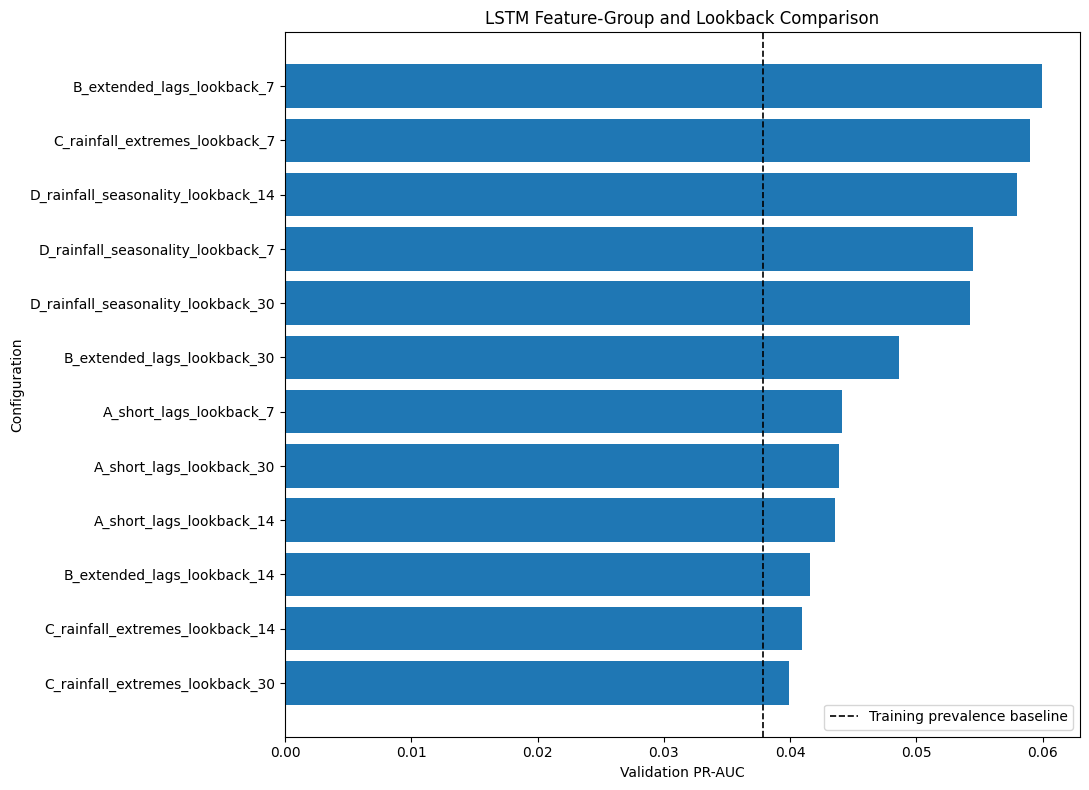

In [ ]:
# ============================================================
# 8. Plot validation PR-AUC for all configurations
# ============================================================

plot_results = experiment_results.sort_values(
    by="Validation_PR_AUC",
    ascending=True
)

plt.figure(figsize=(11, 8))

plt.barh(
    plot_results["Experiment"],
    plot_results["Validation_PR_AUC"]
)

plt.axvline(
    x=full_lstm_data.loc[
        full_lstm_data["dataset_split"] == "train",
        target
    ].mean(),
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Training prevalence baseline"
)

plt.xlabel("Validation PR-AUC")
plt.ylabel("Configuration")
plt.title(
    "LSTM Feature-Group and Lookback Comparison"
)

plt.legend(
    loc="lower right"
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 9. Select the best validation configuration
# ============================================================

best_experiment_name = experiment_results.loc[
    0,
    "Experiment"
]

best_result = experiment_objects[
    best_experiment_name
]

best_features = best_result["features"]
best_lookback = best_result["lookback"]
best_epoch = best_result["best_epoch"]

print("Best validation configuration")
print("-----------------------------")
print("Experiment:", best_experiment_name)
print("Lookback:", best_lookback)
print("Number of features:", len(best_features))
print("Features:")
print(best_features)

print(
    "\nValidation PR-AUC:",
    round(
        best_result["validation_PR_AUC"],
        4
    )
)

print(
    "Validation ROC-AUC:",
    round(
        best_result["validation_ROC_AUC"],
        4
    )
)

print(
    "Validation Brier:",
    round(
        best_result["validation_Brier"],
        4
    )
)

print("Best epoch:", best_epoch)

Best validation configuration
-----------------------------
Experiment: B_extended_lags_lookback_7
Lookback: 7
Number of features: 14
Features:
['lag1', 'lag2', 'lag3', 'lag4', 'lag5', 'lag6', 'lag7', 'lag8', 'lag9', 'lag10', 'lag11', 'lag12', 'lag13', 'lag14']

Validation PR-AUC: 0.06
Validation ROC-AUC: 0.6174
Validation Brier: 0.2527
Best epoch: 2


In [ ]:
# ============================================================
# 10. Recreate sequences using the best configuration
# ============================================================

(
    X_best_all,
    y_best_all,
    dates_best_all,
    splits_best_all
) = create_lstm_sequences(
    data=full_lstm_data,
    feature_names=best_features,
    target_name=target,
    lookback=best_lookback
)

best_train_mask = (
    splits_best_all == "train"
)

best_test_mask = (
    splits_best_all == "test"
)

X_best_train = X_best_all[
    best_train_mask
]

y_best_train = y_best_all[
    best_train_mask
]

dates_best_train = dates_best_all[
    best_train_mask
]

X_best_test = X_best_all[
    best_test_mask
]

y_best_test = y_best_all[
    best_test_mask
]

dates_best_test = dates_best_all[
    best_test_mask
]

print("Final training sequences:", len(X_best_train))
print("Final test sequences:", len(X_best_test))

print(
    "Final training positives:",
    int(y_best_train.sum())
)

print(
    "Final test positives:",
    int(y_best_test.sum())
)

Final training sequences: 8745
Final test sequences: 2191
Final training positives: 332
Final test positives: 85


In [ ]:
# ============================================================
# 11. Fit scaler on all final training sequences
# ============================================================

n_best_features = len(best_features)

final_lstm_scaler = StandardScaler()

final_lstm_scaler.fit(
    X_best_train.reshape(
        -1,
        n_best_features
    )
)

X_best_train_scaled = (
    final_lstm_scaler
    .transform(
        X_best_train.reshape(
            -1,
            n_best_features
        )
    )
    .reshape(
        X_best_train.shape
    )
    .astype(np.float32)
)

X_best_test_scaled = (
    final_lstm_scaler
    .transform(
        X_best_test.reshape(
            -1,
            n_best_features
        )
    )
    .reshape(
        X_best_test.shape
    )
    .astype(np.float32)
)

In [ ]:
# ============================================================
# 12. Calculate final training class weights
# ============================================================

final_class_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_best_train
)

final_class_weight = {
    0: float(final_class_weight_values[0]),
    1: float(final_class_weight_values[1])
}

print("Final class weights:")
print(final_class_weight)

Final class weights:
{0: 0.5197313681207655, 1: 13.170180722891565}


In [ ]:
# ============================================================
# 13. Fit final LSTM on the complete training period
# ============================================================

final_lstm_model = build_lstm_classifier(
    lookback=best_lookback,
    n_features=n_best_features
)

final_history = final_lstm_model.fit(
    X_best_train_scaled,
    y_best_train,
    epochs=max(1, best_epoch),
    batch_size=32,
    class_weight=final_class_weight,
    shuffle=False,
    verbose=1
)

print("\nFinal LSTM fitted.")

Epoch 1/2
274/274 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - brier: 0.2596 - loss: 0.7289 - pr_auc: 0.0417 - roc_auc: 0.5248
Epoch 2/2
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - brier: 0.2553 - loss: 0.7125 - pr_auc: 0.0521 - roc_auc: 0.5576

Final LSTM fitted.


In [ ]:
# ============================================================
# 14. Predict training and test probabilities
# ============================================================

p_lstm_train = final_lstm_model.predict(
    X_best_train_scaled,
    verbose=0
).ravel()

p_lstm_test = final_lstm_model.predict(
    X_best_test_scaled,
    verbose=0
).ravel()

In [ ]:
# ============================================================
# 15. Evaluation function
# ============================================================

def calculate_classifier_metrics(
    y_true,
    y_probability,
    dataset_name
):
    metrics = {
        "Dataset": dataset_name,
        "ROC-AUC": roc_auc_score(
            y_true,
            y_probability
        ),
        "PR-AUC": average_precision_score(
            y_true,
            y_probability
        ),
        "Brier": brier_score_loss(
            y_true,
            y_probability
        ),
        "Prevalence": float(
            np.mean(y_true)
        )
    }

    return metrics


lstm_train_metrics = calculate_classifier_metrics(
    y_best_train,
    p_lstm_train,
    "Training set"
)

lstm_test_metrics = calculate_classifier_metrics(
    y_best_test,
    p_lstm_test,
    "Test set"
)

lstm_metrics_summary = pd.DataFrame([
    lstm_train_metrics,
    lstm_test_metrics
])

print("\nFinal LSTM performance")
print("----------------------")

print(
    lstm_metrics_summary.round(4)
)


Final LSTM performance
----------------------
        Dataset  ROC-AUC  PR-AUC   Brier  Prevalence
0  Training set   0.6064  0.0614  0.2511      0.0380
1      Test set   0.5310  0.0518  0.2516      0.0388


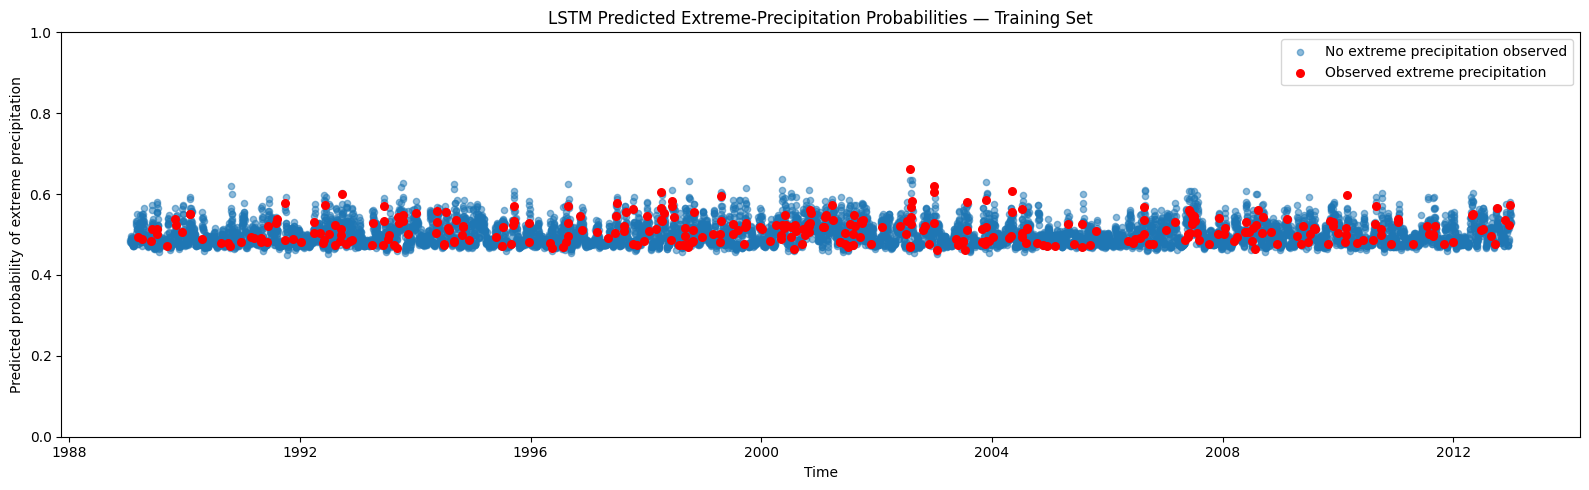

In [ ]:
# ============================================================
# 16. Plot training-set probabilities
# ============================================================

train_plot_lstm = pd.DataFrame(
    {
        "extreme": y_best_train,
        "p_lstm": p_lstm_train
    },
    index=dates_best_train
).sort_index()

train_non_extreme_mask = (
    train_plot_lstm["extreme"] == 0
)

train_extreme_mask = (
    train_plot_lstm["extreme"] == 1
)

plt.figure(figsize=(16, 5))

plt.scatter(
    train_plot_lstm.index[
        train_non_extreme_mask
    ],
    train_plot_lstm.loc[
        train_non_extreme_mask,
        "p_lstm"
    ],
    s=20,
    alpha=0.5,
    label="No extreme precipitation observed",
    zorder=2
)

plt.scatter(
    train_plot_lstm.index[
        train_extreme_mask
    ],
    train_plot_lstm.loc[
        train_extreme_mask,
        "p_lstm"
    ],
    color="red",
    s=30,
    alpha=1.0,
    label="Observed extreme precipitation",
    zorder=3
)

plt.xlabel("Time")
plt.ylabel(
    "Predicted probability of extreme precipitation"
)

plt.title(
    "LSTM Predicted Extreme-Precipitation "
    "Probabilities — Training Set"
)

plt.ylim(0, 1)

plt.legend(
    loc="upper right"
)

plt.tight_layout()
plt.show()

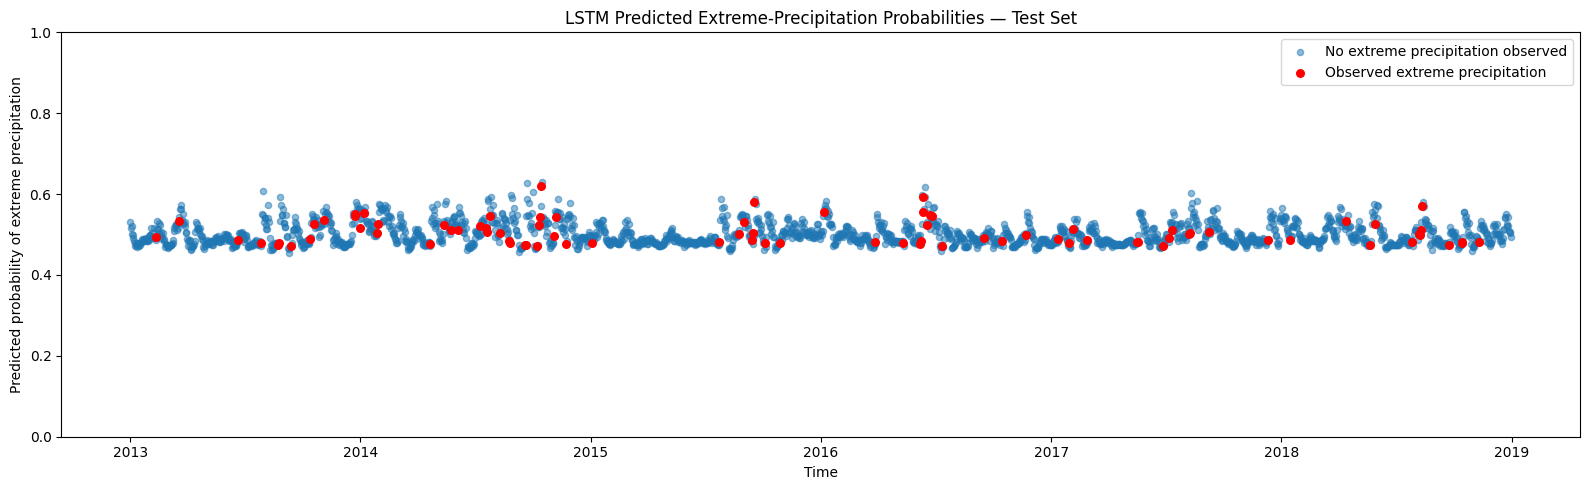

In [ ]:
# ============================================================
# 17. Plot test-set probabilities
# ============================================================

test_plot_lstm = pd.DataFrame(
    {
        "extreme": y_best_test,
        "p_lstm": p_lstm_test
    },
    index=dates_best_test
).sort_index()

test_non_extreme_mask = (
    test_plot_lstm["extreme"] == 0
)

test_extreme_mask = (
    test_plot_lstm["extreme"] == 1
)

plt.figure(figsize=(16, 5))

plt.scatter(
    test_plot_lstm.index[
        test_non_extreme_mask
    ],
    test_plot_lstm.loc[
        test_non_extreme_mask,
        "p_lstm"
    ],
    s=20,
    alpha=0.5,
    label="No extreme precipitation observed",
    zorder=2
)

plt.scatter(
    test_plot_lstm.index[
        test_extreme_mask
    ],
    test_plot_lstm.loc[
        test_extreme_mask,
        "p_lstm"
    ],
    color="red",
    s=30,
    alpha=1.0,
    label="Observed extreme precipitation",
    zorder=3
)

plt.xlabel("Time")
plt.ylabel(
    "Predicted probability of extreme precipitation"
)

plt.title(
    "LSTM Predicted Extreme-Precipitation "
    "Probabilities — Test Set"
)

plt.ylim(0, 1)

plt.legend(
    loc="upper right"
)

plt.tight_layout()
plt.show()

# LSTM Regressor

In [ ]:
# ============================================================
# 1. Reproducibility
# ============================================================

random_state = 42

os.environ["PYTHONHASHSEED"] = str(random_state)
random.seed(random_state)
np.random.seed(random_state)
tf.random.set_seed(random_state)

# ============================================================
# 2. Feature groups and settings
# ============================================================

feature_sets_reg = {
    "A_short_term": [
        "lag1", "lag2",
        "max_7d", "max_14d"
    ],

    "B_extended_lags": [
        "lag1", "lag2", "lag3", "lag7", "lag14",
        "max_7d", "max_14d"
    ],

    "C_extreme_history": [
        "lag1", "lag2", "lag3", "lag7", "lag14",
        "max_7d", "max_14d",
        "extreme_count_7d",
        "extreme_count_30d",
        "days_since_extreme99"
    ],

    "D_seasonality": [
        "lag1", "lag2", "lag3", "lag7", "lag14",
        "max_7d", "max_14d",
        "extreme_count_7d",
        "extreme_count_30d",
        "days_since_extreme99",
        "sin_doy", "cos_doy"
    ]
}

lookback_values_reg = [7, 14, 30]

target_reg = "index_max"

validation_fraction = 0.20
max_epochs = 150
batch_size = 16

all_features_reg = list(dict.fromkeys(
    feature
    for features in feature_sets_reg.values()
    for feature in features
))

In [ ]:
# ============================================================
# 3. Check required variables
# ============================================================

for dataset_name, df in [
    ("train", train),
    ("test", test)
]:
    missing = [
        feature
        for feature in all_features_reg + [target_reg]
        if feature not in df.columns
    ]

    if missing:
        raise KeyError(
            f"Missing variables in {dataset_name}: {missing}"
        )

# ============================================================
# 4. Combine train and test chronologically
# ============================================================

def prepare_lstm_reg_source(df, split_name):

    columns = all_features_reg + [target_reg]

    result = df[columns].copy()

    if "date" in df.columns:
        result.index = pd.to_datetime(df["date"])
    else:
        result.index = pd.to_datetime(df.index)

    result["dataset_split"] = split_name

    return result.sort_index()


train_lstm_source = prepare_lstm_reg_source(
    train, "train"
)

test_lstm_source = prepare_lstm_reg_source(
    test, "test"
)

if train_lstm_source.index.max() >= test_lstm_source.index.min():
    raise ValueError(
        "Train/test periods overlap or are not chronological."
    )

full_lstm_data = pd.concat(
    [train_lstm_source, test_lstm_source],
    axis=0
).sort_index()

if full_lstm_data.index.has_duplicates:
    raise ValueError("Duplicate dates detected.")

print("Full period:")
print(
    full_lstm_data.index.min(),
    "to",
    full_lstm_data.index.max()
)

# ============================================================
# 5. Create extreme-event regression sequences
#
# Input: t-lookback, ..., t-1
# Target: log(1 + index_max_t)
# Keep only target days with index_max > 1
# ============================================================

def create_extreme_regression_sequences(
    data,
    feature_names,
    target_name,
    lookback_days
):

    X_sequences = []
    y_sequences_log = []
    y_sequences_original = []
    target_dates = []
    split_labels = []

    required_columns = (
        feature_names
        + [target_name, "dataset_split"]
    )

    sequence_data = data[required_columns].copy()

    for target_position in range(
        lookback_days,
        len(sequence_data)
    ):

        start_position = (
            target_position - lookback_days
        )

        X_window = sequence_data.iloc[
            start_position:target_position
        ][feature_names]

        target_row = sequence_data.iloc[target_position]

        true_index = target_row[target_name]

        if X_window.isna().any().any():
            continue

        if pd.isna(true_index):
            continue

        if true_index <= 1:
            continue

        X_sequences.append(
            X_window.to_numpy(dtype=np.float32)
        )

        y_sequences_log.append(
            np.log1p(true_index)
        )

        y_sequences_original.append(
            true_index
        )

        target_dates.append(
            sequence_data.index[target_position]
        )

        split_labels.append(
            target_row["dataset_split"]
        )

    return (
        np.asarray(X_sequences, dtype=np.float32),
        np.asarray(y_sequences_log, dtype=np.float32),
        np.asarray(y_sequences_original, dtype=np.float32),
        pd.DatetimeIndex(target_dates),
        np.asarray(split_labels)
    )


# ============================================================
# 6. Common training/validation target dates
#
# Use the most demanding configuration to identify
# dates with complete predictors.
# This keeps the validation observations identical.
# ============================================================

max_lookback_reg = max(lookback_values_reg)

(
    X_reference,
    y_reference_log,
    y_reference_original,
    dates_reference,
    splits_reference
) = create_extreme_regression_sequences(
    data=full_lstm_data,
    feature_names=all_features_reg,
    target_name=target_reg,
    lookback_days=max_lookback_reg
)

reference_train_dates = dates_reference[
    splits_reference == "train"
]

reference_test_dates = dates_reference[
    splits_reference == "test"
]

if len(reference_train_dates) < 20:
    raise ValueError(
        "Too few complete extreme training sequences."
    )

if len(reference_test_dates) == 0:
    raise ValueError(
        "No complete extreme test sequences."
    )

validation_size = max(
    5,
    int(np.ceil(
        validation_fraction * len(reference_train_dates)
    ))
)

if validation_size >= len(reference_train_dates):
    raise ValueError("Validation set is too large.")

common_fit_dates = reference_train_dates[
    :-validation_size
]

common_val_dates = reference_train_dates[
    -validation_size:
]

print("\nCommon sample counts:")
print("Fitting:", len(common_fit_dates))
print("Validation:", len(common_val_dates))
print("Test:", len(reference_test_dates))

# ============================================================
# 7. Build LSTM regression model
# ============================================================

def build_lstm_regressor(lookback, n_features):

    tf.keras.backend.clear_session()

    model = tf.keras.Sequential([

        tf.keras.layers.Input(
            shape=(lookback, n_features)
        ),

        tf.keras.layers.LSTM(
            units=16,
            activation="tanh",
            recurrent_activation="sigmoid",
            return_sequences=False,
            kernel_regularizer=tf.keras.regularizers.l2(1e-3),
            recurrent_regularizer=tf.keras.regularizers.l2(1e-3)
        ),

        tf.keras.layers.Dropout(0.30),

        tf.keras.layers.Dense(
            units=8,
            activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(1e-3)
        ),

        tf.keras.layers.Dropout(0.20),

        tf.keras.layers.Dense(
            units=1,
            activation="linear"
        )
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=1e-3
        ),
        loss="mse",
        metrics=["mae"]
    )

    return model


# ============================================================
# 8. Sequence standardisation
# ============================================================

def transform_lstm_sequences(X, scaler):

    original_shape = X.shape

    X_scaled = scaler.transform(
        X.reshape(-1, original_shape[2])
    )

    return X_scaled.reshape(
        original_shape
    ).astype(np.float32)


# ============================================================
# 9. Compare feature groups and lookback windows
# ============================================================

experiment_rows_reg = []

for group_name, features in feature_sets_reg.items():

    for lookback in lookback_values_reg:

        print(
            f"\nRunning {group_name}, lookback={lookback}"
        )

        (
            X_all,
            y_all_log,
            y_all_original,
            dates_all,
            splits_all
        ) = create_extreme_regression_sequences(
            data=full_lstm_data,
            feature_names=features,
            target_name=target_reg,
            lookback_days=lookback
        )

        fit_mask = dates_all.isin(common_fit_dates)
        val_mask = dates_all.isin(common_val_dates)

        X_fit = X_all[fit_mask]
        y_fit_log = y_all_log[fit_mask]

        X_val = X_all[val_mask]
        y_val_log = y_all_log[val_mask]
        y_val_original = y_all_original[val_mask]

        if (
            len(X_fit) != len(common_fit_dates)
            or len(X_val) != len(common_val_dates)
        ):
            raise ValueError(
                "Common sample alignment failed."
            )

        n_features = len(features)

        scaler = StandardScaler()

        scaler.fit(
            X_fit.reshape(-1, n_features)
        )

        X_fit_scaled = transform_lstm_sequences(
            X_fit, scaler
        )

        X_val_scaled = transform_lstm_sequences(
            X_val, scaler
        )

        random.seed(random_state)
        np.random.seed(random_state)
        tf.random.set_seed(random_state)

        model = build_lstm_regressor(
            lookback,
            n_features
        )

        callbacks = [
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                mode="min",
                patience=15,
                min_delta=1e-4,
                restore_best_weights=True,
                verbose=0
            ),

            tf.keras.callbacks.ReduceLROnPlateau(
                monitor="val_loss",
                mode="min",
                factor=0.5,
                patience=6,
                min_lr=1e-5,
                verbose=0
            )
        ]

        history = model.fit(
            X_fit_scaled,
            y_fit_log,
            validation_data=(
                X_val_scaled,
                y_val_log
            ),
            epochs=max_epochs,
            batch_size=batch_size,
            shuffle=False,
            callbacks=callbacks,
            verbose=0
        )

        pred_val_log = model.predict(
            X_val_scaled,
            verbose=0
        ).ravel()

        pred_val = np.maximum(
            np.expm1(pred_val_log),
            0
        )

        val_rmse = np.sqrt(
            mean_squared_error(
                y_val_original,
                pred_val
            )
        )

        val_mae = mean_absolute_error(
            y_val_original,
            pred_val
        )

        best_epoch = int(
            np.argmin(history.history["val_loss"]) + 1
        )

        experiment_rows_reg.append({
            "Feature_set": group_name,
            "Lookback": lookback,
            "Number_of_features": n_features,
            "Best_epoch": best_epoch,
            "Validation_RMSE": val_rmse,
            "Validation_MAE": val_mae
        })

        print(
            f"RMSE={val_rmse:.4f}, "
            f"MAE={val_mae:.4f}, "
            f"Best epoch={best_epoch}"
        )


experiment_results_reg = pd.DataFrame(
    experiment_rows_reg
).sort_values(
    ["Validation_RMSE", "Validation_MAE"],
    ascending=[True, True]
).reset_index(drop=True)

print("\nConfiguration ranking:")
print(experiment_results_reg.round(4))

Full period:
1989-01-01 00:00:00 to 2018-12-31 00:00:00

Common sample counts:
Fitting: 264
Validation: 66
Test: 85

Running A_short_term, lookback=7
RMSE=0.4229, MAE=0.3250, Best epoch=149

Running A_short_term, lookback=14


RMSE=0.3982, MAE=0.3087, Best epoch=143

Running A_short_term, lookback=30


RMSE=0.3924, MAE=0.3027, Best epoch=143

Running B_extended_lags, lookback=7
RMSE=0.4180, MAE=0.3269, Best epoch=149

Running B_extended_lags, lookback=14
RMSE=0.4007, MAE=0.3135, Best epoch=143

Running B_extended_lags, lookback=30
RMSE=0.3947, MAE=0.3099, Best epoch=143

Running C_extreme_history, lookback=7
RMSE=0.4300, MAE=0.3261, Best epoch=148

Running C_extreme_history, lookback=14
RMSE=0.4326, MAE=0.3291, Best epoch=148

Running C_extreme_history, lookback=30
RMSE=0.4297, MAE=0.3228, Best epoch=142

Running D_seasonality, lookback=7
RMSE=0.4004, MAE=0.3098, Best epoch=149

Running D_seasonality, lookback=14
RMSE=0.4038, MAE=0.3069, Best epoch=149

Running D_seasonality, lookback=30
RMSE=0.4031, MAE=0.3044, Best epoch=149

Configuration ranking:
          Feature_set  Lookback  Number_of_features  Best_epoch  \
0        A_short_term        30                   4         143   
1     B_extended_lags        30                   7         143   
2        A_short_term        14     

In [ ]:
# ============================================================
# 10. Select best configuration
# ============================================================

best_row_reg = experiment_results_reg.iloc[0]

best_group_reg = best_row_reg["Feature_set"]
best_features_reg = feature_sets_reg[best_group_reg]

best_lookback_reg = int(
    best_row_reg["Lookback"]
)

best_epoch_reg = int(
    best_row_reg["Best_epoch"]
)

print("\nBest configuration:")
print("Feature group:", best_group_reg)
print("Features:", best_features_reg)
print("Lookback:", best_lookback_reg)
print("Epochs:", best_epoch_reg)

# ============================================================
# 11. Recreate final sequences
# ============================================================

(
    X_final_all,
    y_final_all_log,
    y_final_all_original,
    dates_final_all,
    splits_final_all
) = create_extreme_regression_sequences(
    data=full_lstm_data,
    feature_names=best_features_reg,
    target_name=target_reg,
    lookback_days=best_lookback_reg
)

train_mask = splits_final_all == "train"
test_mask = splits_final_all == "test"

X_final_train = X_final_all[train_mask]
y_final_train_log = y_final_all_log[train_mask]
y_final_train_original = y_final_all_original[train_mask]
dates_final_train = dates_final_all[train_mask]

X_final_test = X_final_all[test_mask]
y_final_test_original = y_final_all_original[test_mask]
dates_final_test = dates_final_all[test_mask]

print("\nFinal model sample counts:")
print("Training extreme days:", len(X_final_train))
print("Test extreme days:", len(X_final_test))

# ============================================================
# 12. Fit final scaler using training data only
# ============================================================

n_final_features = len(best_features_reg)

final_scaler_reg = StandardScaler()

final_scaler_reg.fit(
    X_final_train.reshape(-1, n_final_features)
)

X_final_train_scaled = transform_lstm_sequences(
    X_final_train,
    final_scaler_reg
)

X_final_test_scaled = transform_lstm_sequences(
    X_final_test,
    final_scaler_reg
)

# ============================================================
# 13. Train final LSTM on all training extreme days
# ============================================================

random.seed(random_state)
np.random.seed(random_state)
tf.random.set_seed(random_state)

final_lstm_reg = build_lstm_regressor(
    lookback=best_lookback_reg,
    n_features=n_final_features
)

final_lstm_reg.summary()

final_history_reg = final_lstm_reg.fit(
    X_final_train_scaled,
    y_final_train_log,
    epochs=max(1, best_epoch_reg),
    batch_size=batch_size,
    shuffle=False,
    verbose=1
)


Best configuration:
Feature group: A_short_term
Features: ['lag1', 'lag2', 'max_7d', 'max_14d']
Lookback: 30
Epochs: 143

Final model sample counts:
Training extreme days: 332
Test extreme days: 85


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 16)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,489 (5.82 KB)

 Trainable params: 1,489 (5.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/143
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 0.4899 - mae: 0.6063
Epoch 2/143
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.2733 - mae: 0.4197
Epoch 3/143
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.2153 - mae: 0.3432
Epoch 4/143
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1972 - mae: 0.3330
Epoch 5/143
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1644 - mae: 0.2848
Epoch 6/143
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1527 - mae: 0.2805
Epoch 7/143
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1550 - mae: 0.2806
Epoch 8/143
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1619 - mae: 0.2848
Epoch 9/143
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1451 - mae: 0.2724
Epoch 10/143
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1362 - mae: 0.2579
Epoch 11/143
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1231 - mae: 0.2422
Epoch 12/143
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1184 - mae: 0.2381
Epoch 13/143
21/21 ━━━━━━


Training prediction preview:
            index_max  pred_index_lstm
1989-03-14   1.030615         1.490078
1989-04-05   1.200873         1.644794
1989-06-01   1.381122         1.411375
1989-06-06   1.440385         1.471770
1989-07-07   1.814447         1.503413


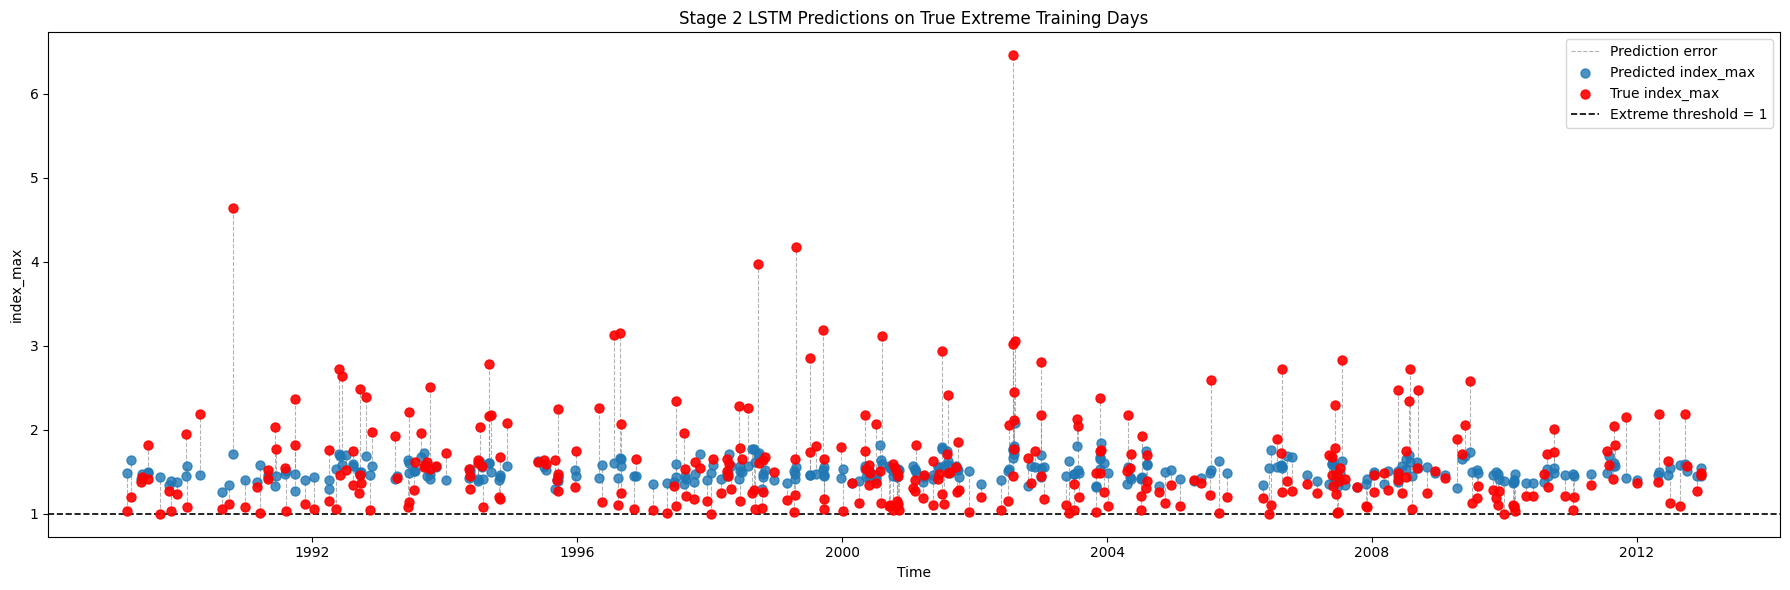


LSTM Stage 2 TRAINING performance
Only true extreme training days
----------------------------------
RMSE : 0.5738
MAE  : 0.3727
R²   : 0.0888

Test prediction preview:
            index_max  pred_index_lstm
2013-02-10   1.016741         1.307724
2013-03-19   1.296650         1.440381
2013-06-21   1.004561         1.555659
2013-07-27   4.189137         1.600666
2013-08-24   2.465628         1.579826


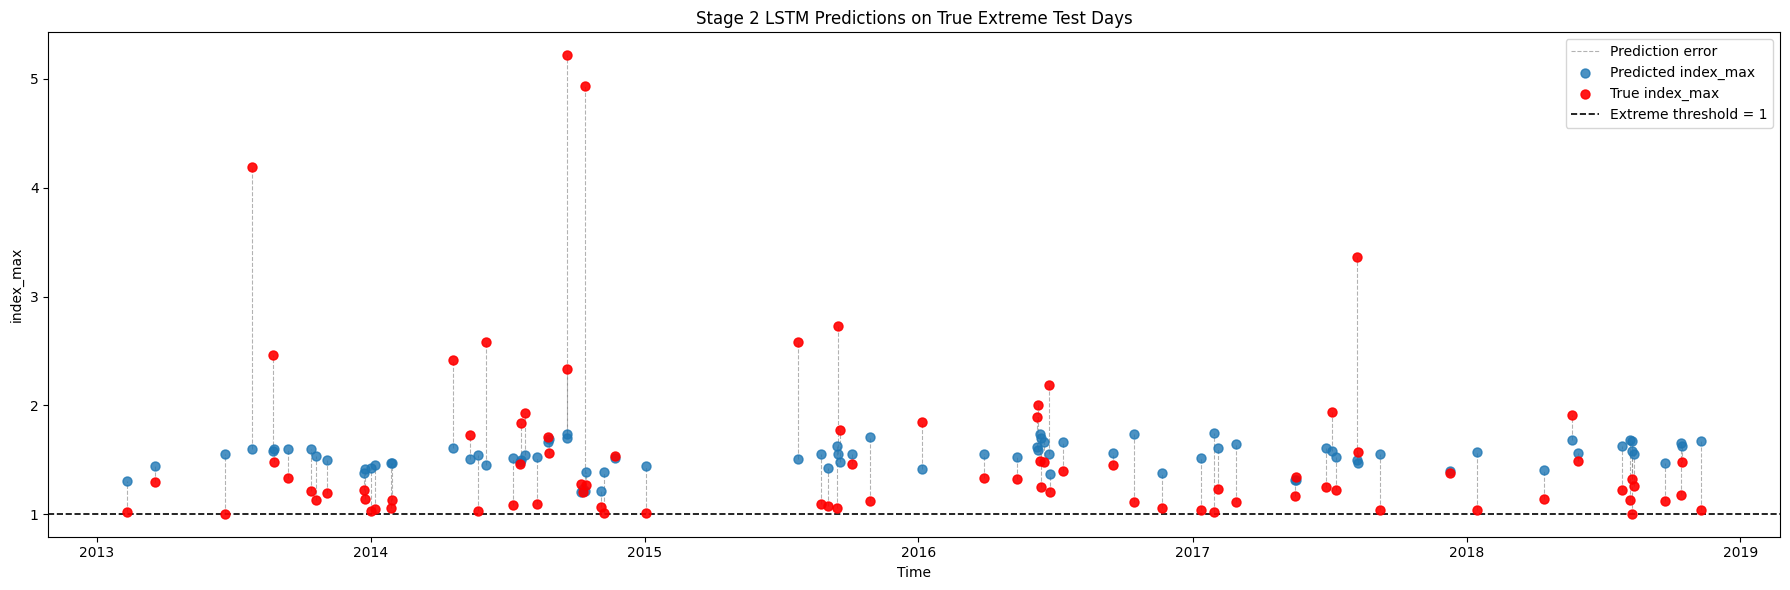


LSTM Stage 2 TEST performance
Only true extreme test days
----------------------------------
RMSE : 0.7793
MAE  : 0.4853
R²   : -0.0061


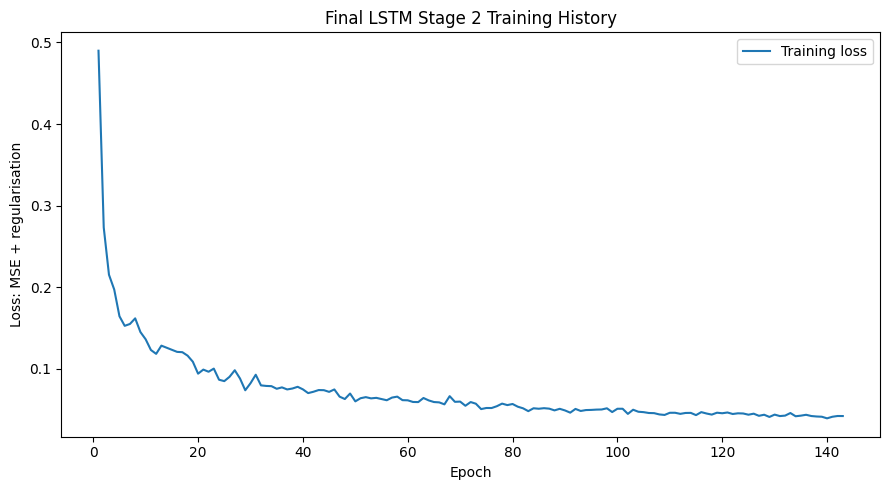


Final LSTM Stage 2 performance summary:
  Dataset    RMSE     MAE      R2
0   Train  0.5738  0.3727  0.0888
1    Test  0.7793  0.4853 -0.0061


In [ ]:

# ============================================================
# 14. Predict TRAINING extreme days
# ============================================================

pred_train_log = final_lstm_reg.predict(
    X_final_train_scaled,
    verbose=0
).ravel()

pred_train_original = np.maximum(
    np.expm1(pred_train_log),
    0
)

train_lstm_reg_results = pd.DataFrame({
    "index_max": y_final_train_original,
    "pred_index_lstm": pred_train_original
}, index=dates_final_train).sort_index()

print("\nTraining prediction preview:")
print(train_lstm_reg_results.head())

# ============================================================
# 15. Plot TRAINING predictions
# ============================================================

plt.figure(figsize=(18, 6))

plt.vlines(
    x=train_lstm_reg_results.index,
    ymin=np.minimum(
        train_lstm_reg_results["index_max"],
        train_lstm_reg_results["pred_index_lstm"]
    ),
    ymax=np.maximum(
        train_lstm_reg_results["index_max"],
        train_lstm_reg_results["pred_index_lstm"]
    ),
    colors="grey",
    linestyles="--",
    linewidth=0.8,
    alpha=0.6,
    label="Prediction error",
    zorder=1
)

plt.scatter(
    train_lstm_reg_results.index,
    train_lstm_reg_results["pred_index_lstm"],
    s=42,
    alpha=0.8,
    label="Predicted index_max",
    zorder=2
)

plt.scatter(
    train_lstm_reg_results.index,
    train_lstm_reg_results["index_max"],
    color="red",
    s=42,
    alpha=0.9,
    label="True index_max",
    zorder=3
)

plt.axhline(
    y=1,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Extreme threshold = 1"
)

plt.xlabel("Time")
plt.ylabel("index_max")
plt.title(
    "Stage 2 LSTM Predictions "
    "on True Extreme Training Days"
)

plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

# ============================================================
# 16. TRAINING metrics
# ============================================================

rmse_lstm_reg_train = np.sqrt(
    mean_squared_error(
        train_lstm_reg_results["index_max"],
        train_lstm_reg_results["pred_index_lstm"]
    )
)

mae_lstm_reg_train = mean_absolute_error(
    train_lstm_reg_results["index_max"],
    train_lstm_reg_results["pred_index_lstm"]
)

r2_lstm_reg_train = r2_score(
    train_lstm_reg_results["index_max"],
    train_lstm_reg_results["pred_index_lstm"]
)

print("\nLSTM Stage 2 TRAINING performance")
print("Only true extreme training days")
print("----------------------------------")
print(f"RMSE : {rmse_lstm_reg_train:.4f}")
print(f"MAE  : {mae_lstm_reg_train:.4f}")
print(f"R²   : {r2_lstm_reg_train:.4f}")

# ============================================================
# 17. Predict TEST extreme days
# ============================================================

pred_test_log = final_lstm_reg.predict(
    X_final_test_scaled,
    verbose=0
).ravel()

pred_test_original = np.maximum(
    np.expm1(pred_test_log),
    0
)

test_lstm_reg_results = pd.DataFrame({
    "index_max": y_final_test_original,
    "pred_index_lstm": pred_test_original
}, index=dates_final_test).sort_index()

print("\nTest prediction preview:")
print(test_lstm_reg_results.head())

# ============================================================
# 18. Plot TEST predictions
# ============================================================

plt.figure(figsize=(18, 6))

plt.vlines(
    x=test_lstm_reg_results.index,
    ymin=np.minimum(
        test_lstm_reg_results["index_max"],
        test_lstm_reg_results["pred_index_lstm"]
    ),
    ymax=np.maximum(
        test_lstm_reg_results["index_max"],
        test_lstm_reg_results["pred_index_lstm"]
    ),
    colors="grey",
    linestyles="--",
    linewidth=0.8,
    alpha=0.6,
    label="Prediction error",
    zorder=1
)

plt.scatter(
    test_lstm_reg_results.index,
    test_lstm_reg_results["pred_index_lstm"],
    s=42,
    alpha=0.8,
    label="Predicted index_max",
    zorder=2
)

plt.scatter(
    test_lstm_reg_results.index,
    test_lstm_reg_results["index_max"],
    color="red",
    s=42,
    alpha=0.9,
    label="True index_max",
    zorder=3
)

plt.axhline(
    y=1,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Extreme threshold = 1"
)

plt.xlabel("Time")
plt.ylabel("index_max")
plt.title(
    "Stage 2 LSTM Predictions "
    "on True Extreme Test Days"
)

plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

# ============================================================
# 19. TEST metrics
# ============================================================

rmse_lstm_reg_extreme = np.sqrt(
    mean_squared_error(
        test_lstm_reg_results["index_max"],
        test_lstm_reg_results["pred_index_lstm"]
    )
)

mae_lstm_reg_extreme = mean_absolute_error(
    test_lstm_reg_results["index_max"],
    test_lstm_reg_results["pred_index_lstm"]
)

r2_lstm_reg_extreme = r2_score(
    test_lstm_reg_results["index_max"],
    test_lstm_reg_results["pred_index_lstm"]
)

print("\nLSTM Stage 2 TEST performance")
print("Only true extreme test days")
print("----------------------------------")
print(f"RMSE : {rmse_lstm_reg_extreme:.4f}")
print(f"MAE  : {mae_lstm_reg_extreme:.4f}")
print(f"R²   : {r2_lstm_reg_extreme:.4f}")

# ============================================================
# 20. Training loss of final model
# ============================================================

final_history_reg_df = pd.DataFrame(
    final_history_reg.history
)

plt.figure(figsize=(9, 5))

plt.plot(
    final_history_reg_df.index + 1,
    final_history_reg_df["loss"],
    label="Training loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss: MSE + regularisation")
plt.title("Final LSTM Stage 2 Training History")

plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 21. Summary
# ============================================================

performance_summary_reg = pd.DataFrame({
    "Dataset": ["Train", "Test"],
    "RMSE": [
        rmse_lstm_reg_train,
        rmse_lstm_reg_extreme
    ],
    "MAE": [
        mae_lstm_reg_train,
        mae_lstm_reg_extreme
    ],
    "R2": [
        r2_lstm_reg_train,
        r2_lstm_reg_extreme
    ]
})

print("\nFinal LSTM Stage 2 performance summary:")
print(performance_summary_reg.round(4))

# ROC and Precision-Recall curves


Training Set
----------------------------------------
Observations: 8693
Extreme events: 331
Prevalence: 3.8077%

Test Set
----------------------------------------
Observations: 2191
Extreme events: 85
Prevalence: 3.8795%


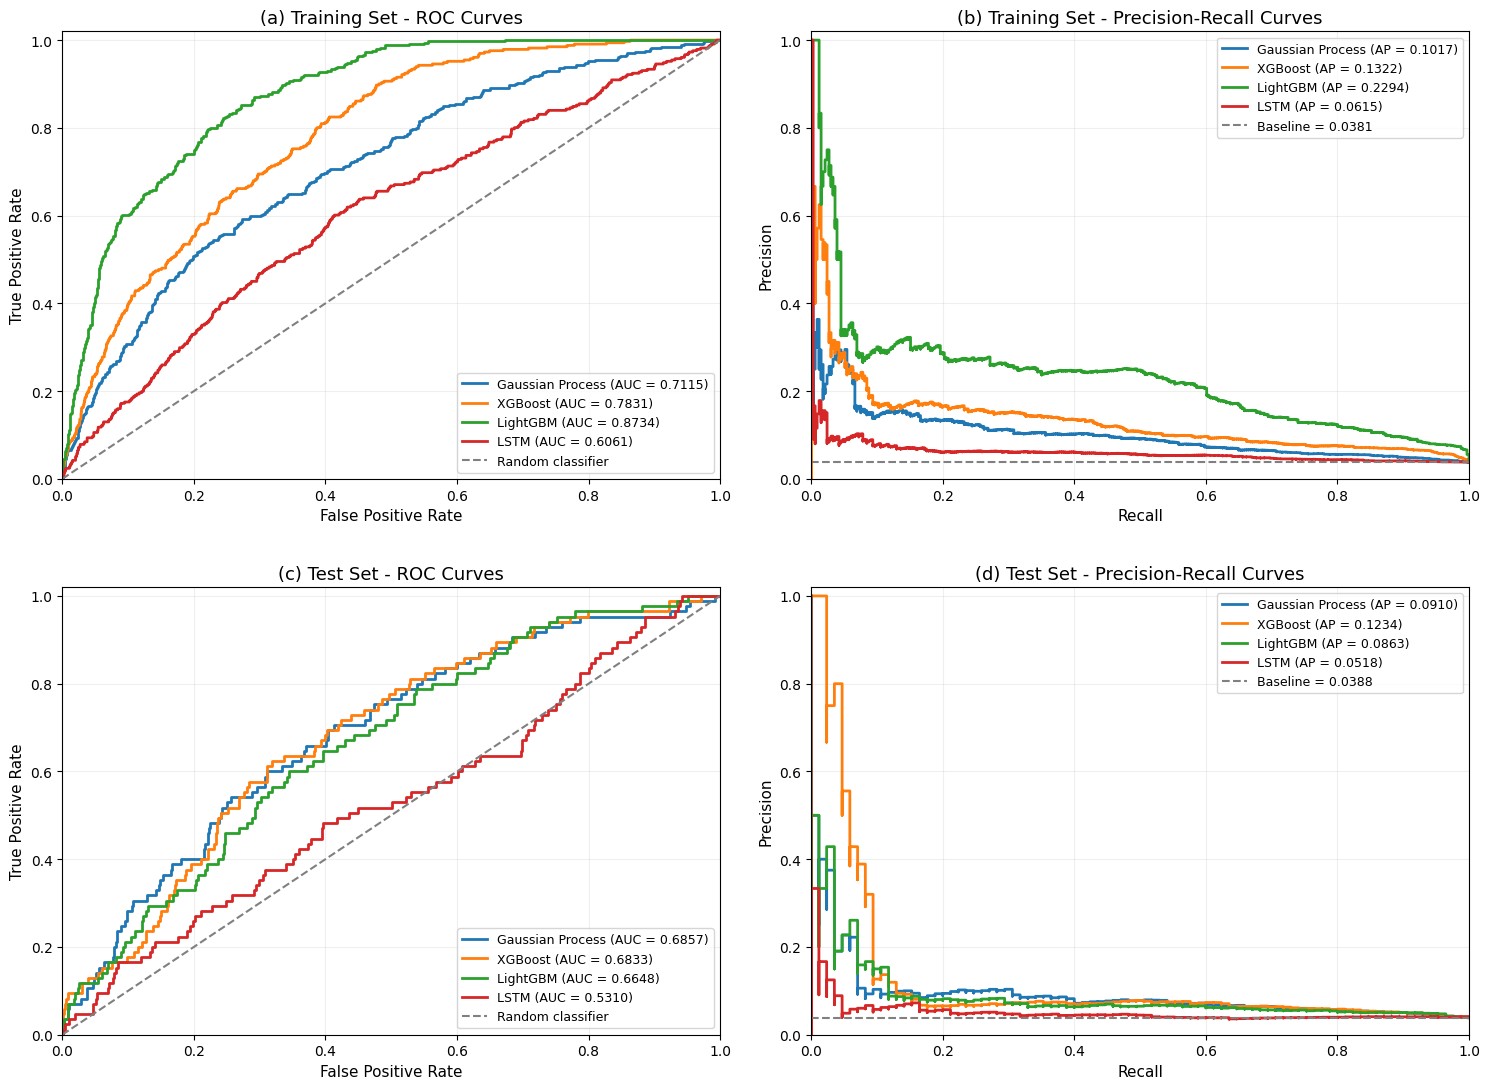


Occurrence Model Performance
------------------------------------------------------------
           Model  Dataset  ROC-AUC  PR-AUC (AP)  Brier Score
Gaussian Process Training   0.7115       0.1017       0.1197
         XGBoost Training   0.7831       0.1322       0.1982
        LightGBM Training   0.8734       0.2294       0.1666
            LSTM Training   0.6061       0.0615       0.2512
Gaussian Process     Test   0.6857       0.0910       0.1192
         XGBoost     Test   0.6833       0.1234       0.1773
        LightGBM     Test   0.6648       0.0863       0.1538
            LSTM     Test   0.5310       0.0518       0.2516


In [ ]:
# ============================================================
# 2. Gaussian Process - Training and Test
# ============================================================

# Training set
train_gpc_plot = train[
    selected_features_gpc + ["extreme"]
].dropna().copy()

X_train_gpc_plot = train_gpc_plot[selected_features_gpc]

p_gpc_train = gpc.predict_proba(
    scaler_gpc.transform(X_train_gpc_plot)
)[:, 1]

# Test set
test_gpc_plot = test[
    selected_features_gpc + ["extreme"]
].dropna().copy()

X_test_gpc_plot = test_gpc_plot[selected_features_gpc]

p_gpc_test = gpc.predict_proba(
    scaler_gpc.transform(X_test_gpc_plot)
)[:, 1]


# ============================================================
# 3. XGBoost - Training and Test
# ============================================================

p_xgb_train = xgb_clf.predict_proba(
    X_train_xgb
)[:, 1]

p_xgb_test = xgb_clf.predict_proba(
    X_test_xgb
)[:, 1]


# ============================================================
# 4. LightGBM - Training and Test
# ============================================================

p_lgbm_train = lgbm_clf_final.predict_proba(
    X_train_lgbm_final
)[:, 1]

p_lgbm_test = lgbm_clf_final.predict_proba(
    X_test_lgbm_final
)[:, 1]


# ============================================================
# 5. LSTM - Training and Test
# ============================================================

p_lstm_train = final_lstm_model.predict(
    X_best_train_scaled,
    verbose=0
).ravel()

p_lstm_test = final_lstm_model.predict(
    X_best_test_scaled,
    verbose=0
).ravel()


# ============================================================
# 6. Helper function: create prediction series
# ============================================================

def create_prediction_series(dates, probabilities, name):

    dates = pd.to_datetime(dates)

    probabilities = np.asarray(probabilities).ravel()

    if len(dates) != len(probabilities):
        raise ValueError(
            f"{name}: dates and probabilities have different lengths."
        )

    series = pd.Series(
        probabilities,
        index=dates,
        name=name
    )

    if series.index.has_duplicates:
        raise ValueError(
            f"{name}: duplicate dates found."
        )

    return series


# ============================================================
# 7. Align predictions for each dataset
# ============================================================

def prepare_comparison_data(
    original_data,
    gp_dates, gp_prob,
    xgb_dates, xgb_prob,
    lgbm_dates, lgbm_prob,
    lstm_dates, lstm_prob
):

    gp_series = create_prediction_series(
        gp_dates, gp_prob, "Gaussian Process"
    )

    xgb_series = create_prediction_series(
        xgb_dates, xgb_prob, "XGBoost"
    )

    lgbm_series = create_prediction_series(
        lgbm_dates, lgbm_prob, "LightGBM"
    )

    lstm_series = create_prediction_series(
        lstm_dates, lstm_prob, "LSTM"
    )

    # Align all predictions by common dates
    predictions = pd.concat(
        [
            gp_series,
            xgb_series,
            lgbm_series,
            lstm_series
        ],
        axis=1,
        join="inner"
    ).dropna()

    # Actual extreme labels
    actual = original_data["extreme"].copy()
    actual.index = pd.to_datetime(actual.index)
    actual.name = "Actual"

    if actual.index.has_duplicates:
        raise ValueError(
            "Duplicate dates found in actual labels."
        )

    results = predictions.join(
        actual,
        how="inner"
    ).dropna().sort_index()

    if len(results) == 0:
        raise ValueError(
            "No common dates found across the four models."
        )

    if results["Actual"].nunique() != 2:
        raise ValueError(
            "Both extreme and non-extreme events are required."
        )

    return results


# ============================================================
# 8. Prepare training-set comparison
# ============================================================

train_results = prepare_comparison_data(
    original_data=train,

    gp_dates=train_gpc_plot.index,
    gp_prob=p_gpc_train,

    xgb_dates=X_train_xgb.index,
    xgb_prob=p_xgb_train,

    lgbm_dates=X_train_lgbm_final.index,
    lgbm_prob=p_lgbm_train,

    lstm_dates=dates_best_train,
    lstm_prob=p_lstm_train
)


# ============================================================
# 9. Prepare test-set comparison
# ============================================================

test_results = prepare_comparison_data(
    original_data=test,

    gp_dates=test_gpc_plot.index,
    gp_prob=p_gpc_test,

    xgb_dates=X_test_xgb.index,
    xgb_prob=p_xgb_test,

    lgbm_dates=X_test_lgbm_final.index,
    lgbm_prob=p_lgbm_test,

    lstm_dates=dates_best_test,
    lstm_prob=p_lstm_test
)


# ============================================================
# 10. Print sample information
# ============================================================

for name, data in [
    ("Training", train_results),
    ("Test", test_results)
]:

    print(f"\n{name} Set")
    print("-" * 40)
    print("Observations:", len(data))
    print("Extreme events:", int(data["Actual"].sum()))
    print(
        "Prevalence:",
        f"{data['Actual'].mean():.4%}"
    )


# ============================================================
# 11. Plot settings
# ============================================================

model_names = [
    "Gaussian Process",
    "XGBoost",
    "LightGBM",
    "LSTM"
]

colors = {
    "Gaussian Process": "tab:blue",
    "XGBoost": "tab:orange",
    "LightGBM": "tab:green",
    "LSTM": "tab:red"
}


# ============================================================
# 12. Function to plot ROC curves
# ============================================================

def plot_roc_curves(ax, data, title):

    y_true = data["Actual"].astype(int).values

    for model in model_names:

        y_prob = data[model].values

        fpr, tpr, _ = roc_curve(
            y_true,
            y_prob
        )

        auc_value = roc_auc_score(
            y_true,
            y_prob
        )

        ax.plot(
            fpr,
            tpr,
            color=colors[model],
            linewidth=2,
            label=f"{model} (AUC = {auc_value:.4f})"
        )

    # Random classifier
    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray",
        linewidth=1.5,
        label="Random classifier"
    )

    ax.set_title(title, fontsize=13)
    ax.set_xlabel("False Positive Rate", fontsize=11)
    ax.set_ylabel("True Positive Rate", fontsize=11)

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)

    ax.legend(
        loc="lower right",
        fontsize=9
    )

    ax.grid(alpha=0.2)


# ============================================================
# 13. Function to plot Precision-Recall curves
# ============================================================

def plot_pr_curves(ax, data, title):

    y_true = data["Actual"].astype(int).values

    for model in model_names:

        y_prob = data[model].values

        precision, recall, _ = precision_recall_curve(
            y_true,
            y_prob
        )

        ap_value = average_precision_score(
            y_true,
            y_prob
        )

        ax.step(
            recall,
            precision,
            where="post",
            color=colors[model],
            linewidth=2,
            label=f"{model} (AP = {ap_value:.4f})"
        )

    # Prevalence baseline
    prevalence = np.mean(y_true)

    ax.axhline(
        prevalence,
        linestyle="--",
        color="gray",
        linewidth=1.5,
        label=f"Baseline = {prevalence:.4f}"
    )

    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Recall", fontsize=11)
    ax.set_ylabel("Precision", fontsize=11)

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)

    ax.legend(
        loc="upper right",
        fontsize=9
    )

    ax.grid(alpha=0.2)


# ============================================================
# 14. Create 2x2 figure
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 11)
)

# Top row: Training Set
plot_roc_curves(
    axes[0, 0],
    train_results,
    "(a) Training Set - ROC Curves"
)

plot_pr_curves(
    axes[0, 1],
    train_results,
    "(b) Training Set - Precision-Recall Curves"
)

# Bottom row: Test Set
plot_roc_curves(
    axes[1, 0],
    test_results,
    "(c) Test Set - ROC Curves"
)

plot_pr_curves(
    axes[1, 1],
    test_results,
    "(d) Test Set - Precision-Recall Curves"
)

plt.tight_layout(
    h_pad=3,
    w_pad=2
)

plt.savefig(
    "occurrence_roc_pr_train_test.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 15. Summary table for all models
# ============================================================

summary_rows = []

for dataset_name, data in [
    ("Training", train_results),
    ("Test", test_results)
]:

    y_true = data["Actual"].astype(int).values

    for model in model_names:

        y_prob = data[model].values

        summary_rows.append({
            "Model": model,
            "Dataset": dataset_name,
            "ROC-AUC": roc_auc_score(
                y_true, y_prob
            ),
            "PR-AUC (AP)": average_precision_score(
                y_true, y_prob
            ),
            "Brier Score": brier_score_loss(
                y_true, y_prob
            )
        })

summary_df = pd.DataFrame(summary_rows)

print("\nOccurrence Model Performance")
print("-" * 60)

print(
    summary_df.round(4).to_string(index=False)
)

# Full model


Training prediction summary
--------------------------------
Total observations: 8693
True extreme observations: 331

Test prediction summary
--------------------------------
Total observations: 2191
True extreme observations: 85


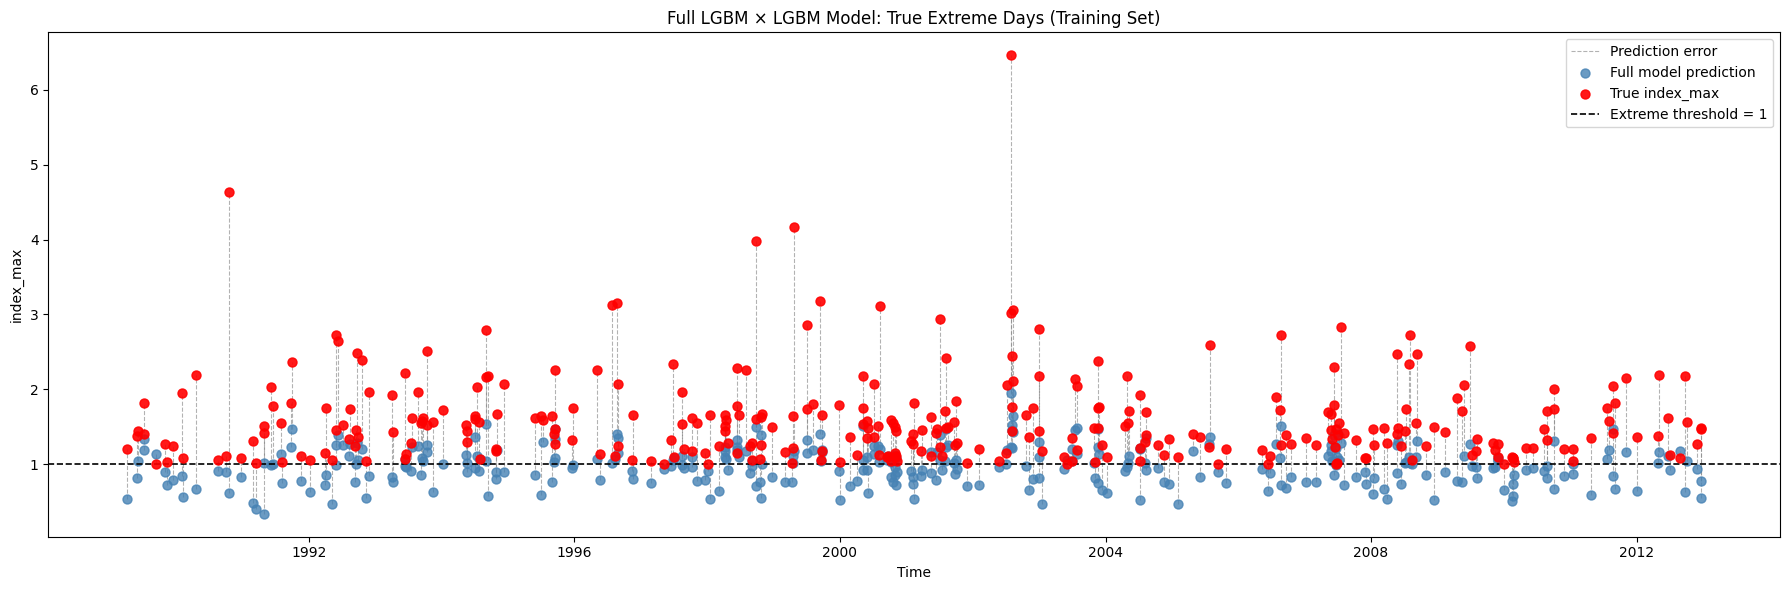

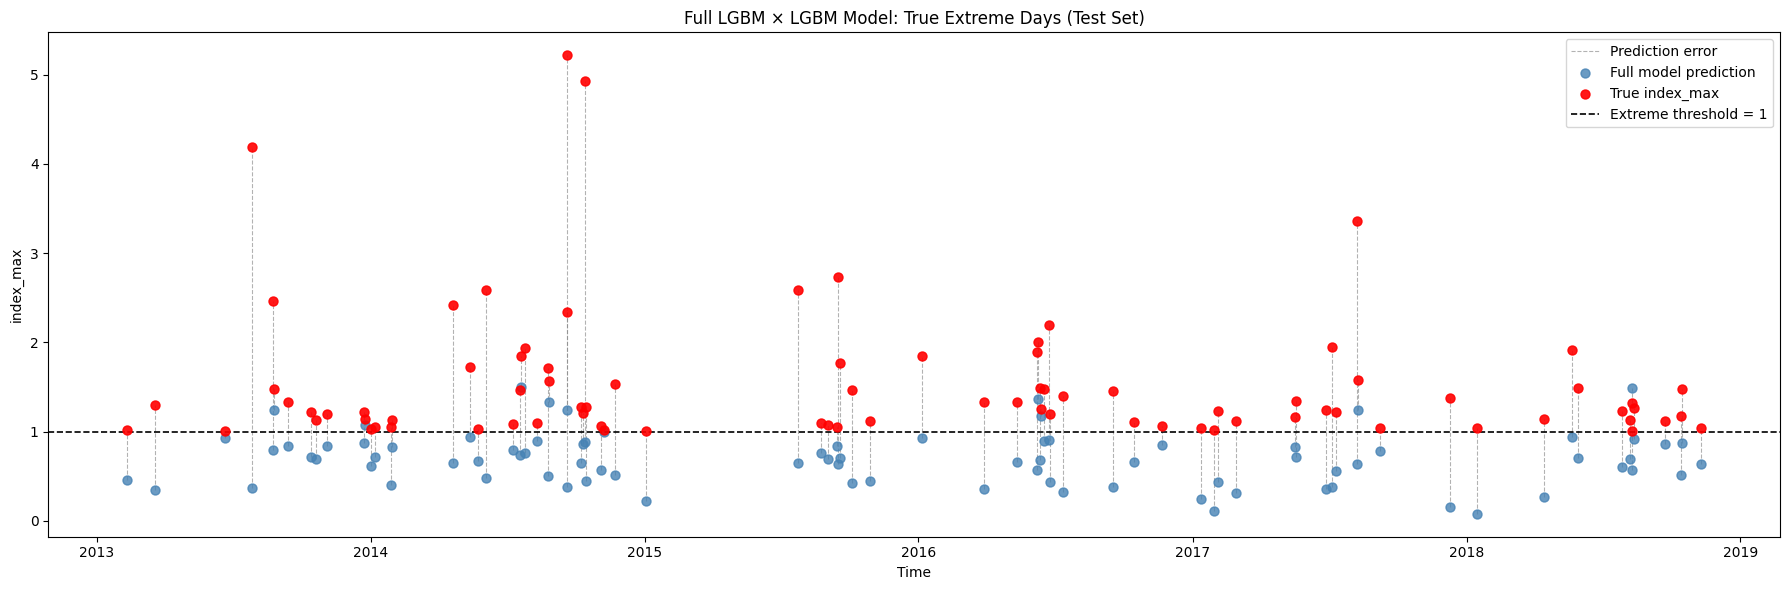


Full Model: True Extreme Days Only
----------------------------------------
 Dataset        Evaluation   N   RMSE    MAE      R2
Training True extreme days 331 0.8110 0.6131 -0.8194
    Test True extreme days  85 1.1838 0.8542 -1.3211


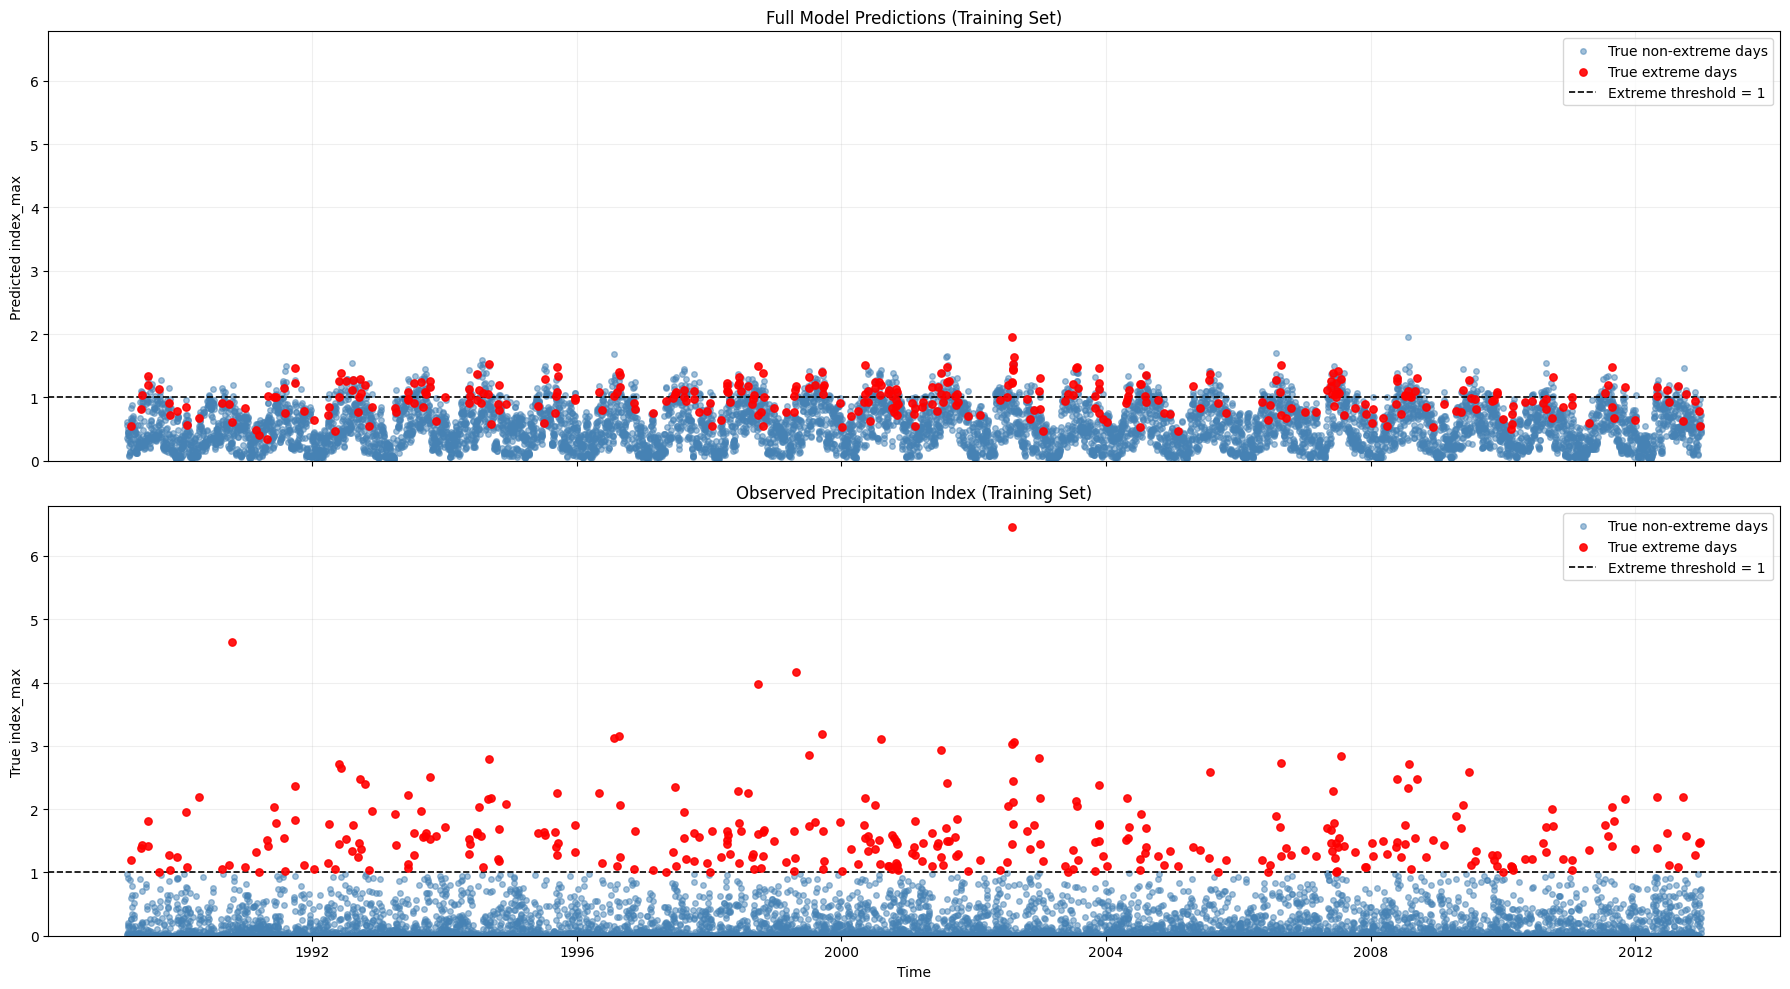

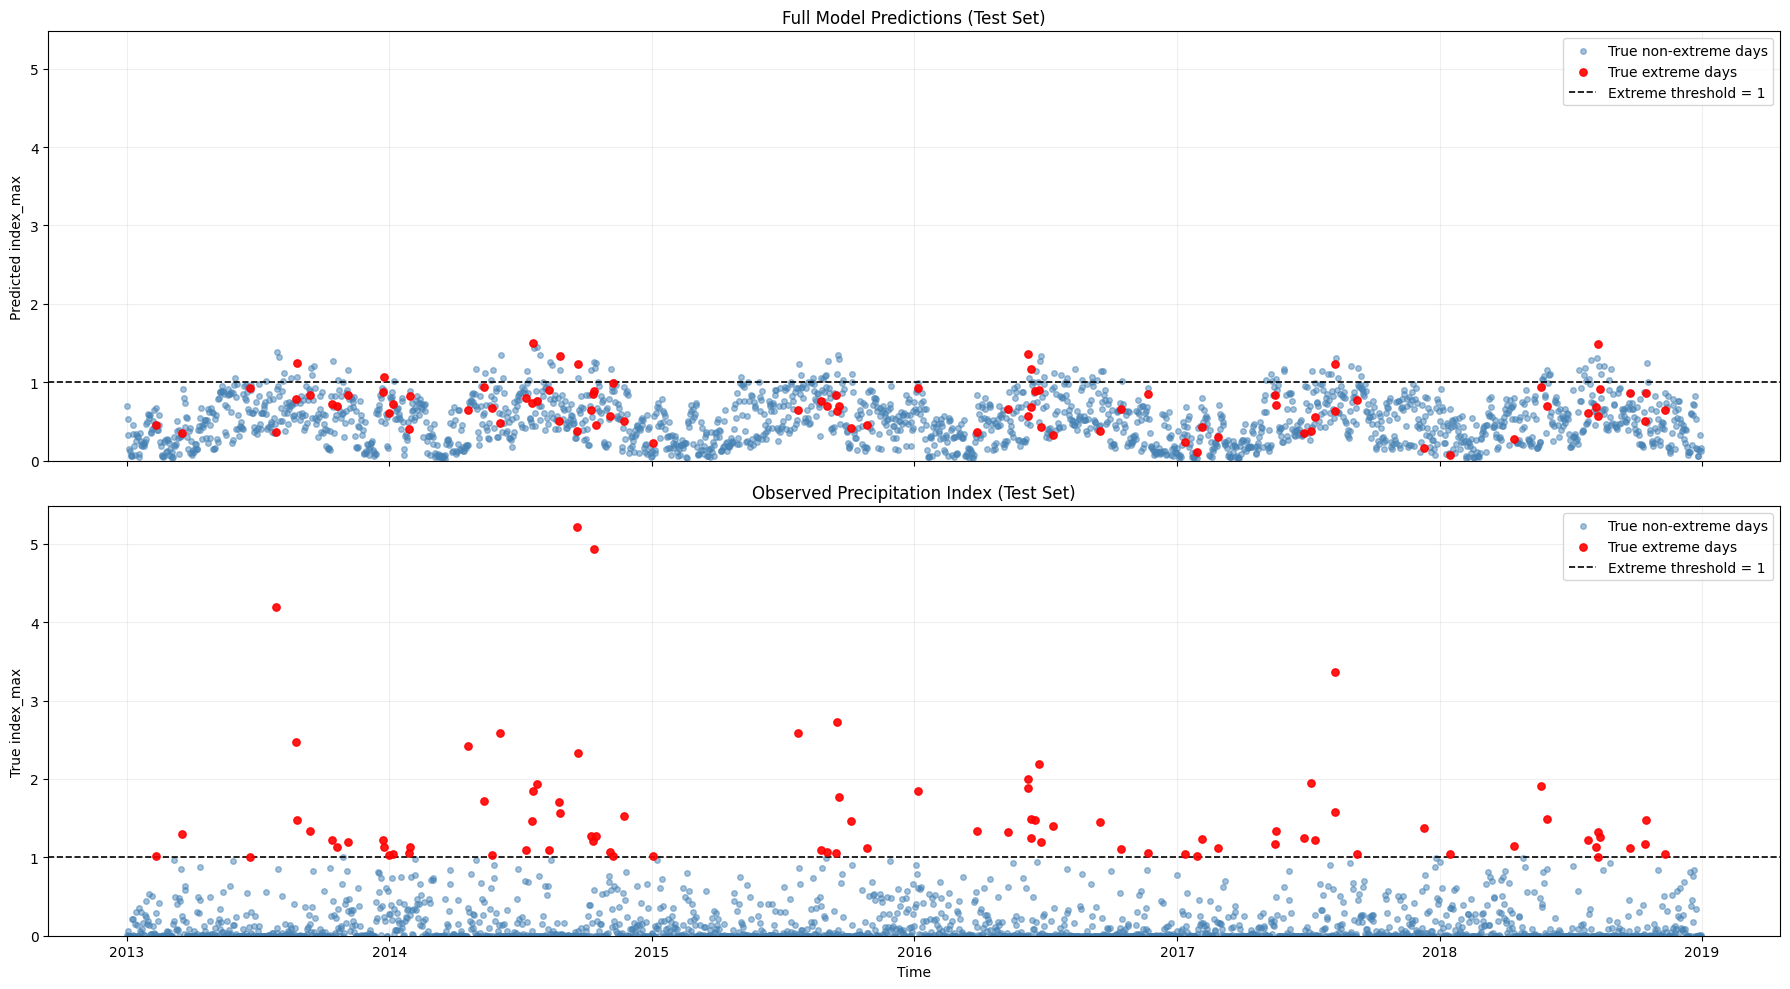


Full Model: All Observations
----------------------------------------
 Dataset       Evaluation    N   RMSE    MAE      R2
Training All observations 8693 0.5538 0.4529 -1.2333
    Test All observations 2191 0.5502 0.4400 -1.1353

FINAL LGBM × LGBM FULL MODEL PERFORMANCE
 Dataset        Evaluation    N   RMSE    MAE      R2
Training True extreme days  331 0.8110 0.6131 -0.8194
    Test True extreme days   85 1.1838 0.8542 -1.3211
Training  All observations 8693 0.5538 0.4529 -1.2333
    Test  All observations 2191 0.5502 0.4400 -1.1353


In [ ]:

# ============================================================
# Full Model: LGBMClassifier × LGBMRegressor
# ============================================================
# ============================================================
# 1. Settings
# ============================================================

target_full = "index_max"
extreme_threshold = 1.0

# Selected features from the two fitted models
features_cls = selected_features_lgbm_final
features_reg = selected_features_lgbm_reg_final

# ============================================================
# 2. Generate full-model predictions
# ============================================================

def predict_full_lgbm(data, dataset_name):

    # Combine feature lists without duplicates
    required_features = list(
        dict.fromkeys(features_cls + features_reg)
    )

    # Check required columns
    missing = [
        col for col in required_features + [target_full]
        if col not in data.columns
    ]

    if missing:
        raise KeyError(
            f"Missing columns in {dataset_name}: {missing}"
        )

    # Keep complete observations
    df = data[
        required_features + [target_full]
    ].dropna().sort_index().copy()

    # ----------------------------------------
    # Stage 1: Classification probabilities
    # ----------------------------------------

    X_cls = df[features_cls]

    p_extreme = lgbm_clf_final.predict_proba(
        X_cls
    )[:, 1]

    # ----------------------------------------
    # Stage 2: Regression predictions
    # Predict for ALL observations
    # ----------------------------------------

    X_reg = df[features_reg]

    pred_log = lgbm_reg_stage2.predict(
        X_reg
    )

    pred_intensity = np.expm1(pred_log)

    pred_intensity = np.maximum(
        pred_intensity, 0
    )

    # ----------------------------------------
    # Full Model
    # ----------------------------------------

    pred_full = p_extreme * pred_intensity

    df["p_extreme"] = p_extreme
    df["pred_intensity"] = pred_intensity
    df["pred_full"] = pred_full

    # True extreme-event label
    df["true_extreme"] = (
        df[target_full] > extreme_threshold
    ).astype(int)

    print(f"\n{dataset_name} prediction summary")
    print("--------------------------------")
    print("Total observations:", len(df))
    print(
        "True extreme observations:",
        df["true_extreme"].sum()
    )

    return df


# Training predictions
full_train = predict_full_lgbm(
    train, "Training"
)

# Test predictions
full_test = predict_full_lgbm(
    test, "Test"
)


# ============================================================
# 3. Evaluation function
# ============================================================

def calculate_full_metrics(
    df,
    dataset_name,
    evaluation_scope
):

    y_true = df[target_full].to_numpy()
    y_pred = df["pred_full"].to_numpy()

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    mae = mean_absolute_error(
        y_true, y_pred
    )

    r2 = (
        r2_score(y_true, y_pred)
        if len(df) >= 2
        else np.nan
    )

    return {
        "Dataset": dataset_name,
        "Evaluation": evaluation_scope,
        "N": len(df),
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }


# ============================================================
# PART A: TRUE EXTREME DAYS ONLY
# ============================================================

# ============================================================
# 4. Extract true extreme observations
# ============================================================

full_train_extreme = full_train[
    full_train["true_extreme"] == 1
].copy()

full_test_extreme = full_test[
    full_test["true_extreme"] == 1
].copy()


# ============================================================
# 5. Plot true vs predicted values
#    True extreme days only
# ============================================================

def plot_full_extreme(df, dataset_name):

    y_true = df[target_full].to_numpy()
    y_pred = df["pred_full"].to_numpy()

    plt.figure(figsize=(18, 6))

    # Prediction errors
    plt.vlines(
        x=df.index,
        ymin=np.minimum(y_true, y_pred),
        ymax=np.maximum(y_true, y_pred),
        colors="grey",
        linestyles="--",
        linewidth=0.8,
        alpha=0.6,
        label="Prediction error",
        zorder=1
    )

    # Full-model predictions
    plt.scatter(
        df.index,
        y_pred,
        color="steelblue",
        s=42,
        alpha=0.8,
        label="Full model prediction",
        zorder=2
    )

    # True values
    plt.scatter(
        df.index,
        y_true,
        color="red",
        s=42,
        alpha=0.9,
        label="True index_max",
        zorder=3
    )

    # Extreme threshold
    plt.axhline(
        y=1,
        color="black",
        linestyle="--",
        linewidth=1.2,
        label="Extreme threshold = 1"
    )

    plt.xlabel("Time")
    plt.ylabel("index_max")

    plt.title(
        f"Full LGBM × LGBM Model: "
        f"True Extreme Days ({dataset_name} Set)"
    )

    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()


# Training set
plot_full_extreme(
    full_train_extreme,
    "Training"
)

# Test set
plot_full_extreme(
    full_test_extreme,
    "Test"
)


# ============================================================
# 6. Metrics: True extreme days only
# ============================================================

metrics_train_extreme = calculate_full_metrics(
    full_train_extreme,
    "Training",
    "True extreme days"
)

metrics_test_extreme = calculate_full_metrics(
    full_test_extreme,
    "Test",
    "True extreme days"
)

extreme_metrics_summary = pd.DataFrame([
    metrics_train_extreme,
    metrics_test_extreme
])

print("\nFull Model: True Extreme Days Only")
print("----------------------------------------")
print(
    extreme_metrics_summary.round(4).to_string(
        index=False
    )
)


# ============================================================
# PART B: ALL OBSERVATIONS
# ============================================================

# ============================================================
# 7. Plot predictions and true values
#    Two vertically arranged subplots
# ============================================================

def plot_full_all(df, dataset_name):

    non_extreme_mask = (
        df["true_extreme"] == 0
    )

    extreme_mask = (
        df["true_extreme"] == 1
    )

    fig, axes = plt.subplots(
        2, 1,
        figsize=(18, 10),
        sharex=True
    )

    # ----------------------------------------
    # Upper plot: Full-model predictions
    # ----------------------------------------

    axes[0].scatter(
        df.index[non_extreme_mask],
        df.loc[non_extreme_mask, "pred_full"],
        color="steelblue",
        s=16,
        alpha=0.5,
        label="True non-extreme days",
        zorder=2
    )

    axes[0].scatter(
        df.index[extreme_mask],
        df.loc[extreme_mask, "pred_full"],
        color="red",
        s=28,
        alpha=0.9,
        label="True extreme days",
        zorder=3
    )

    axes[0].axhline(
        y=1,
        color="black",
        linestyle="--",
        linewidth=1.2,
        label="Extreme threshold = 1"
    )

    axes[0].set_ylabel(
        "Predicted index_max"
    )

    axes[0].set_title(
        f"Full Model Predictions ({dataset_name} Set)"
    )

    axes[0].legend(loc="upper right")

    # ----------------------------------------
    # Lower plot: True observations
    # ----------------------------------------

    axes[1].scatter(
        df.index[non_extreme_mask],
        df.loc[non_extreme_mask, target_full],
        color="steelblue",
        s=16,
        alpha=0.5,
        label="True non-extreme days",
        zorder=2
    )

    axes[1].scatter(
        df.index[extreme_mask],
        df.loc[extreme_mask, target_full],
        color="red",
        s=28,
        alpha=0.9,
        label="True extreme days",
        zorder=3
    )

    axes[1].axhline(
        y=1,
        color="black",
        linestyle="--",
        linewidth=1.2,
        label="Extreme threshold = 1"
    )

    axes[1].set_xlabel("Time")
    axes[1].set_ylabel("True index_max")

    axes[1].set_title(
        f"Observed Precipitation Index ({dataset_name} Set)"
    )

    axes[1].legend(loc="upper right")

    # Use the same y-axis scale
    ymax = max(
        df[target_full].max(),
        df["pred_full"].max()
    ) * 1.05

    for ax in axes:
        ax.set_ylim(0, ymax)
        ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()


# Training set
plot_full_all(
    full_train,
    "Training"
)

# Test set
plot_full_all(
    full_test,
    "Test"
)


# ============================================================
# 8. Metrics: All observations
# ============================================================

metrics_train_all = calculate_full_metrics(
    full_train,
    "Training",
    "All observations"
)

metrics_test_all = calculate_full_metrics(
    full_test,
    "Test",
    "All observations"
)

all_metrics_summary = pd.DataFrame([
    metrics_train_all,
    metrics_test_all
])

print("\nFull Model: All Observations")
print("----------------------------------------")
print(
    all_metrics_summary.round(4).to_string(
        index=False
    )
)


# ============================================================
# 9. Final performance summary
# ============================================================

full_model_metrics_summary = pd.DataFrame([
    metrics_train_extreme,
    metrics_test_extreme,
    metrics_train_all,
    metrics_test_all
])

print("\n==========================================")
print("FINAL LGBM × LGBM FULL MODEL PERFORMANCE")
print("==========================================")

print(
    full_model_metrics_summary.round(4).to_string(
        index=False
    )
)


# Rolling Forecast

# 1 days ahead

In [ ]:
# ============================================================
# Restore date column from DataFrame index
# ============================================================


print("Original index type:", type(data.index))
print("Original index name:", data.index.name)

# If date is stored in the index, restore it as a column
if "date" not in data.columns:

    if isinstance(data.index, pd.DatetimeIndex):

        data = data.copy()

        data.index.name = "date"

        data = data.reset_index()

    else:

        raise ValueError(
            "The DataFrame has no 'date' column and "
            "its index is not a DatetimeIndex. "
            "Please check how the dates are stored."
        )

# Ensure date is datetime
data["date"] = pd.to_datetime(
    data["date"],
    errors="coerce"
)

# Sort by date
data = (
    data.sort_values("date")
    .reset_index(drop=True)
)

print("\nUpdated columns:")
print(data.columns.tolist())

print("\nFirst five observations:")
print(data[["date", "index_max", "extreme"]].head())

print("\nDate range:")
print(data["date"].min(), "to", data["date"].max())

Original index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Original index name: date

Updated columns:
['date', 'index_max', 'index_mean', 'n_cells', 'extreme', 'year', 'month', 'lag1', 'lag2', 'lag3', 'lag4', 'lag5', 'lag6', 'lag7', 'lag8', 'lag9', 'lag10', 'lag11', 'lag12', 'lag13', 'lag14', 'mean_7d', 'mean_14d', 'mean_30d', 'max_7d', 'max_14d', 'extreme_count_7d', 'extreme_count_30d', 'day_of_year', 'sin_doy', 'cos_doy', 'sin_month', 'cos_month', 'days_since_extreme99']

First five observations:
        date     index_max  extreme
0 1989-01-01  1.537327e-03        0
1 1989-01-02  4.675346e-07        0
2 1989-01-03  8.453556e-04        0
3 1989-01-04  1.296219e-02        0
4 1989-01-05  5.992232e-01        0

Date range:
1989-01-01 00:00:00 to 2018-12-31 00:00:00


h=1 Expanding-Window Rolling Forecast
Forecast horizon: 1
Test start: 2014-01-01 00:00:00
Test end: 2018-12-31 00:00:00
Candidate features: 29
Selected features per stage: 15
Rolling prediction days: 1826
Completed 1/1826 | Origin: 2013-12-31 | Target: 2014-01-01
Completed 100/1826 | Origin: 2014-04-09 | Target: 2014-04-10
Completed 200/1826 | Origin: 2014-07-18 | Target: 2014-07-19
Completed 300/1826 | Origin: 2014-10-26 | Target: 2014-10-27
Completed 400/1826 | Origin: 2015-02-03 | Target: 2015-02-04
Completed 500/1826 | Origin: 2015-05-14 | Target: 2015-05-15
Completed 600/1826 | Origin: 2015-08-22 | Target: 2015-08-23
Completed 700/1826 | Origin: 2015-11-30 | Target: 2015-12-01
Completed 800/1826 | Origin: 2016-03-09 | Target: 2016-03-10
Completed 900/1826 | Origin: 2016-06-17 | Target: 2016-06-18
Completed 1000/1826 | Origin: 2016-09-25 | Target: 2016-09-26
Completed 1100/1826 | Origin: 2017-01-03 | Target: 2017-01-04
Completed 1200/1826 | Origin: 2017-04-13 | Target: 2017-04-14
C

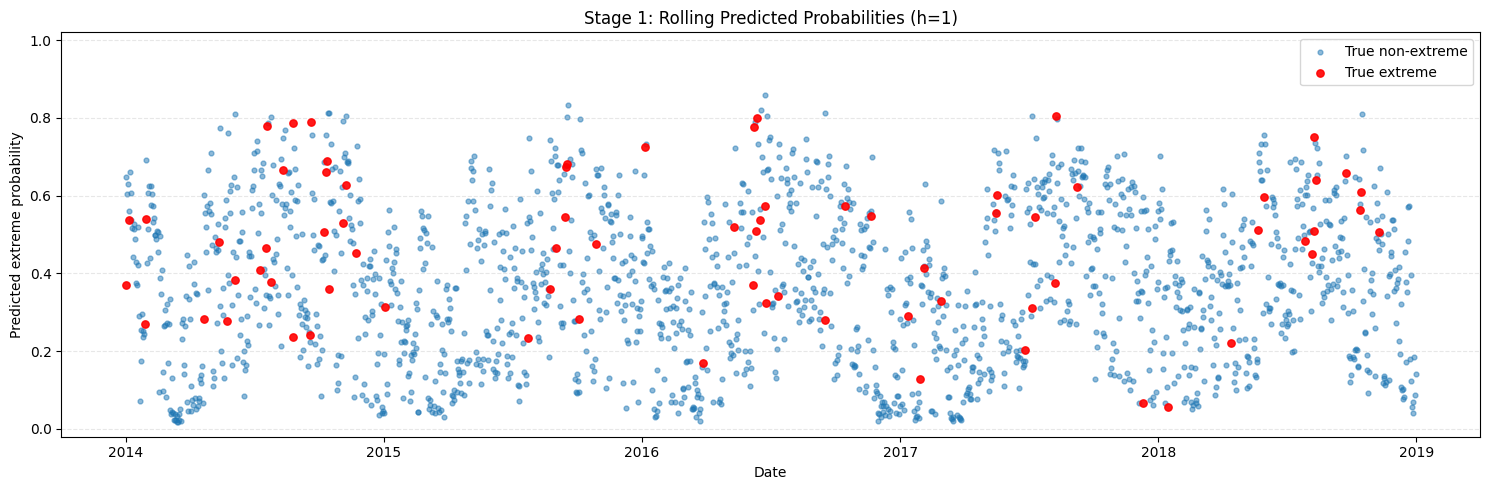

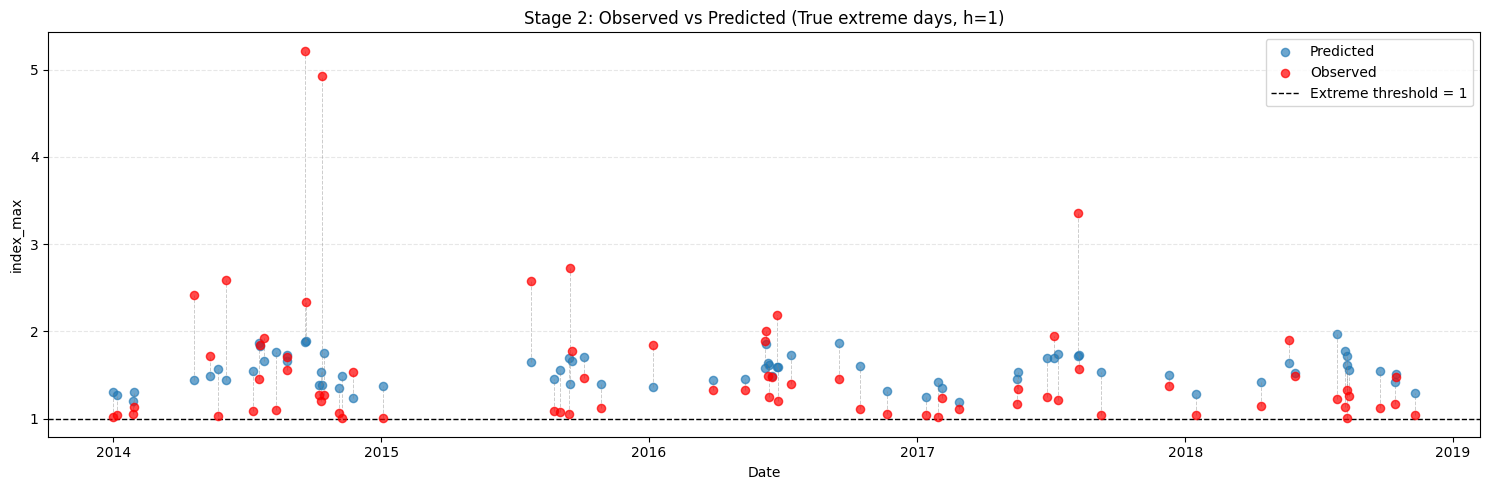

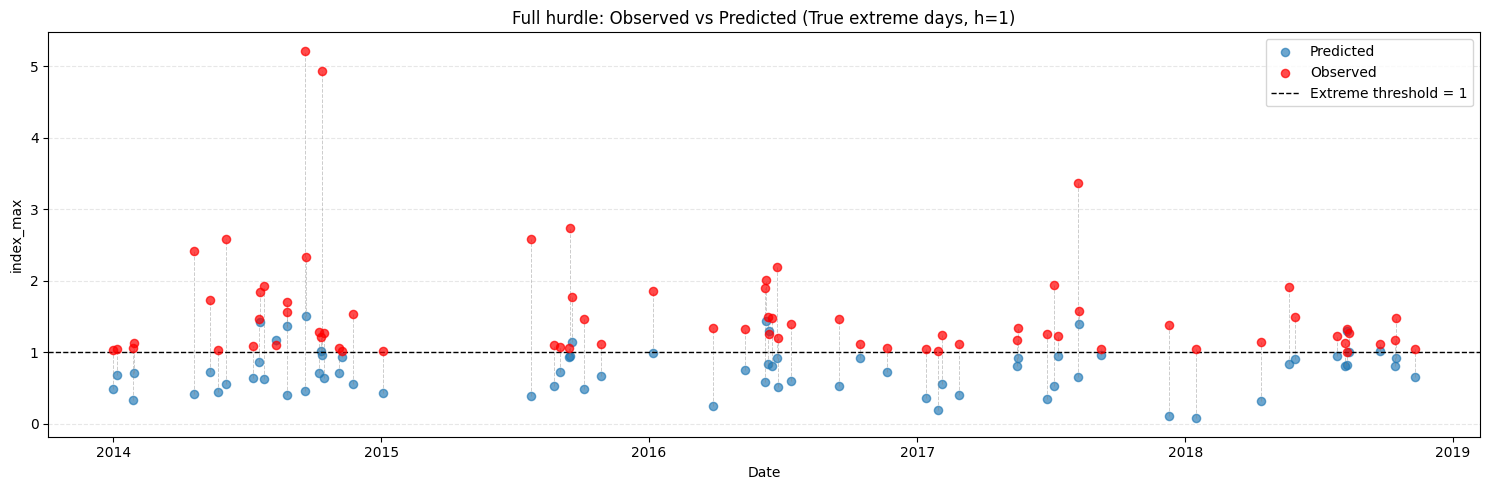

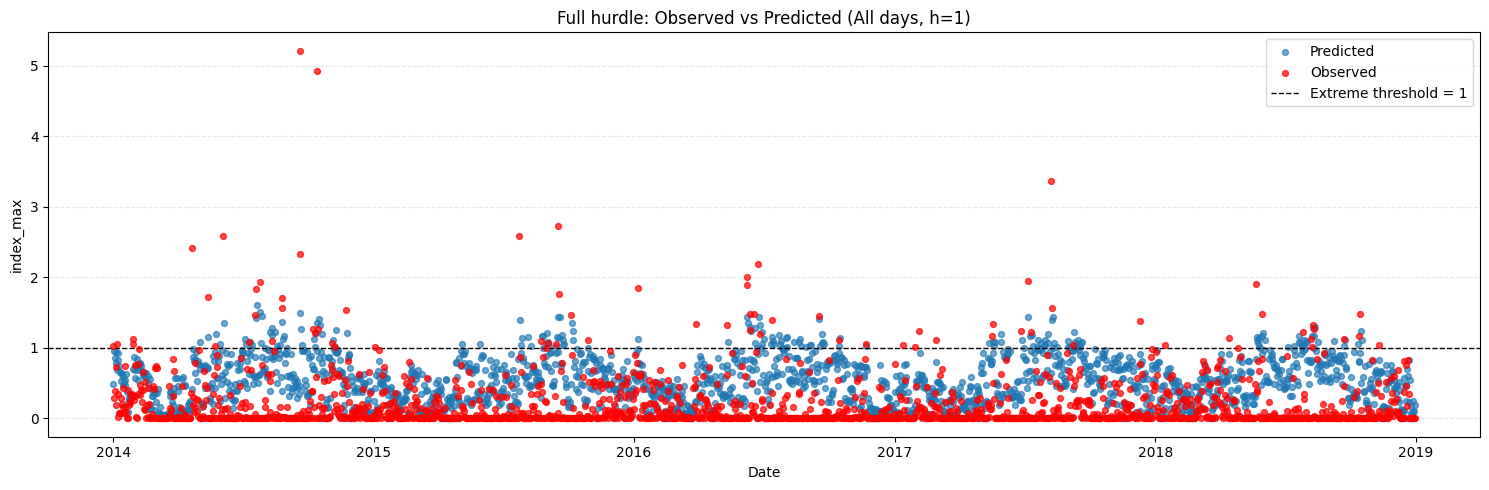

In [ ]:

# ============================================================
# h=1 LightGBM-LightGBM Two-Stage Rolling Forecast
# Test period: 2014-01-01 to the end of the dataset
# Expanding-window training + Gain Top 15 feature selection
# ============================================================
# 1. Settings
# ============================================================

HORIZON = 1
TEST_START = pd.Timestamp("2014-01-01")
TEST_END = None

TOP_K = 15
PROGRESS_EVERY = 100
SAVE_OUTPUTS = True

DATE_COL = "date"
TARGET_COL = "index_max"
EXTREME_COL = "extreme"

# Original Stage 1 hyperparameters
CLASSIFIER_PARAMS = dict(
    objective="binary",
    n_estimators=200,
    learning_rate=0.03,
    num_leaves=7,
    max_depth=3,
    min_child_samples=30,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_alpha=0.5,
    reg_lambda=5.0,
    importance_type="gain",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Original Stage 2 hyperparameters
REGRESSOR_PARAMS = dict(
    objective="regression",
    n_estimators=150,
    learning_rate=0.03,
    num_leaves=7,
    max_depth=3,
    min_child_samples=5,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_alpha=0.5,
    reg_lambda=5.0,
    importance_type="gain",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# ============================================================
# 2. Prepare data
# ============================================================

if "data" not in globals():
    raise NameError("Please load DataFrame 'data' first.")

df = data.copy()

# Automatically restore dates from DatetimeIndex
if DATE_COL not in df.columns:

    if isinstance(df.index, pd.DatetimeIndex):
        df.index.name = DATE_COL
        df = df.reset_index()
    else:
        raise ValueError(
            "No date column or DatetimeIndex found."
        )

df[DATE_COL] = pd.to_datetime(
    df[DATE_COL], errors="raise"
)

df[TARGET_COL] = pd.to_numeric(
    df[TARGET_COL], errors="coerce"
)

df = (
    df.dropna(subset=[DATE_COL, TARGET_COL])
    .sort_values(DATE_COL)
    .reset_index(drop=True)
)

if df[DATE_COL].duplicated().any():
    raise ValueError("Duplicate dates detected.")

# Check daily continuity
expected_dates = pd.date_range(
    df[DATE_COL].min(),
    df[DATE_COL].max(),
    freq="D"
)

if not pd.DatetimeIndex(df[DATE_COL]).equals(
    expected_dates
):
    raise ValueError(
        "Dates must form a continuous daily series."
    )

# Rebuild binary target
df[EXTREME_COL] = (
    df[TARGET_COL] > 1
).astype(int)

df["target_date"] = df[DATE_COL]

df["forecast_origin_date"] = (
    df["target_date"] - pd.Timedelta(days=HORIZON)
)

# ============================================================
# 3. Construct h=1 features
# ============================================================

# Calendar features
df["year"] = df["target_date"].dt.year
df["month"] = df["target_date"].dt.month
df["day_of_year"] = df["target_date"].dt.dayofyear

df["sin_doy"] = np.sin(
    2 * np.pi * df["day_of_year"] / 365.25
)
df["cos_doy"] = np.cos(
    2 * np.pi * df["day_of_year"] / 365.25
)
df["sin_month"] = np.sin(
    2 * np.pi * df["month"] / 12
)
df["cos_month"] = np.cos(
    2 * np.pi * df["month"] / 12
)

calendar_features = [
    "year", "month", "day_of_year",
    "sin_doy", "cos_doy",
    "sin_month", "cos_month"
]

# Lag1 to lag14
lag_features = [
    f"lag{i}" for i in range(1, 15)
]

for lag in range(1, 15):
    df[f"lag{lag}"] = df[TARGET_COL].shift(lag)

# Historical data available at t-1
known_index = df[TARGET_COL].shift(HORIZON)
known_event = df[EXTREME_COL].shift(HORIZON)

rolling_features = []

# Rolling means
for window in [7, 14, 30]:

    name = f"mean_{window}d_tminus{HORIZON}"

    df[name] = known_index.rolling(
        window=window,
        min_periods=window
    ).mean()

    rolling_features.append(name)

# Rolling maxima
for window in [7, 14]:

    name = f"max_{window}d_tminus{HORIZON}"

    df[name] = known_index.rolling(
        window=window,
        min_periods=window
    ).max()

    rolling_features.append(name)

# Extreme counts
for window in [7, 30]:

    name = f"extreme_count_{window}d_tminus{HORIZON}"

    df[name] = known_event.rolling(
        window=window,
        min_periods=window
    ).sum()

    rolling_features.append(name)

# Days since the last known extreme
last_event = (
    df[DATE_COL]
    .where(df[EXTREME_COL].eq(1))
    .ffill()
    .shift(HORIZON)
)

recency_feature = (
    f"days_since_extreme99_tminus{HORIZON}"
)

df[recency_feature] = (
    df["forecast_origin_date"] - last_event
).dt.days.astype(float)

FEATURES = (
    calendar_features
    + lag_features
    + rolling_features
    + [recency_feature]
)

for feature in FEATURES:
    df[feature] = pd.to_numeric(
        df[feature],
        errors="coerce"
    )

df = df.dropna(
    subset=FEATURES + [TARGET_COL, EXTREME_COL]
).reset_index(drop=True)

# ============================================================
# 4. Define rolling prediction period
# ============================================================

if TEST_END is None:
    TEST_END = df["target_date"].max()
else:
    TEST_END = pd.Timestamp(TEST_END)

rolling_test = df.loc[
    (df["target_date"] >= TEST_START)
    & (df["target_date"] <= TEST_END)
].copy()

if rolling_test.empty:
    raise ValueError("No test observations available.")

print("=" * 65)
print("h=1 Expanding-Window Rolling Forecast")
print("=" * 65)

print("Forecast horizon:", HORIZON)
print("Test start:", rolling_test["target_date"].min())
print("Test end:", rolling_test["target_date"].max())
print("Candidate features:", len(FEATURES))
print("Selected features per stage:", TOP_K)
print("Rolling prediction days:", len(rolling_test))

# ============================================================
# 5. Model training with Gain Top 15 selection
# ============================================================

def fit_hurdle_models(history):

    # -----------------------------
    # Stage 1: Classification
    # -----------------------------

    y_cls = history[EXTREME_COL].astype(int)

    n_positive = int(y_cls.sum())
    n_negative = int((y_cls == 0).sum())

    if n_positive < 2 or n_negative < 2:
        raise ValueError(
            "Insufficient positive or negative samples."
        )

    cls_params = {
        **CLASSIFIER_PARAMS,
        "scale_pos_weight": n_negative / n_positive
    }

    # Initial classifier: all candidate features
    cls_initial = LGBMClassifier(**cls_params)

    cls_initial.fit(
        history[FEATURES],
        y_cls
    )

    cls_gain = pd.Series(
        cls_initial.feature_importances_,
        index=FEATURES
    ).sort_values(
        ascending=False,
        kind="stable"
    )

    cls_selected = (
        cls_gain.head(TOP_K).index.tolist()
    )

    # Final classifier
    classifier = LGBMClassifier(**cls_params)

    classifier.fit(
        history[cls_selected],
        y_cls
    )

    # -----------------------------
    # Stage 2: Regression
    # -----------------------------

    extreme_history = history.loc[
        history[EXTREME_COL] == 1
    ].copy()

    # Log-transform the regression target
    y_reg_log = np.log1p(
        extreme_history[TARGET_COL].astype(float)
    )

    # Initial regressor: all candidate features
    reg_initial = LGBMRegressor(
        **REGRESSOR_PARAMS
    )

    reg_initial.fit(
        extreme_history[FEATURES],
        y_reg_log
    )

    reg_gain = pd.Series(
        reg_initial.feature_importances_,
        index=FEATURES
    ).sort_values(
        ascending=False,
        kind="stable"
    )

    reg_selected = (
        reg_gain.head(TOP_K).index.tolist()
    )

    # Final regressor
    regressor = LGBMRegressor(
        **REGRESSOR_PARAMS
    )

    regressor.fit(
        extreme_history[reg_selected],
        y_reg_log
    )

    return (
        classifier,
        regressor,
        cls_selected,
        reg_selected,
        cls_gain,
        reg_gain
    )


def predict_hurdle(models, rows):

    classifier = models[0]
    regressor = models[1]

    cls_selected = models[2]
    reg_selected = models[3]

    # Stage 1 probability
    probability = classifier.predict_proba(
        rows[cls_selected]
    )[:, 1]

    # Stage 2 prediction on log scale
    predicted_log = regressor.predict(
        rows[reg_selected]
    )

    # Inverse log transformation
    intensity = np.maximum(
        0,
        np.expm1(predicted_log)
    )

    # Combined prediction
    combined = probability * intensity

    return probability, intensity, combined

# ============================================================
# 6. Daily expanding-window rolling prediction
# ============================================================

records = []
feature_selection_records = []

total_test_days = len(rolling_test)

for i, (_, test_row) in enumerate(
    rolling_test.iterrows(),
    start=1
):

    target_date = test_row["target_date"]
    origin_date = test_row["forecast_origin_date"]

    # Training data available before target date
    history = df.loc[
        df["target_date"] <= origin_date
    ].copy()

    if history.empty:
        raise ValueError("Empty rolling training set.")

    # Prevent target leakage
    if history["target_date"].max() > origin_date:
        raise ValueError("Potential data leakage.")

    # Refit both stages and reselect features
    models = fit_hurdle_models(history)

    current_row = test_row.to_frame().T.copy()

    current_row[FEATURES] = (
        current_row[FEATURES].astype(float)
    )

    probability, intensity, combined = (
        predict_hurdle(models, current_row)
    )

    records.append({

        "target_date": target_date,

        "forecast_origin_date": origin_date,

        "training_target_end_date":
            history["target_date"].max(),

        "true_extreme":
            int(test_row[EXTREME_COL]),

        "true_index_max":
            float(test_row[TARGET_COL]),

        "predicted_probability":
            float(probability[0]),

        "predicted_conditional_index":
            float(intensity[0]),

        "final_hurdle_prediction":
            float(combined[0]),

        "n_training_samples":
            len(history),

        "n_stage2_extreme_samples":
            int(history[EXTREME_COL].sum())
    })

    # Record selected features
    for stage, selected, gains in [

        ("Stage 1", models[2], models[4]),
        ("Stage 2", models[3], models[5])

    ]:

        for rank, feature in enumerate(
            selected,
            start=1
        ):

            feature_selection_records.append({

                "target_date": target_date,
                "stage": stage,
                "rank": rank,
                "feature": feature,
                "initial_gain": float(gains[feature])
            })

    if (
        i == 1
        or i % PROGRESS_EVERY == 0
        or i == total_test_days
    ):

        print(
            f"Completed {i}/{total_test_days} | "
            f"Origin: {origin_date.date()} | "
            f"Target: {target_date.date()}"
        )

# Rolling prediction results
rolling_predictions_h1 = pd.DataFrame.from_records(
    records
)

selected_features_daily_h1 = pd.DataFrame.from_records(
    feature_selection_records
)

# Check for target leakage
if (
    rolling_predictions_h1["training_target_end_date"]
    > rolling_predictions_h1["forecast_origin_date"]
).any():

    raise AssertionError(
        "Training target leakage detected."
    )

print("\nRolling prediction completed.")

# ============================================================
# 7. Evaluation metrics: 2014 onward only
# ============================================================

def classification_metrics(predictions):

    y_true = predictions[
        "true_extreme"
    ].to_numpy(dtype=int)

    y_prob = predictions[
        "predicted_probability"
    ].to_numpy(dtype=float)

    roc = (
        roc_auc_score(y_true, y_prob)
        if np.unique(y_true).size == 2
        else np.nan
    )

    pr = (
        average_precision_score(y_true, y_prob)
        if np.unique(y_true).size == 2
        else np.nan
    )

    brier = brier_score_loss(
        y_true,
        y_prob
    )

    return {
        "Horizon": HORIZON,
        "N": len(y_true),
        "N_extreme": int(y_true.sum()),
        "ROC_AUC": roc,
        "PR_AUC": pr,
        "Brier": brier
    }


def regression_metrics(
    predictions,
    stage,
    subset
):

    if subset == "All days":
        subset_df = predictions.copy()
    else:
        subset_df = predictions.loc[
            predictions["true_extreme"] == 1
        ].copy()

    y_true = subset_df[
        "true_index_max"
    ].to_numpy(dtype=float)

    if stage == "Stage 2":
        pred_col = "predicted_conditional_index"
    else:
        pred_col = "final_hurdle_prediction"

    y_pred = subset_df[
        pred_col
    ].to_numpy(dtype=float)

    if len(y_true) == 0:

        rmse = np.nan
        mae = np.nan
        r2 = np.nan

    else:

        rmse = np.sqrt(
            mean_squared_error(y_true, y_pred)
        )

        mae = mean_absolute_error(
            y_true, y_pred
        )

        r2 = (
            r2_score(y_true, y_pred)
            if len(y_true) >= 2
            else np.nan
        )

    return {
        "Horizon": HORIZON,
        "Stage": stage,
        "Evaluation": subset,
        "N": len(y_true),
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }


# Stage 1: all rolling prediction days
stage1_metrics_h1 = pd.DataFrame([
    classification_metrics(rolling_predictions_h1)
])

# Stage 2: true extreme days only
stage2_metrics_h1 = pd.DataFrame([
    regression_metrics(
        rolling_predictions_h1,
        "Stage 2",
        "True extreme days"
    )
])

# Full hurdle: two evaluation scopes
full_model_metrics_h1 = pd.DataFrame([

    regression_metrics(
        rolling_predictions_h1,
        "Full hurdle",
        subset
    )

    for subset in [
        "All days",
        "True extreme days"
    ]
])

print("\n" + "=" * 65)
print("STAGE 1: CLASSIFICATION (2014 onward)")
print("=" * 65)

print(
    stage1_metrics_h1.round(4).to_string(index=False)
)

print("\n" + "=" * 65)
print("STAGE 2: TRUE EXTREME DAYS (2014 onward)")
print("=" * 65)

print(
    stage2_metrics_h1.round(4).to_string(index=False)
)

print("\n" + "=" * 65)
print("FULL HURDLE MODEL (2014 onward)")
print("=" * 65)

print(
    full_model_metrics_h1.round(4).to_string(index=False)
)


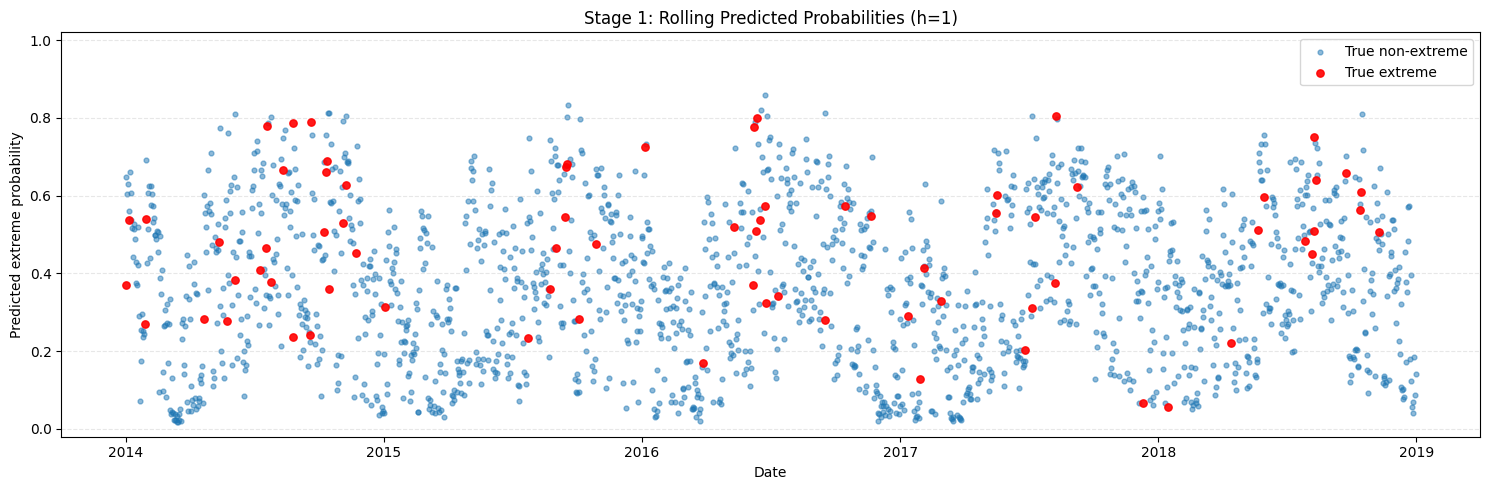

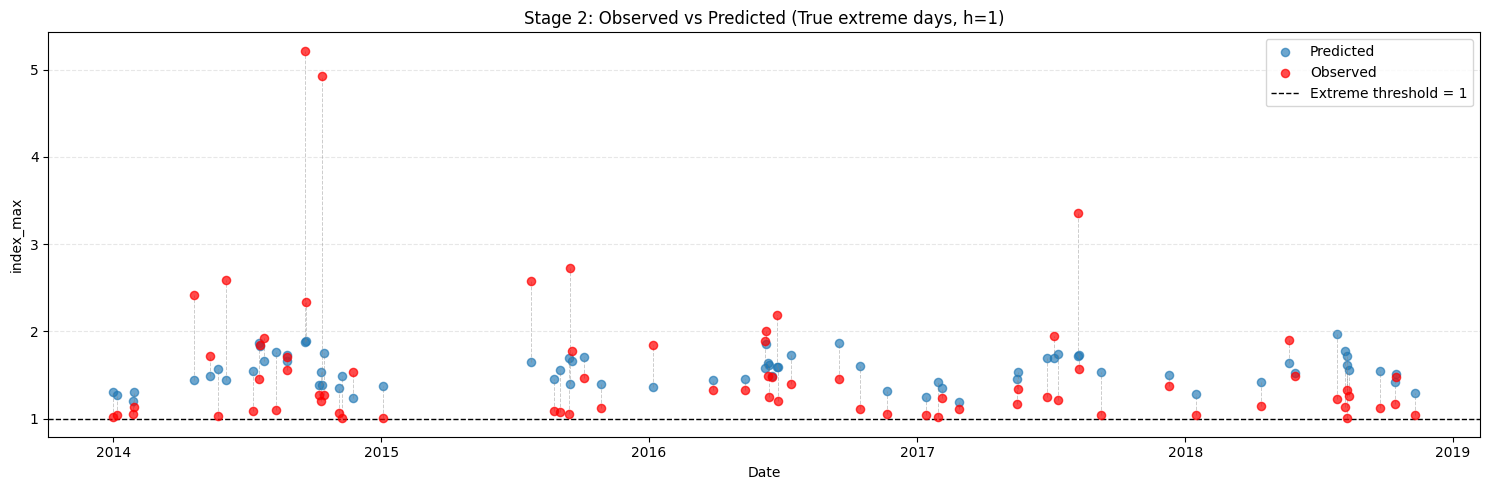

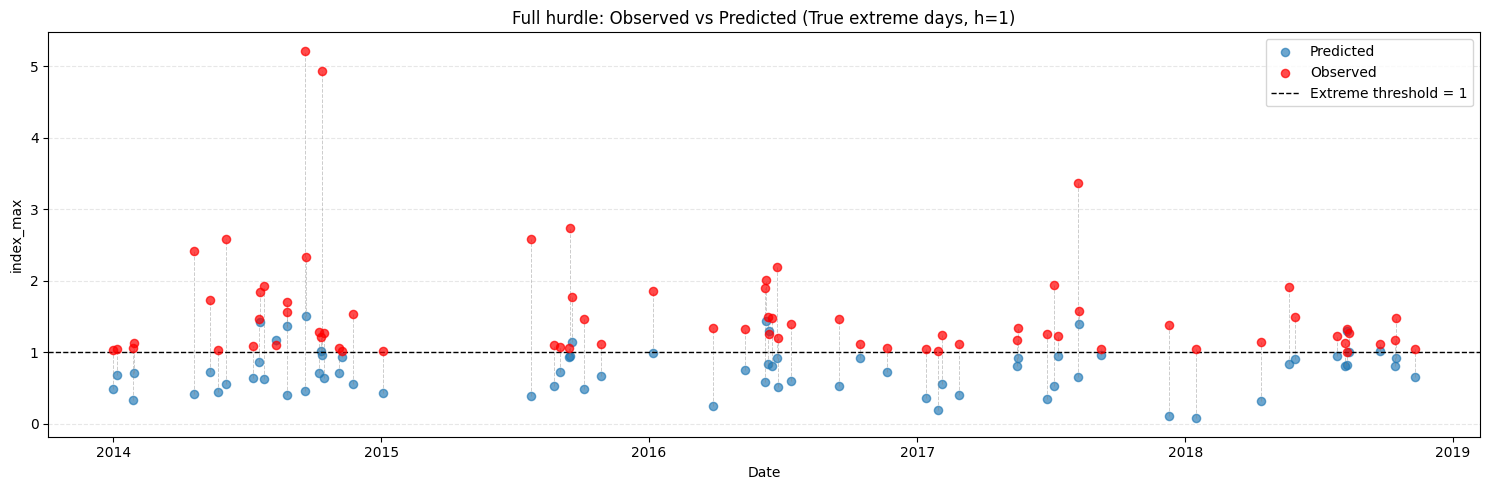

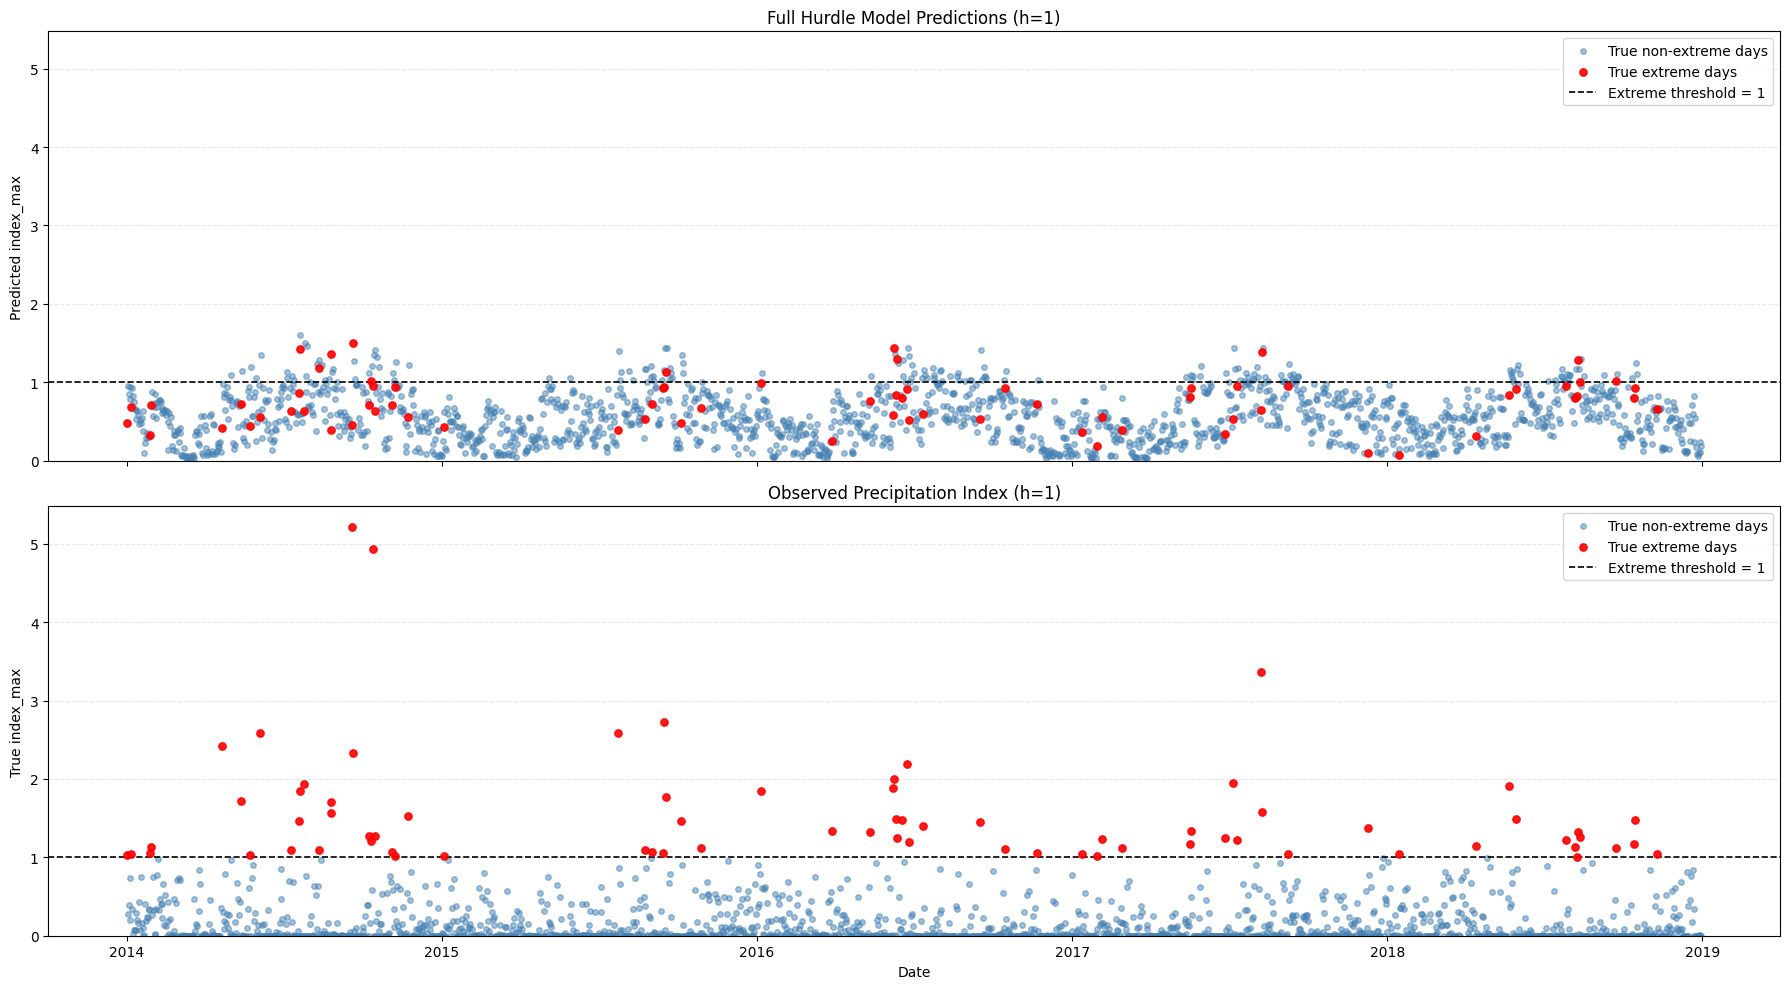

In [ ]:
# ============================================================
# 8. Visualization
# ============================================================

def configure_time_axis(ax):

    locator = mdates.AutoDateLocator()

    ax.xaxis.set_major_locator(locator)

    ax.xaxis.set_major_formatter(
        mdates.ConciseDateFormatter(locator)
    )

    ax.grid(
        axis="y",
        alpha=0.3,
        linestyle="--"
    )


# ------------------------------------------------------------
# Figure 1: Stage 1 predicted probabilities
# ------------------------------------------------------------

def plot_probabilities(frame):

    fig, ax = plt.subplots(figsize=(15, 5))

    non_extreme = frame.loc[
        frame["true_extreme"] == 0
    ]

    extreme = frame.loc[
        frame["true_extreme"] == 1
    ]

    ax.scatter(
        non_extreme["target_date"],
        non_extreme["predicted_probability"],
        s=12,
        alpha=0.5,
        color="tab:blue",
        label="True non-extreme"
    )

    ax.scatter(
        extreme["target_date"],
        extreme["predicted_probability"],
        s=28,
        alpha=0.9,
        color="red",
        label="True extreme",
        zorder=3
    )

    ax.set_ylim(-0.02, 1.02)

    ax.set_xlabel("Date")
    ax.set_ylabel("Predicted extreme probability")

    ax.set_title(
        "Stage 1: Rolling Predicted Probabilities (h=1)"
    )

    configure_time_axis(ax)
    ax.legend()

    fig.tight_layout()
    plt.show()


# ------------------------------------------------------------
# Figures 2-3: Observed vs predicted index_max
# True extreme days only
# ------------------------------------------------------------

def plot_values(frame, stage, subset):

    if subset == "All days":
        chosen = frame.copy()
    else:
        chosen = frame.loc[
            frame["true_extreme"] == 1
        ].copy()

    if chosen.empty:
        print(f"No samples for {stage}: {subset}")
        return

    if stage == "Stage 2":
        pred_col = "predicted_conditional_index"
    else:
        pred_col = "final_hurdle_prediction"

    fig, ax = plt.subplots(figsize=(15, 5))

    # Connect observed and predicted values
    # on true extreme days
    if subset == "True extreme days":

        ax.vlines(
            chosen["target_date"],

            np.minimum(
                chosen["true_index_max"],
                chosen[pred_col]
            ),

            np.maximum(
                chosen["true_index_max"],
                chosen[pred_col]
            ),

            color="gray",
            linestyle="--",
            alpha=0.4,
            linewidth=0.7
        )

    # Predicted values: blue
    ax.scatter(
        chosen["target_date"],
        chosen[pred_col],
        color="tab:blue",
        s=18 if subset == "All days" else 35,
        alpha=0.65,
        label="Predicted"
    )

    # Observed values: red
    ax.scatter(
        chosen["target_date"],
        chosen["true_index_max"],
        color="red",
        s=18 if subset == "All days" else 35,
        alpha=0.7,
        label="Observed",
        zorder=3
    )

    ax.axhline(
        1,
        color="black",
        linestyle="--",
        linewidth=1,
        label="Extreme threshold = 1"
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("index_max")

    ax.set_title(
        f"{stage}: Observed vs Predicted "
        f"({subset}, h=1)"
    )

    configure_time_axis(ax)
    ax.legend()

    fig.tight_layout()
    plt.show()


# ------------------------------------------------------------
# Figure 4: Full hurdle model - All days
# Two vertically arranged subplots
# ------------------------------------------------------------

def plot_full_all_rolling(frame, horizon=1):

    df = frame.copy()

    # Sort observations by target date
    df["target_date"] = pd.to_datetime(
        df["target_date"]
    )

    df = df.sort_values("target_date")

    non_extreme_mask = (
        df["true_extreme"] == 0
    )

    extreme_mask = (
        df["true_extreme"] == 1
    )

    fig, axes = plt.subplots(
        2, 1,
        figsize=(18, 10),
        sharex=True
    )

    # ========================================================
    # Upper plot: Full-model predictions
    # ========================================================

    axes[0].scatter(
        df.loc[non_extreme_mask, "target_date"],
        df.loc[
            non_extreme_mask,
            "final_hurdle_prediction"
        ],
        color="steelblue",
        s=16,
        alpha=0.5,
        label="True non-extreme days",
        zorder=2
    )

    axes[0].scatter(
        df.loc[extreme_mask, "target_date"],
        df.loc[
            extreme_mask,
            "final_hurdle_prediction"
        ],
        color="red",
        s=28,
        alpha=0.9,
        label="True extreme days",
        zorder=3
    )

    axes[0].axhline(
        y=1,
        color="black",
        linestyle="--",
        linewidth=1.2,
        label="Extreme threshold = 1"
    )

    axes[0].set_ylabel(
        "Predicted index_max"
    )

    axes[0].set_title(
        f"Full Hurdle Model Predictions (h={horizon})"
    )

    axes[0].legend(loc="upper right")

    # ========================================================
    # Lower plot: True observations
    # ========================================================

    axes[1].scatter(
        df.loc[non_extreme_mask, "target_date"],
        df.loc[
            non_extreme_mask,
            "true_index_max"
        ],
        color="steelblue",
        s=16,
        alpha=0.5,
        label="True non-extreme days",
        zorder=2
    )

    axes[1].scatter(
        df.loc[extreme_mask, "target_date"],
        df.loc[
            extreme_mask,
            "true_index_max"
        ],
        color="red",
        s=28,
        alpha=0.9,
        label="True extreme days",
        zorder=3
    )

    axes[1].axhline(
        y=1,
        color="black",
        linestyle="--",
        linewidth=1.2,
        label="Extreme threshold = 1"
    )

    axes[1].set_xlabel("Date")

    axes[1].set_ylabel(
        "True index_max"
    )

    axes[1].set_title(
        f"Observed Precipitation Index (h={horizon})"
    )

    axes[1].legend(loc="upper right")

    # ========================================================
    # Shared y-axis scale and formatting
    # ========================================================

    ymax = max(
        df["true_index_max"].max(),
        df["final_hurdle_prediction"].max(),
        1
    ) * 1.05

    for ax in axes:

        ax.set_ylim(0, ymax)

        configure_time_axis(ax)

    fig.tight_layout()
    plt.show()


# ============================================================
# 9. Generate four figures
# ============================================================

# Figure 1: Stage 1 probabilities, all days
plot_probabilities(
    rolling_predictions_h1
)

# Figure 2: Stage 2, true extreme days
plot_values(
    rolling_predictions_h1,
    "Stage 2",
    "True extreme days"
)

# Figure 3: Full hurdle, true extreme days
plot_values(
    rolling_predictions_h1,
    "Full hurdle",
    "True extreme days"
)

# Figure 4: Full hurdle, all days
# Two vertically arranged subplots
plot_full_all_rolling(
    rolling_predictions_h1,
    horizon=1
)


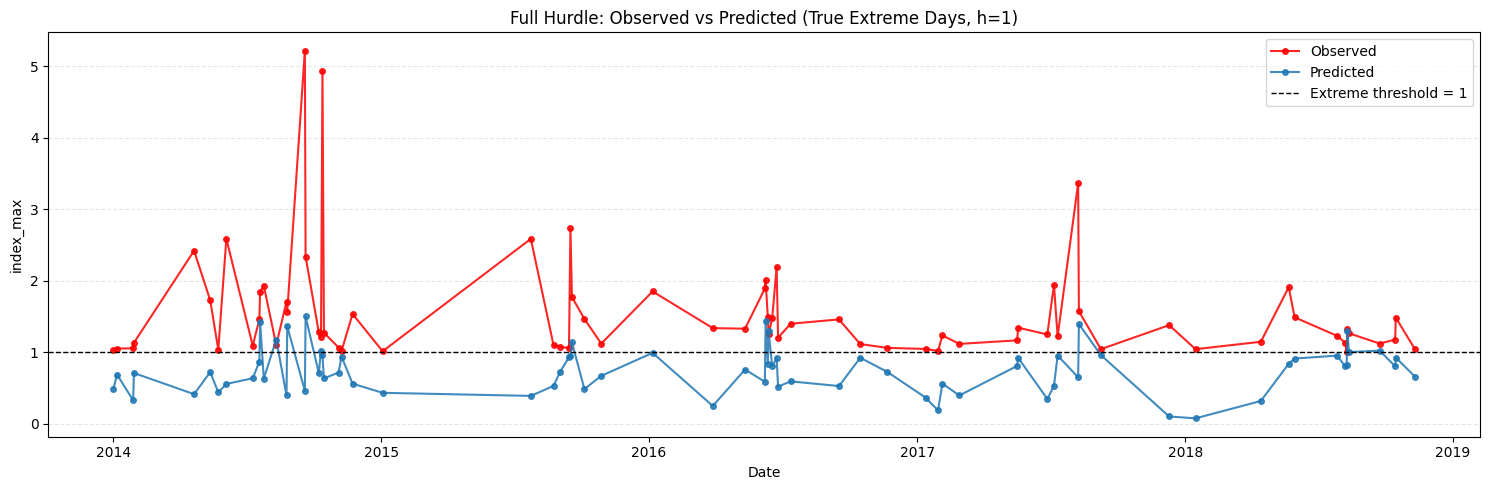

In [ ]:
def plot_full_extreme_line(frame, horizon=1):

    # Select true extreme days only
    chosen = frame.loc[
        frame["true_extreme"] == 1
    ].copy()

    if chosen.empty:
        print("No true extreme samples available.")
        return

    # Convert and sort dates
    chosen["target_date"] = pd.to_datetime(
        chosen["target_date"]
    )

    chosen = chosen.sort_values("target_date")

    fig, ax = plt.subplots(figsize=(15, 5))

    # Observed values: red line
    ax.plot(
        chosen["target_date"],
        chosen["true_index_max"],
        color="red",
        linestyle="-",
        linewidth=1.5,
        marker="o",
        markersize=4,
        alpha=0.85,
        label="Observed"
    )

    # Predicted values: blue line
    ax.plot(
        chosen["target_date"],
        chosen["final_hurdle_prediction"],
        color="tab:blue",
        linestyle="-",
        linewidth=1.5,
        marker="o",
        markersize=4,
        alpha=0.85,
        label="Predicted"
    )

    # Extreme threshold
    ax.axhline(
        y=1,
        color="black",
        linestyle="--",
        linewidth=1,
        label="Extreme threshold = 1"
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("index_max")

    ax.set_title(
        f"Full Hurdle: Observed vs Predicted "
        f"(True Extreme Days, h={horizon})"
    )

    # Date axis formatting
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(
        mdates.ConciseDateFormatter(locator)
    )

    ax.grid(
        axis="y",
        alpha=0.3,
        linestyle="--"
    )

    ax.legend()

    fig.tight_layout()
    plt.show()


# ============================================================
# Generate Figure 3 only
# ============================================================

plot_full_extreme_line(
    rolling_predictions_h1,
    horizon=1
)


# 3 days ahead

In [ ]:
# ============================================================
# h=3 LightGBM-LightGBM Two-Stage Rolling Forecast
# Test period: 2014-01-01 to the end of the dataset
# Expanding-window training + Gain Top 15 feature selection
# ============================================================
# 1. Settings
# ============================================================

HORIZON = 3
TEST_START = pd.Timestamp("2014-01-01")
TEST_END = None

TOP_K = 15
PROGRESS_EVERY = 100
SAVE_OUTPUTS = True

DATE_COL = "date"
TARGET_COL = "index_max"
EXTREME_COL = "extreme"

# Original Stage 1 hyperparameters
CLASSIFIER_PARAMS = dict(
    objective="binary",
    n_estimators=200,
    learning_rate=0.03,
    num_leaves=7,
    max_depth=3,
    min_child_samples=30,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_alpha=0.5,
    reg_lambda=5.0,
    importance_type="gain",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Original Stage 2 hyperparameters
REGRESSOR_PARAMS = dict(
    objective="regression",
    n_estimators=150,
    learning_rate=0.03,
    num_leaves=7,
    max_depth=3,
    min_child_samples=5,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_alpha=0.5,
    reg_lambda=5.0,
    importance_type="gain",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# ============================================================
# 2. Prepare data
# ============================================================

if "data" not in globals():
    raise NameError("Please load DataFrame 'data' first.")

df = data.copy()

# Automatically restore dates from DatetimeIndex
if DATE_COL not in df.columns:

    if isinstance(df.index, pd.DatetimeIndex):
        df.index.name = DATE_COL
        df = df.reset_index()

    else:
        raise ValueError(
            "No date column or DatetimeIndex found."
        )

df[DATE_COL] = pd.to_datetime(
    df[DATE_COL],
    errors="raise"
)

df[TARGET_COL] = pd.to_numeric(
    df[TARGET_COL],
    errors="coerce"
)

df = (
    df.dropna(subset=[DATE_COL, TARGET_COL])
    .sort_values(DATE_COL)
    .reset_index(drop=True)
)

if df[DATE_COL].duplicated().any():
    raise ValueError("Duplicate dates detected.")

# Check daily continuity
expected_dates = pd.date_range(
    df[DATE_COL].min(),
    df[DATE_COL].max(),
    freq="D"
)

if not pd.DatetimeIndex(df[DATE_COL]).equals(
    expected_dates
):
    raise ValueError(
        "Dates must form a continuous daily series."
    )

# Rebuild binary target
df[EXTREME_COL] = (
    df[TARGET_COL] > 1
).astype(int)

df["target_date"] = df[DATE_COL]

df["forecast_origin_date"] = (
    df["target_date"]
    - pd.Timedelta(days=HORIZON)
)

# ============================================================
# 3. Construct h=3 features
# ============================================================

# Calendar features
df["year"] = df["target_date"].dt.year
df["month"] = df["target_date"].dt.month
df["day_of_year"] = df["target_date"].dt.dayofyear

df["sin_doy"] = np.sin(
    2 * np.pi * df["day_of_year"] / 365.25
)

df["cos_doy"] = np.cos(
    2 * np.pi * df["day_of_year"] / 365.25
)

df["sin_month"] = np.sin(
    2 * np.pi * df["month"] / 12
)

df["cos_month"] = np.cos(
    2 * np.pi * df["month"] / 12
)

calendar_features = [
    "year",
    "month",
    "day_of_year",
    "sin_doy",
    "cos_doy",
    "sin_month",
    "cos_month"
]

# Lag3 to lag14
lag_features = [
    f"lag{i}" for i in range(HORIZON, 15)
]

for lag in range(HORIZON, 15):
    df[f"lag{lag}"] = df[TARGET_COL].shift(lag)

# Historical data available at t-3
known_index = df[TARGET_COL].shift(HORIZON)
known_event = df[EXTREME_COL].shift(HORIZON)

rolling_features = []

# Rolling means
for window in [7, 14, 30]:

    name = f"mean_{window}d_tminus{HORIZON}"

    df[name] = known_index.rolling(
        window=window,
        min_periods=window
    ).mean()

    rolling_features.append(name)

# Rolling maxima
for window in [7, 14]:

    name = f"max_{window}d_tminus{HORIZON}"

    df[name] = known_index.rolling(
        window=window,
        min_periods=window
    ).max()

    rolling_features.append(name)

# Historical extreme counts
for window in [7, 30]:

    name = f"extreme_count_{window}d_tminus{HORIZON}"

    df[name] = known_event.rolling(
        window=window,
        min_periods=window
    ).sum()

    rolling_features.append(name)

# Days since the last known extreme
last_event = (
    df[DATE_COL]
    .where(df[EXTREME_COL].eq(1))
    .ffill()
    .shift(HORIZON)
)

recency_feature = (
    f"days_since_extreme99_tminus{HORIZON}"
)

df[recency_feature] = (
    df["forecast_origin_date"] - last_event
).dt.days.astype(float)

FEATURES = (
    calendar_features
    + lag_features
    + rolling_features
    + [recency_feature]
)

for feature in FEATURES:
    df[feature] = pd.to_numeric(
        df[feature],
        errors="coerce"
    )

df = df.dropna(
    subset=FEATURES + [TARGET_COL, EXTREME_COL]
).reset_index(drop=True)

# ============================================================
# 4. Define rolling prediction period
# ============================================================

if TEST_END is None:
    TEST_END = df["target_date"].max()
else:
    TEST_END = pd.Timestamp(TEST_END)

rolling_test = df.loc[
    (df["target_date"] >= TEST_START)
    & (df["target_date"] <= TEST_END)
].copy()

if rolling_test.empty:
    raise ValueError("No test observations available.")

print("=" * 65)
print("h=3 Expanding-Window Rolling Forecast")
print("=" * 65)

print("Forecast horizon:", HORIZON)
print("Test start:", rolling_test["target_date"].min())
print("Test end:", rolling_test["target_date"].max())
print("Candidate features:", len(FEATURES))
print("Selected features per stage:", TOP_K)
print("Rolling prediction days:", len(rolling_test))

# ============================================================
# 5. Model training with Gain Top 15 selection
# ============================================================

def fit_hurdle_models(history):

    # -----------------------------
    # Stage 1: Classification
    # -----------------------------

    y_cls = history[EXTREME_COL].astype(int)

    n_positive = int(y_cls.sum())
    n_negative = int((y_cls == 0).sum())

    if n_positive < 2 or n_negative < 2:
        raise ValueError(
            "Insufficient positive or negative samples."
        )

    cls_params = {
        **CLASSIFIER_PARAMS,
        "scale_pos_weight": n_negative / n_positive
    }

    # Initial classifier: all candidate features
    cls_initial = LGBMClassifier(**cls_params)

    cls_initial.fit(
        history[FEATURES],
        y_cls
    )

    cls_gain = pd.Series(
        cls_initial.feature_importances_,
        index=FEATURES
    ).sort_values(
        ascending=False,
        kind="stable"
    )

    cls_selected = (
        cls_gain.head(TOP_K).index.tolist()
    )

    # Final classifier
    classifier = LGBMClassifier(**cls_params)

    classifier.fit(
        history[cls_selected],
        y_cls
    )

    # -----------------------------
    # Stage 2: Regression
    # -----------------------------

    extreme_history = history.loc[
        history[EXTREME_COL] == 1
    ].copy()

    # Log-transform regression target
    y_reg_log = np.log1p(
        extreme_history[TARGET_COL].astype(float)
    )

    # Initial regressor: all candidate features
    reg_initial = LGBMRegressor(
        **REGRESSOR_PARAMS
    )

    reg_initial.fit(
        extreme_history[FEATURES],
        y_reg_log
    )

    reg_gain = pd.Series(
        reg_initial.feature_importances_,
        index=FEATURES
    ).sort_values(
        ascending=False,
        kind="stable"
    )

    reg_selected = (
        reg_gain.head(TOP_K).index.tolist()
    )

    # Final regressor
    regressor = LGBMRegressor(
        **REGRESSOR_PARAMS
    )

    regressor.fit(
        extreme_history[reg_selected],
        y_reg_log
    )

    return (
        classifier,
        regressor,
        cls_selected,
        reg_selected,
        cls_gain,
        reg_gain
    )


def predict_hurdle(models, rows):

    classifier = models[0]
    regressor = models[1]

    cls_selected = models[2]
    reg_selected = models[3]

    # Stage 1 probability
    probability = classifier.predict_proba(
        rows[cls_selected]
    )[:, 1]

    # Stage 2 prediction on log scale
    predicted_log = regressor.predict(
        rows[reg_selected]
    )

    # Inverse log transformation
    intensity = np.maximum(
        0,
        np.expm1(predicted_log)
    )

    # Combined hurdle prediction
    combined = probability * intensity

    return probability, intensity, combined


# ============================================================
# 6. Daily expanding-window rolling prediction
# ============================================================

records = []
feature_selection_records = []

total_test_days = len(rolling_test)

for i, (_, test_row) in enumerate(
    rolling_test.iterrows(),
    start=1
):

    target_date = test_row["target_date"]
    origin_date = test_row["forecast_origin_date"]

    # Only use observations known at t-3
    history = df.loc[
        df["target_date"] <= origin_date
    ].copy()

    if history.empty:
        raise ValueError("Empty rolling training set.")

    # Prevent target leakage
    if history["target_date"].max() > origin_date:
        raise ValueError("Potential data leakage.")

    # Refit both models and reselect features
    models = fit_hurdle_models(history)

    current_row = test_row.to_frame().T.copy()

    current_row[FEATURES] = (
        current_row[FEATURES].astype(float)
    )

    probability, intensity, combined = (
        predict_hurdle(models, current_row)
    )

    records.append({

        "target_date": target_date,

        "forecast_origin_date": origin_date,

        "training_target_end_date":
            history["target_date"].max(),

        "true_extreme":
            int(test_row[EXTREME_COL]),

        "true_index_max":
            float(test_row[TARGET_COL]),

        "predicted_probability":
            float(probability[0]),

        "predicted_conditional_index":
            float(intensity[0]),

        "final_hurdle_prediction":
            float(combined[0]),

        "n_training_samples":
            len(history),

        "n_stage2_extreme_samples":
            int(history[EXTREME_COL].sum())
    })

    # Record daily selected features
    for stage, selected, gains in [

        ("Stage 1", models[2], models[4]),
        ("Stage 2", models[3], models[5])

    ]:

        for rank, feature in enumerate(
            selected,
            start=1
        ):

            feature_selection_records.append({

                "target_date": target_date,
                "stage": stage,
                "rank": rank,
                "feature": feature,
                "initial_gain": float(gains[feature])
            })

    if (
        i == 1
        or i % PROGRESS_EVERY == 0
        or i == total_test_days
    ):

        print(
            f"Completed {i}/{total_test_days} | "
            f"Origin: {origin_date.date()} | "
            f"Target: {target_date.date()}"
        )

# Rolling prediction results
rolling_predictions_h3 = pd.DataFrame.from_records(
    records
)

selected_features_daily_h3 = pd.DataFrame.from_records(
    feature_selection_records
)

# Check for target leakage
if (
    rolling_predictions_h3["training_target_end_date"]
    > rolling_predictions_h3["forecast_origin_date"]
).any():

    raise AssertionError(
        "Training target leakage detected."
    )

print("\nRolling prediction completed.")

# ============================================================
# 7. Evaluation metrics: 2014 onward only
# ============================================================

def classification_metrics(predictions):

    y_true = predictions[
        "true_extreme"
    ].to_numpy(dtype=int)

    y_prob = predictions[
        "predicted_probability"
    ].to_numpy(dtype=float)

    roc = (
        roc_auc_score(y_true, y_prob)
        if np.unique(y_true).size == 2
        else np.nan
    )

    pr = (
        average_precision_score(y_true, y_prob)
        if np.unique(y_true).size == 2
        else np.nan
    )

    brier = brier_score_loss(
        y_true,
        y_prob
    )

    return {
        "Horizon": HORIZON,
        "N": len(y_true),
        "N_extreme": int(y_true.sum()),
        "ROC_AUC": roc,
        "PR_AUC": pr,
        "Brier": brier
    }


def regression_metrics(
    predictions,
    stage,
    subset
):

    if subset == "All days":
        subset_df = predictions.copy()
    else:
        subset_df = predictions.loc[
            predictions["true_extreme"] == 1
        ].copy()

    y_true = subset_df[
        "true_index_max"
    ].to_numpy(dtype=float)

    if stage == "Stage 2":
        pred_col = "predicted_conditional_index"
    else:
        pred_col = "final_hurdle_prediction"

    y_pred = subset_df[
        pred_col
    ].to_numpy(dtype=float)

    if len(y_true) == 0:

        rmse = np.nan
        mae = np.nan
        r2 = np.nan

    else:

        rmse = np.sqrt(
            mean_squared_error(y_true, y_pred)
        )

        mae = mean_absolute_error(
            y_true,
            y_pred
        )

        r2 = (
            r2_score(y_true, y_pred)
            if len(y_true) >= 2
            else np.nan
        )

    return {
        "Horizon": HORIZON,
        "Stage": stage,
        "Evaluation": subset,
        "N": len(y_true),
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }


# Stage 1: all rolling prediction days
stage1_metrics_h3 = pd.DataFrame([
    classification_metrics(rolling_predictions_h3)
])

# Stage 2: true extreme days only
stage2_metrics_h3 = pd.DataFrame([
    regression_metrics(
        rolling_predictions_h3,
        "Stage 2",
        "True extreme days"
    )
])

# Full hurdle: all days and true extreme days
full_model_metrics_h3 = pd.DataFrame([

    regression_metrics(
        rolling_predictions_h3,
        "Full hurdle",
        subset
    )

    for subset in [
        "All days",
        "True extreme days"
    ]
])

print("\n" + "=" * 65)
print("STAGE 1: CLASSIFICATION (2014 onward)")
print("=" * 65)

print(
    stage1_metrics_h3.round(4).to_string(index=False)
)

print("\n" + "=" * 65)
print("STAGE 2: TRUE EXTREME DAYS (2014 onward)")
print("=" * 65)

print(
    stage2_metrics_h3.round(4).to_string(index=False)
)

print("\n" + "=" * 65)
print("FULL HURDLE MODEL (2014 onward)")
print("=" * 65)

print(
    full_model_metrics_h3.round(4).to_string(index=False)
)

# ============================================================
# 8. Visualization
# ============================================================

def configure_time_axis(ax):

    locator = mdates.AutoDateLocator()

    ax.xaxis.set_major_locator(locator)

    ax.xaxis.set_major_formatter(
        mdates.ConciseDateFormatter(locator)
    )

    ax.grid(
        axis="y",
        alpha=0.3,
        linestyle="--"
    )


# ------------------------------------------------------------
# Figure 1: Stage 1 predicted probabilities
# ------------------------------------------------------------

def plot_probabilities(frame):

    fig, ax = plt.subplots(figsize=(15, 5))

    non_extreme = frame.loc[
        frame["true_extreme"] == 0
    ]

    extreme = frame.loc[
        frame["true_extreme"] == 1
    ]

    ax.scatter(
        non_extreme["target_date"],
        non_extreme["predicted_probability"],
        s=12,
        alpha=0.5,
        color="tab:blue",
        label="True non-extreme"
    )

    ax.scatter(
        extreme["target_date"],
        extreme["predicted_probability"],
        s=28,
        alpha=0.9,
        color="red",
        label="True extreme",
        zorder=3
    )

    ax.set_ylim(-0.02, 1.02)

    ax.set_xlabel("Date")
    ax.set_ylabel("Predicted extreme probability")

    ax.set_title(
        "Stage 1: Rolling Predicted Probabilities (h=3)"
    )

    configure_time_axis(ax)
    ax.legend()

    fig.tight_layout()
    plt.show()


# ------------------------------------------------------------
# Figures 2-4: Observed vs predicted index_max
# ------------------------------------------------------------

def plot_values(frame, stage, subset):

    if subset == "All days":
        chosen = frame.copy()
    else:
        chosen = frame.loc[
            frame["true_extreme"] == 1
        ].copy()

    if chosen.empty:
        print(f"No samples for {stage}: {subset}")
        return

    if stage == "Stage 2":
        pred_col = "predicted_conditional_index"
    else:
        pred_col = "final_hurdle_prediction"

    fig, ax = plt.subplots(figsize=(15, 5))

    # Connect observed and predicted values
    # on true extreme days
    if subset == "True extreme days":

        ax.vlines(
            chosen["target_date"],

            np.minimum(
                chosen["true_index_max"],
                chosen[pred_col]
            ),

            np.maximum(
                chosen["true_index_max"],
                chosen[pred_col]
            ),

            color="gray",
            linestyle="--",
            alpha=0.4,
            linewidth=0.7
        )

    # Predicted values: blue
    ax.scatter(
        chosen["target_date"],
        chosen[pred_col],
        color="tab:blue",
        s=18 if subset == "All days" else 35,
        alpha=0.65,
        label="Predicted"
    )

    # Observed values: red
    ax.scatter(
        chosen["target_date"],
        chosen["true_index_max"],
        color="red",
        s=18 if subset == "All days" else 35,
        alpha=0.7,
        label="Observed",
        zorder=3
    )

    ax.axhline(
        1,
        color="black",
        linestyle="--",
        linewidth=1,
        label="Extreme threshold = 1"
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("index_max")

    ax.set_title(
        f"{stage}: Observed vs Predicted "
        f"({subset}, h=3)"
    )

    configure_time_axis(ax)
    ax.legend()

    fig.tight_layout()
    plt.show()


# ============================================================
# 9. Generate four figures
# ============================================================

# Figure 1: Stage 1 probabilities, all days
plot_probabilities(
    rolling_predictions_h3
)

# Figure 2: Stage 2, true extreme days
plot_values(
    rolling_predictions_h3,
    "Stage 2",
    "True extreme days"
)

# Figure 3: Full hurdle, true extreme days
plot_values(
    rolling_predictions_h3,
    "Full hurdle",
    "True extreme days"
)

# Figure 4: Full hurdle, all days
plot_values(
    rolling_predictions_h3,
    "Full hurdle",
    "All days"
)

# 7 days ahead

In [ ]:
# ============================================================
# h=7 LightGBM-LightGBM Two-Stage Rolling Forecast
# Test period: 2014-01-01 to the end of the dataset
# Expanding-window training + Gain Top 15 feature selection
# ============================================================
# 1. Settings
# ============================================================

HORIZON = 7
TEST_START = pd.Timestamp("2014-01-01")
TEST_END = None

TOP_K = 15
PROGRESS_EVERY = 100
SAVE_OUTPUTS = True

DATE_COL = "date"
TARGET_COL = "index_max"
EXTREME_COL = "extreme"

# Original Stage 1 hyperparameters
CLASSIFIER_PARAMS = dict(
    objective="binary",
    n_estimators=200,
    learning_rate=0.03,
    num_leaves=7,
    max_depth=3,
    min_child_samples=30,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_alpha=0.5,
    reg_lambda=5.0,
    importance_type="gain",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Original Stage 2 hyperparameters
REGRESSOR_PARAMS = dict(
    objective="regression",
    n_estimators=150,
    learning_rate=0.03,
    num_leaves=7,
    max_depth=3,
    min_child_samples=5,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_alpha=0.5,
    reg_lambda=5.0,
    importance_type="gain",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# ============================================================
# 2. Prepare data
# ============================================================

if "data" not in globals():
    raise NameError("Please load DataFrame 'data' first.")

df = data.copy()

# Automatically restore dates from DatetimeIndex
if DATE_COL not in df.columns:

    if isinstance(df.index, pd.DatetimeIndex):
        df.index.name = DATE_COL
        df = df.reset_index()

    else:
        raise ValueError(
            "No date column or DatetimeIndex found."
        )

df[DATE_COL] = pd.to_datetime(
    df[DATE_COL],
    errors="raise"
)

df[TARGET_COL] = pd.to_numeric(
    df[TARGET_COL],
    errors="coerce"
)

df = (
    df.dropna(subset=[DATE_COL, TARGET_COL])
    .sort_values(DATE_COL)
    .reset_index(drop=True)
)

if df[DATE_COL].duplicated().any():
    raise ValueError("Duplicate dates detected.")

# Check daily continuity
expected_dates = pd.date_range(
    df[DATE_COL].min(),
    df[DATE_COL].max(),
    freq="D"
)

if not pd.DatetimeIndex(df[DATE_COL]).equals(
    expected_dates
):
    raise ValueError(
        "Dates must form a continuous daily series."
    )

# Rebuild binary target
df[EXTREME_COL] = (
    df[TARGET_COL] > 1
).astype(int)

df["target_date"] = df[DATE_COL]

df["forecast_origin_date"] = (
    df["target_date"]
    - pd.Timedelta(days=HORIZON)
)

# ============================================================
# 3. Construct h=7 features
# ============================================================

# Calendar features
df["year"] = df["target_date"].dt.year
df["month"] = df["target_date"].dt.month
df["day_of_year"] = df["target_date"].dt.dayofyear

df["sin_doy"] = np.sin(
    2 * np.pi * df["day_of_year"] / 365.25
)

df["cos_doy"] = np.cos(
    2 * np.pi * df["day_of_year"] / 365.25
)

df["sin_month"] = np.sin(
    2 * np.pi * df["month"] / 12
)

df["cos_month"] = np.cos(
    2 * np.pi * df["month"] / 12
)

calendar_features = [
    "year",
    "month",
    "day_of_year",
    "sin_doy",
    "cos_doy",
    "sin_month",
    "cos_month"
]

# Lag7 to lag14
lag_features = [
    f"lag{i}" for i in range(HORIZON, 15)
]

for lag in range(HORIZON, 15):
    df[f"lag{lag}"] = df[TARGET_COL].shift(lag)

# Historical data available at t-7
known_index = df[TARGET_COL].shift(HORIZON)
known_event = df[EXTREME_COL].shift(HORIZON)

rolling_features = []

# Rolling means
for window in [7, 14, 30]:

    name = f"mean_{window}d_tminus{HORIZON}"

    df[name] = known_index.rolling(
        window=window,
        min_periods=window
    ).mean()

    rolling_features.append(name)

# Rolling maxima
for window in [7, 14]:

    name = f"max_{window}d_tminus{HORIZON}"

    df[name] = known_index.rolling(
        window=window,
        min_periods=window
    ).max()

    rolling_features.append(name)

# Historical extreme counts
for window in [7, 30]:

    name = f"extreme_count_{window}d_tminus{HORIZON}"

    df[name] = known_event.rolling(
        window=window,
        min_periods=window
    ).sum()

    rolling_features.append(name)

# Days since the last known extreme
last_event = (
    df[DATE_COL]
    .where(df[EXTREME_COL].eq(1))
    .ffill()
    .shift(HORIZON)
)

recency_feature = (
    f"days_since_extreme99_tminus{HORIZON}"
)

df[recency_feature] = (
    df["forecast_origin_date"] - last_event
).dt.days.astype(float)

FEATURES = (
    calendar_features
    + lag_features
    + rolling_features
    + [recency_feature]
)

for feature in FEATURES:
    df[feature] = pd.to_numeric(
        df[feature],
        errors="coerce"
    )

df = df.dropna(
    subset=FEATURES + [TARGET_COL, EXTREME_COL]
).reset_index(drop=True)

# ============================================================
# 4. Define rolling prediction period
# ============================================================

if TEST_END is None:
    TEST_END = df["target_date"].max()
else:
    TEST_END = pd.Timestamp(TEST_END)

rolling_test = df.loc[
    (df["target_date"] >= TEST_START)
    & (df["target_date"] <= TEST_END)
].copy()

if rolling_test.empty:
    raise ValueError("No test observations available.")

print("=" * 65)
print("h=7 Expanding-Window Rolling Forecast")
print("=" * 65)

print("Forecast horizon:", HORIZON)
print("Test start:", rolling_test["target_date"].min())
print("Test end:", rolling_test["target_date"].max())
print("Candidate features:", len(FEATURES))
print("Selected features per stage:", TOP_K)
print("Rolling prediction days:", len(rolling_test))

# ============================================================
# 5. Model training with Gain Top 15 selection
# ============================================================

def fit_hurdle_models(history):

    # -----------------------------
    # Stage 1: Classification
    # -----------------------------

    y_cls = history[EXTREME_COL].astype(int)

    n_positive = int(y_cls.sum())
    n_negative = int((y_cls == 0).sum())

    if n_positive < 2 or n_negative < 2:
        raise ValueError(
            "Insufficient positive or negative samples."
        )

    cls_params = {
        **CLASSIFIER_PARAMS,
        "scale_pos_weight": n_negative / n_positive
    }

    # Initial classifier: all candidate features
    cls_initial = LGBMClassifier(**cls_params)

    cls_initial.fit(
        history[FEATURES],
        y_cls
    )

    cls_gain = pd.Series(
        cls_initial.feature_importances_,
        index=FEATURES
    ).sort_values(
        ascending=False,
        kind="stable"
    )

    cls_selected = (
        cls_gain.head(TOP_K).index.tolist()
    )

    # Final classifier
    classifier = LGBMClassifier(**cls_params)

    classifier.fit(
        history[cls_selected],
        y_cls
    )

    # -----------------------------
    # Stage 2: Regression
    # -----------------------------

    extreme_history = history.loc[
        history[EXTREME_COL] == 1
    ].copy()

    # Log-transform regression target
    y_reg_log = np.log1p(
        extreme_history[TARGET_COL].astype(float)
    )

    # Initial regressor: all candidate features
    reg_initial = LGBMRegressor(
        **REGRESSOR_PARAMS
    )

    reg_initial.fit(
        extreme_history[FEATURES],
        y_reg_log
    )

    reg_gain = pd.Series(
        reg_initial.feature_importances_,
        index=FEATURES
    ).sort_values(
        ascending=False,
        kind="stable"
    )

    reg_selected = (
        reg_gain.head(TOP_K).index.tolist()
    )

    # Final regressor
    regressor = LGBMRegressor(
        **REGRESSOR_PARAMS
    )

    regressor.fit(
        extreme_history[reg_selected],
        y_reg_log
    )

    return (
        classifier,
        regressor,
        cls_selected,
        reg_selected,
        cls_gain,
        reg_gain
    )


def predict_hurdle(models, rows):

    classifier = models[0]
    regressor = models[1]

    cls_selected = models[2]
    reg_selected = models[3]

    # Stage 1 probability
    probability = classifier.predict_proba(
        rows[cls_selected]
    )[:, 1]

    # Stage 2 prediction on log scale
    predicted_log = regressor.predict(
        rows[reg_selected]
    )

    # Inverse log transformation
    intensity = np.maximum(
        0,
        np.expm1(predicted_log)
    )

    # Combined hurdle prediction
    combined = probability * intensity

    return probability, intensity, combined


# ============================================================
# 6. Daily expanding-window rolling prediction
# ============================================================

records = []
feature_selection_records = []

total_test_days = len(rolling_test)

for i, (_, test_row) in enumerate(
    rolling_test.iterrows(),
    start=1
):

    target_date = test_row["target_date"]
    origin_date = test_row["forecast_origin_date"]

    # Only use observations known at t-7
    history = df.loc[
        df["target_date"] <= origin_date
    ].copy()

    if history.empty:
        raise ValueError("Empty rolling training set.")

    # Prevent target leakage
    if history["target_date"].max() > origin_date:
        raise ValueError("Potential data leakage.")

    # Refit both models and reselect features
    models = fit_hurdle_models(history)

    current_row = test_row.to_frame().T.copy()

    current_row[FEATURES] = (
        current_row[FEATURES].astype(float)
    )

    probability, intensity, combined = (
        predict_hurdle(models, current_row)
    )

    records.append({

        "target_date": target_date,

        "forecast_origin_date": origin_date,

        "training_target_end_date":
            history["target_date"].max(),

        "true_extreme":
            int(test_row[EXTREME_COL]),

        "true_index_max":
            float(test_row[TARGET_COL]),

        "predicted_probability":
            float(probability[0]),

        "predicted_conditional_index":
            float(intensity[0]),

        "final_hurdle_prediction":
            float(combined[0]),

        "n_training_samples":
            len(history),

        "n_stage2_extreme_samples":
            int(history[EXTREME_COL].sum())
    })

    # Record daily selected features
    for stage, selected, gains in [

        ("Stage 1", models[2], models[4]),
        ("Stage 2", models[3], models[5])

    ]:

        for rank, feature in enumerate(
            selected,
            start=1
        ):

            feature_selection_records.append({

                "target_date": target_date,
                "stage": stage,
                "rank": rank,
                "feature": feature,
                "initial_gain": float(gains[feature])
            })

    if (
        i == 1
        or i % PROGRESS_EVERY == 0
        or i == total_test_days
    ):

        print(
            f"Completed {i}/{total_test_days} | "
            f"Origin: {origin_date.date()} | "
            f"Target: {target_date.date()}"
        )

# Rolling prediction results
rolling_predictions_h7 = pd.DataFrame.from_records(
    records
)

selected_features_daily_h7 = pd.DataFrame.from_records(
    feature_selection_records
)

# Check for target leakage
if (
    rolling_predictions_h7["training_target_end_date"]
    > rolling_predictions_h7["forecast_origin_date"]
).any():

    raise AssertionError(
        "Training target leakage detected."
    )

print("\nRolling prediction completed.")

# ============================================================
# 7. Evaluation metrics: 2014 onward only
# ============================================================

def classification_metrics(predictions):

    y_true = predictions[
        "true_extreme"
    ].to_numpy(dtype=int)

    y_prob = predictions[
        "predicted_probability"
    ].to_numpy(dtype=float)

    roc = (
        roc_auc_score(y_true, y_prob)
        if np.unique(y_true).size == 2
        else np.nan
    )

    pr = (
        average_precision_score(y_true, y_prob)
        if np.unique(y_true).size == 2
        else np.nan
    )

    brier = brier_score_loss(
        y_true,
        y_prob
    )

    return {
        "Horizon": HORIZON,
        "N": len(y_true),
        "N_extreme": int(y_true.sum()),
        "ROC_AUC": roc,
        "PR_AUC": pr,
        "Brier": brier
    }


def regression_metrics(
    predictions,
    stage,
    subset
):

    if subset == "All days":
        subset_df = predictions.copy()
    else:
        subset_df = predictions.loc[
            predictions["true_extreme"] == 1
        ].copy()

    y_true = subset_df[
        "true_index_max"
    ].to_numpy(dtype=float)

    if stage == "Stage 2":
        pred_col = "predicted_conditional_index"
    else:
        pred_col = "final_hurdle_prediction"

    y_pred = subset_df[
        pred_col
    ].to_numpy(dtype=float)

    if len(y_true) == 0:

        rmse = np.nan
        mae = np.nan
        r2 = np.nan

    else:

        rmse = np.sqrt(
            mean_squared_error(y_true, y_pred)
        )

        mae = mean_absolute_error(
            y_true,
            y_pred
        )

        r2 = (
            r2_score(y_true, y_pred)
            if len(y_true) >= 2
            else np.nan
        )

    return {
        "Horizon": HORIZON,
        "Stage": stage,
        "Evaluation": subset,
        "N": len(y_true),
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }


# Stage 1: all rolling prediction days
stage1_metrics_h7 = pd.DataFrame([
    classification_metrics(rolling_predictions_h7)
])

# Stage 2: true extreme days only
stage2_metrics_h7 = pd.DataFrame([
    regression_metrics(
        rolling_predictions_h7,
        "Stage 2",
        "True extreme days"
    )
])

# Full hurdle: all days and true extreme days
full_model_metrics_h7 = pd.DataFrame([

    regression_metrics(
        rolling_predictions_h7,
        "Full hurdle",
        subset
    )

    for subset in [
        "All days",
        "True extreme days"
    ]
])

print("\n" + "=" * 65)
print("STAGE 1: CLASSIFICATION (2014 onward)")
print("=" * 65)

print(
    stage1_metrics_h7.round(4).to_string(index=False)
)

print("\n" + "=" * 65)
print("STAGE 2: TRUE EXTREME DAYS (2014 onward)")
print("=" * 65)

print(
    stage2_metrics_h7.round(4).to_string(index=False)
)

print("\n" + "=" * 65)
print("FULL HURDLE MODEL (2014 onward)")
print("=" * 65)

print(
    full_model_metrics_h7.round(4).to_string(index=False)
)

# ============================================================
# 8. Visualization
# ============================================================

def configure_time_axis(ax):

    locator = mdates.AutoDateLocator()

    ax.xaxis.set_major_locator(locator)

    ax.xaxis.set_major_formatter(
        mdates.ConciseDateFormatter(locator)
    )

    ax.grid(
        axis="y",
        alpha=0.3,
        linestyle="--"
    )


# ------------------------------------------------------------
# Figure 1: Stage 1 predicted probabilities
# ------------------------------------------------------------

def plot_probabilities(frame):

    fig, ax = plt.subplots(figsize=(15, 5))

    non_extreme = frame.loc[
        frame["true_extreme"] == 0
    ]

    extreme = frame.loc[
        frame["true_extreme"] == 1
    ]

    ax.scatter(
        non_extreme["target_date"],
        non_extreme["predicted_probability"],
        s=12,
        alpha=0.5,
        color="tab:blue",
        label="True non-extreme"
    )

    ax.scatter(
        extreme["target_date"],
        extreme["predicted_probability"],
        s=28,
        alpha=0.9,
        color="red",
        label="True extreme",
        zorder=3
    )

    ax.set_ylim(-0.02, 1.02)

    ax.set_xlabel("Date")
    ax.set_ylabel("Predicted extreme probability")

    ax.set_title(
        "Stage 1: Rolling Predicted Probabilities (h=7)"
    )

    configure_time_axis(ax)
    ax.legend()

    fig.tight_layout()
    plt.show()


# ------------------------------------------------------------
# Figures 2-4: Observed vs predicted index_max
# ------------------------------------------------------------

def plot_values(frame, stage, subset):

    if subset == "All days":
        chosen = frame.copy()
    else:
        chosen = frame.loc[
            frame["true_extreme"] == 1
        ].copy()

    if chosen.empty:
        print(f"No samples for {stage}: {subset}")
        return

    if stage == "Stage 2":
        pred_col = "predicted_conditional_index"
    else:
        pred_col = "final_hurdle_prediction"

    fig, ax = plt.subplots(figsize=(15, 5))

    # Connect observed and predicted values
    # on true extreme days
    if subset == "True extreme days":

        ax.vlines(
            chosen["target_date"],

            np.minimum(
                chosen["true_index_max"],
                chosen[pred_col]
            ),

            np.maximum(
                chosen["true_index_max"],
                chosen[pred_col]
            ),

            color="gray",
            linestyle="--",
            alpha=0.4,
            linewidth=0.7
        )

    # Predicted values: blue
    ax.scatter(
        chosen["target_date"],
        chosen[pred_col],
        color="tab:blue",
        s=18 if subset == "All days" else 35,
        alpha=0.65,
        label="Predicted"
    )

    # Observed values: red
    ax.scatter(
        chosen["target_date"],
        chosen["true_index_max"],
        color="red",
        s=18 if subset == "All days" else 35,
        alpha=0.7,
        label="Observed",
        zorder=3
    )

    ax.axhline(
        1,
        color="black",
        linestyle="--",
        linewidth=1,
        label="Extreme threshold = 1"
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("index_max")

    ax.set_title(
        f"{stage}: Observed vs Predicted "
        f"({subset}, h=7)"
    )

    configure_time_axis(ax)
    ax.legend()

    fig.tight_layout()
    plt.show()


# ============================================================
# 9. Generate four figures
# ============================================================

# Figure 1: Stage 1 probabilities, all days
plot_probabilities(
    rolling_predictions_h7
)

# Figure 2: Stage 2, true extreme days
plot_values(
    rolling_predictions_h7,
    "Stage 2",
    "True extreme days"
)

# Figure 3: Full hurdle, true extreme days
plot_values(
    rolling_predictions_h7,
    "Full hurdle",
    "True extreme days"
)

# Figure 4: Full hurdle, all days
plot_values(
    rolling_predictions_h7,
    "Full hurdle",
    "All days"
)

# Appendix

In [ ]:
import sys
import importlib.metadata as metadata

# Python version
print("Python:", sys.version.split()[0])
print("Environment: Google Colab")
print("-" * 45)

# Main packages
packages = [
    "numpy",
    "pandas",
    "matplotlib",
    "statsmodels",
    "scikit-learn",
    "xgboost",
    "lightgbm",
    "tensorflow",
    "torch",
    "gpytorch"
]

for package in packages:
    try:
        version = metadata.version(package)
        print(f"{package:<15} {version}")
    except metadata.PackageNotFoundError:
        print(f"{package:<15} Not installed")


Python: 3.13.16
Environment: Google Colab
---------------------------------------------
numpy           2.1.3
pandas          2.2.3
matplotlib      3.10.0
statsmodels     0.15.0
scikit-learn    1.6.1
xgboost         3.4.1
lightgbm        4.6.0
tensorflow      2.21.0
torch           2.11.0+cpu
gpytorch        1.15.2
